# Yachida CRC 2019 Early-Stage Multi-Omics Workflow: Xiaolin Processing + MOFA/XGBoost

The data loading, sample matching, QC, filtering, log transformation, and standardization sections below are preserved from Xiaolin Lai's original notebook. The modeling section is replaced with an early-stage RF/LASSO/XGBoost pipeline plus MOFA+ latent-factor XGBoost.


## Colab setup

Run this cell first in Google Colab. It installs packages that are not always preinstalled and keeps all paths relative to the Colab working directory.


In [1]:
# =========================================================================
# COLAB SETUP
# =========================================================================

import sys
import subprocess
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    subprocess.check_call([
        sys.executable, '-m', 'pip', 'install', '-q',
        'mofapy2', 'statsmodels', 'xgboost', 'h5py'
    ])

PROJECT_ROOT = Path.cwd()
print(f'Working directory: {PROJECT_ROOT}')


Working directory: /content


In [2]:

# =========================================================================
# 0. GLOBAL CONFIGURATION
# =========================================================================

from pathlib import Path
import os
import sys
import math
import subprocess
import warnings
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Ellipse

from scipy.stats import mannwhitneyu, spearmanr
from statsmodels.stats.multitest import multipletests

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegressionCV
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore")
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# Repository and dataset paths
# Colab/local portable paths: everything is relative to PROJECT_ROOT when available.
PROJECT_ROOT = globals().get("PROJECT_ROOT", Path.cwd())
REPO_URL = "https://github.com/borenstein-lab/microbiome-metabolome-curated-data.git"
REPO_DIR = PROJECT_ROOT / "microbiome-metabolome-curated-data"
DATA_DIR = REPO_DIR / "data" / "processed_data" / "YACHIDA_CRC_2019"

# Final Yachida files expected in the curated folder.
# The notebook audits all of them and uses both species and genera metagenomics tables.
FINAL_YACHIDA_FILES = [
    ".RData",
    "metadata.tsv",
    "species.counts.tsv",
    "species.tsv.zip",
    "genera.counts.tsv",
    "genera.tsv",
    "mtb.tsv",
    "mtb.map.tsv",
]

CORE_FILES = {
    "metadata": "metadata.tsv",
    "metabolomics": "mtb.tsv",
    "metabolite_map": "mtb.map.tsv",
}

TAXONOMY_FILES = {
    "species": {
        "counts": "species.counts.tsv",
        "final_table": "species.tsv.zip",
    },
    "genera": {
        "counts": "genera.counts.tsv",
        "final_table": "genera.tsv",
    },
}

# Analysis constants
TARGET_PAIRED_N = 347
PREVALENCE_THRESHOLD = 0.05
MIN_MEAN_REL_ABUNDANCE = 1e-6
TAXA_PSEUDOCOUNT = 1e-6
METABOLITE_PSEUDOCOUNT = 1.0
LOG2FC_THRESHOLD = 0.5
FDR_THRESHOLD = 0.05
N_PCS = 10
TOP_N_CORRELATION_FEATURES = 15
RANDOM_STATE = 42
TEST_SIZE = 0.25
RF_N_ESTIMATORS = 300

# ML feature selection settings.
# These settings prevent high-dimensional p >> n models such as 6,943 species features on 154 samples.
# Important distinction:
#   - candidate_features = all features available after unsupervised preprocessing/filtering.
#   - supervised_features_used = the much smaller number passed from SelectKBest to RF/LASSO.
# The supervised selector is inside each scikit-learn Pipeline, so feature screening is re-fit
# within every cross-validation fold and does not leak test-fold labels into training.
#
# Conservative rule used here for a picky ML review:
#   single-omics models keep at most floor(0.25 * n_samples), capped at 50 taxa or 30 metabolites;
#   combined models keep at most floor(0.50 * n_samples), capped at 75 total features.
# For Healthy_vs_Stage_0 with n=154, species/genera therefore use 38 selected features, not 6,943.
OUTER_CV_SPLITS = 10
INNER_LASSO_CV_SPLITS = 5
ML_MIN_SELECTED_FEATURES = 10
ML_FEATURES_PER_SAMPLE_SINGLE_OMICS = 0.25
ML_FEATURES_PER_SAMPLE_MULTI_OMICS = 0.50
ML_MAX_SELECTED_FEATURES_BY_BLOCK = {
    "species": 50,
    "genera": 50,
    "metabolomics": 30,
    "species_plus_metabolomics": 75,
    "genera_plus_metabolomics": 75,
}

# Output directories
OUT_DIR = PROJECT_ROOT / "yachida_species_genera_complete_outputs"
FIG_DIR = OUT_DIR / "figures"
TABLE_DIR = OUT_DIR / "tables"
ML_DIR = OUT_DIR / "ml_results"
for d in [OUT_DIR, FIG_DIR, TABLE_DIR, ML_DIR]:
    d.mkdir(parents=True, exist_ok=True)

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

print("Configuration complete.")
print(f"Output directory: {OUT_DIR.resolve()}")


Configuration complete.
Output directory: /content/yachida_species_genera_complete_outputs



## 1. Download and audit the final Yachida files

This stage clones or updates the curated repository and verifies that all expected Yachida files are present. The audit table marks which files are used directly in this notebook. The `.RData` file is audited as part of the final file set, while the TSV/ZIP files are used for the Python workflow.


In [3]:

# =========================================================================
# 1. DATASET DOWNLOAD AND FILE AUDIT
# =========================================================================

print("=" * 80)
print("STAGE 1: Downloading and auditing all final Yachida CRC 2019 files")
print("=" * 80)

# Clone the complete curated repository if it is not already available.
# If it already exists, attempt a fast-forward update but continue if the update is unavailable.
if not REPO_DIR.exists():
    print(f"[INFO] Repository not found. Cloning from {REPO_URL} ...")
    subprocess.run(["git", "clone", REPO_URL], check=True)
else:
    print("[INFO] Repository already exists locally.")
    if (REPO_DIR / ".git").exists():
        print("[INFO] Attempting git pull --ff-only to make sure final files are current...")
        pull_result = subprocess.run(
            ["git", "-C", str(REPO_DIR), "pull", "--ff-only"],
            check=False,
            capture_output=True,
            text=True,
        )
        if pull_result.returncode != 0:
            print("[WARNING] git pull did not complete. Continuing with local repository copy.")
            print(pull_result.stderr.strip()[:500])

# Confirm that the Yachida processed-data directory exists.
if not DATA_DIR.exists():
    raise FileNotFoundError(f"Could not find dataset directory: {DATA_DIR}")

# Audit all files present in the Yachida folder.
all_files = sorted([p for p in DATA_DIR.rglob("*") if p.is_file()])
used_python_inputs = {
    CORE_FILES["metadata"],
    CORE_FILES["metabolomics"],
    CORE_FILES["metabolite_map"],
    TAXONOMY_FILES["species"]["counts"],
    TAXONOMY_FILES["species"]["final_table"],
    TAXONOMY_FILES["genera"]["counts"],
    TAXONOMY_FILES["genera"]["final_table"],
}

file_audit_records = []
for path in all_files:
    relative_path = str(path.relative_to(DATA_DIR))
    file_audit_records.append({
        "Relative_Path": relative_path,
        "File_Name": path.name,
        "Size_MB": round(path.stat().st_size / (1024 ** 2), 4),
        "Expected_Final_Yachida_File": path.name in FINAL_YACHIDA_FILES,
        "Used_In_Python_Workflow": path.name in used_python_inputs,
        "Role": (
            "analysis_input" if path.name in used_python_inputs else
            "audited_RData" if path.name == ".RData" else
            "other_file_in_folder"
        ),
    })

df_file_audit = pd.DataFrame(file_audit_records)
df_file_audit.to_csv(TABLE_DIR / "yachida_file_audit.csv", index=False)

missing_final_files = [fname for fname in FINAL_YACHIDA_FILES if not (DATA_DIR / fname).exists()]
if missing_final_files:
    raise FileNotFoundError(f"Missing expected final Yachida files: {missing_final_files}")

print(f"[AUDIT] Number of files found in YACHIDA_CRC_2019: {len(df_file_audit)}")
print(df_file_audit)
print("[OK] All expected final Yachida files were found.")
print("[SUCCESS] File audit completed and saved to tables/yachida_file_audit.csv.")


STAGE 1: Downloading and auditing all final Yachida CRC 2019 files
[INFO] Repository not found. Cloning from https://github.com/borenstein-lab/microbiome-metabolome-curated-data.git ...
[AUDIT] Number of files found in YACHIDA_CRC_2019: 8
        Relative_Path           File_Name  Size_MB  Expected_Final_Yachida_File  Used_In_Python_Workflow            Role
0              .RData              .RData  45.7064                         True                    False   audited_RData
1   genera.counts.tsv   genera.counts.tsv  10.3581                         True                     True  analysis_input
2          genera.tsv          genera.tsv  26.8910                         True                     True  analysis_input
3        metadata.tsv        metadata.tsv   0.0773                         True                     True  analysis_input
4         mtb.map.tsv         mtb.map.tsv   0.0190                         True                     True  analysis_input
5             mtb.tsv             m


## 2. Load species, genera, metabolomics, and metadata; verify sample IDs; create master mapping

This stage loads both metagenomics taxonomic levels:

- `species.counts.tsv` plus audit/ID check for `species.tsv.zip`
- `genera.counts.tsv` plus audit/ID check for `genera.tsv`

The main statistical workflow uses count tables converted to relative abundance, because count tables are appropriate for prevalence and low-abundance filtering. The final abundance tables are still loaded/audited so the code uses both species and genera final files.


In [4]:

# =========================================================================
# 2. DATA LOADING, SAMPLE ID VERIFICATION, AND MASTER SAMPLE MAPPING
# =========================================================================

print("=" * 80)
print("STAGE 2: Loading species, genera, metabolomics, and metadata; verifying IDs")
print("=" * 80)


def read_metadata(meta_path):
    """Load metadata and set Sample as the index when that column exists."""
    preview = pd.read_csv(meta_path, sep="\t", nrows=3)
    if "Sample" in preview.columns:
        meta = pd.read_csv(meta_path, sep="\t", index_col="Sample")
    else:
        meta = pd.read_csv(meta_path, sep="\t", index_col=1)
    meta.index = meta.index.astype(str)
    return meta


def orient_samples_as_rows(df, metadata_ids):
    """Orient a feature table so samples are rows by comparing IDs to metadata."""
    df = df.copy()
    df.index = df.index.astype(str)
    df.columns = df.columns.astype(str)

    index_overlap = len(set(df.index) & metadata_ids)
    column_overlap = len(set(df.columns) & metadata_ids)

    if column_overlap > index_overlap:
        df = df.T
        df.index = df.index.astype(str)
        df.columns = df.columns.astype(str)

    return df


def deduplicate_feature_columns(df, how="sum"):
    """Combine duplicate feature columns if they occur."""
    if not pd.Index(df.columns).duplicated().any():
        return df
    if how == "mean":
        return df.T.groupby(level=0).mean().T
    return df.T.groupby(level=0).sum().T


def read_numeric_feature_table(path, metadata_ids, duplicate_feature_policy="sum"):
    """Read a TSV or zipped TSV feature table, orient samples as rows, and coerce numeric values."""
    compression = "zip" if str(path).endswith(".zip") else None
    df = pd.read_csv(path, sep="\t", index_col=0, compression=compression)
    df = orient_samples_as_rows(df, metadata_ids)
    df = df.loc[~df.index.duplicated(keep="first")].copy()
    df = deduplicate_feature_columns(df, how=duplicate_feature_policy)
    df = df.apply(pd.to_numeric, errors="coerce")
    return df

# Load metadata first so feature tables can be oriented by matching sample IDs.
df_meta_raw = read_metadata(DATA_DIR / CORE_FILES["metadata"])
metadata_ids = set(df_meta_raw.index)

# Identify the clinical group column.
if "Study.Group" in df_meta_raw.columns:
    GROUP_COL = "Study.Group"
elif "Group" in df_meta_raw.columns:
    GROUP_COL = "Group"
else:
    raise KeyError("Could not find a clinical group column named 'Study.Group' or 'Group'.")

# Load metabolomics and metabolite map.
df_mbx_raw = read_numeric_feature_table(
    DATA_DIR / CORE_FILES["metabolomics"],
    metadata_ids,
    duplicate_feature_policy="mean",
)

mtb_map_path = DATA_DIR / CORE_FILES["metabolite_map"]
df_mtb_map = pd.read_csv(mtb_map_path, sep="\t") if mtb_map_path.exists() else pd.DataFrame()
df_mtb_map.to_csv(TABLE_DIR / "metabolite_map_loaded.csv", index=False)

# Load species and genera count tables for the main analysis.
taxa_counts_raw = {}
taxa_final_tables = {}
for level, paths in TAXONOMY_FILES.items():
    counts_path = DATA_DIR / paths["counts"]
    final_table_path = DATA_DIR / paths["final_table"]

    taxa_counts_raw[level] = read_numeric_feature_table(
        counts_path,
        metadata_ids,
        duplicate_feature_policy="sum",
    )

    # Also load the final abundance table for audit/ID verification.
    # This ensures both species.tsv.zip and genera.tsv are actually used by the notebook.
    taxa_final_tables[level] = read_numeric_feature_table(
        final_table_path,
        metadata_ids,
        duplicate_feature_policy="sum",
    )

# Convert indices to strings for exact ID matching.
df_mbx_raw.index = df_mbx_raw.index.astype(str)
for level in taxa_counts_raw:
    taxa_counts_raw[level].index = taxa_counts_raw[level].index.astype(str)
    taxa_final_tables[level].index = taxa_final_tables[level].index.astype(str)

# Verify duplicate sample IDs and feature names.
audit = {
    "Metadata_samples_loaded": df_meta_raw.shape[0],
    "Metabolomics_samples_loaded": df_mbx_raw.shape[0],
    "Metadata_duplicate_sample_ids": int(df_meta_raw.index.duplicated().sum()),
    "Metabolomics_duplicate_sample_ids": int(df_mbx_raw.index.duplicated().sum()),
    "Metabolomics_duplicate_features_after_deduplication": int(pd.Index(df_mbx_raw.columns).duplicated().sum()),
}

for level, df_counts in taxa_counts_raw.items():
    audit[f"{level}_counts_samples_loaded"] = df_counts.shape[0]
    audit[f"{level}_counts_features_loaded"] = df_counts.shape[1]
    audit[f"{level}_counts_duplicate_sample_ids"] = int(df_counts.index.duplicated().sum())
    audit[f"{level}_counts_duplicate_features_after_deduplication"] = int(pd.Index(df_counts.columns).duplicated().sum())
    audit[f"{level}_final_table_samples_loaded"] = taxa_final_tables[level].shape[0]
    audit[f"{level}_final_table_features_loaded"] = taxa_final_tables[level].shape[1]
    audit[f"{level}_counts_vs_final_common_samples"] = len(set(df_counts.index) & set(taxa_final_tables[level].index))

assert audit["Metadata_duplicate_sample_ids"] == 0, "Metadata contains duplicate sample IDs."
assert audit["Metabolomics_duplicate_sample_ids"] == 0, "Metabolomics contains duplicate sample IDs."
for level in taxa_counts_raw:
    assert audit[f"{level}_counts_duplicate_sample_ids"] == 0, f"{level} counts contain duplicate sample IDs."

# Compute sample ID sets and the final paired cohort across metadata, species, genera, and metabolomics.
sample_sets = {
    "metadata": set(df_meta_raw.index),
    "metabolomics": set(df_mbx_raw.index),
    "species_metagenomics": set(taxa_counts_raw["species"].index),
    "genera_metagenomics": set(taxa_counts_raw["genera"].index),
}
paired_ids = sorted(set.intersection(*sample_sets.values()))
all_loaded_ids = sorted(set.union(*sample_sets.values()))

# Create per-sample master mapping table.
master_records = []
for sid in all_loaded_ids:
    record = {
        "Sample_ID": sid,
        "Study_Group": df_meta_raw.loc[sid, GROUP_COL] if sid in df_meta_raw.index else np.nan,
        "Has_Metadata": sid in sample_sets["metadata"],
        "Has_Species_Metagenomics": sid in sample_sets["species_metagenomics"],
        "Has_Genera_Metagenomics": sid in sample_sets["genera_metagenomics"],
        "Has_Metabolomics": sid in sample_sets["metabolomics"],
    }
    record["Is_Paired_All_Datasets"] = all([
        record["Has_Metadata"],
        record["Has_Species_Metagenomics"],
        record["Has_Genera_Metagenomics"],
        record["Has_Metabolomics"],
    ])
    record["In_Analysis_Cohort"] = record["Is_Paired_All_Datasets"]
    master_records.append(record)

df_master_mapping = pd.DataFrame(master_records)
df_master_mapping.to_csv(TABLE_DIR / "master_sample_mapping.csv", index=False)

# Report unmatched sample IDs by missing layer.
unmatched_records = []
for sid in all_loaded_ids:
    missing_layers = [layer for layer, ids in sample_sets.items() if sid not in ids]
    if missing_layers:
        unmatched_records.append({
            "Sample_ID": sid,
            "Missing_Layers": ";".join(missing_layers),
            "Present_Layers": ";".join([layer for layer, ids in sample_sets.items() if sid in ids]),
        })

df_unmatched = pd.DataFrame(unmatched_records)
df_unmatched.to_csv(TABLE_DIR / "unmatched_sample_ids.csv", index=False)

# Add intersection audit information.
audit.update({
    "Common_metadata_species_genera_metabolomics_samples": len(paired_ids),
    "Species_IDs_subset_of_metadata": sample_sets["species_metagenomics"].issubset(sample_sets["metadata"]),
    "Genera_IDs_subset_of_metadata": sample_sets["genera_metagenomics"].issubset(sample_sets["metadata"]),
    "Metabolomics_IDs_subset_of_metadata": sample_sets["metabolomics"].issubset(sample_sets["metadata"]),
    "Any_unmatched_IDs_reported": len(df_unmatched) > 0,
})

df_sample_audit = pd.DataFrame([audit])
df_sample_audit.to_csv(TABLE_DIR / "sample_id_audit_summary.csv", index=False)

# Align all tables to the same paired sample order.
df_meta = df_meta_raw.loc[paired_ids].copy()
df_mbx = df_mbx_raw.loc[paired_ids].copy()
taxa_counts = {level: df.loc[paired_ids].copy() for level, df in taxa_counts_raw.items()}

# Compatibility aliases for code/readability.
df_species_counts = taxa_counts["species"]
df_genera_counts = taxa_counts["genera"]

# Verify final row order consistency across all layers.
assert df_meta.index.equals(df_mbx.index), "Metadata and metabolomics row orders do not match after alignment."
assert df_meta.index.equals(df_species_counts.index), "Metadata and species row orders do not match after alignment."
assert df_meta.index.equals(df_genera_counts.index), "Metadata and genera row orders do not match after alignment."
assert len(paired_ids) == TARGET_PAIRED_N, f"Expected {TARGET_PAIRED_N} paired samples, but found {len(paired_ids)}."

print("[AUDIT] Sample ID audit summary:")
print(df_sample_audit.T)
print("\n[AUDIT] Clinical group counts in the 347 paired analysis cohort:")
print(df_meta[GROUP_COL].value_counts())
print("\n[SUCCESS] Species, genera, metabolomics, metadata, and master mapping are loaded and aligned.")


STAGE 2: Loading species, genera, metabolomics, and metadata; verifying IDs
[AUDIT] Sample ID audit summary:
                                                        0
Metadata_samples_loaded                               347
Metabolomics_samples_loaded                           347
Metadata_duplicate_sample_ids                           0
Metabolomics_duplicate_sample_ids                       0
Metabolomics_duplicate_features_after_deduplica...      0
species_counts_samples_loaded                         347
species_counts_features_loaded                      57702
species_counts_duplicate_sample_ids                     0
species_counts_duplicate_features_after_dedupli...      0
species_final_table_samples_loaded                    347
species_final_table_features_loaded                 57702
species_counts_vs_final_common_samples                347
genera_counts_samples_loaded                          347
genera_counts_features_loaded                       11942
genera_counts_duplica


## 2B. Define the Healthy-vs-disease contrasts

The workflow uses the disease-stage labels present in the paired Yachida metadata. It does not fabricate individual stages when the metadata contains combined labels such as `Stage_I_II` or `Stage_III_IV`.


In [5]:

# =========================================================================
# 2B. FINAL CONTRAST DEFINITIONS AND FEASIBILITY CHECK
# =========================================================================

print("=" * 80)
print("STAGE 2B: Defining Healthy-vs-disease contrasts")
print("=" * 80)

available_groups = sorted(df_meta[GROUP_COL].dropna().astype(str).unique())
available_label_set = set(available_groups)

print("[INFO] Available clinical labels in the paired cohort:")
print(df_meta[GROUP_COL].value_counts())

HEALTHY_ALTERNATIVES = [["Healthy"], ["Control"], ["Normal"]]

FINAL_CONTRAST_ALTERNATIVES = {
    "Healthy_vs_Stage_0": [
        ["Stage_0"], ["Stage0"], ["Stage 0"], ["S0"]
    ],
    "Healthy_vs_Stage_I_II": [
        ["Stage_I_II"], ["Stage I/II"], ["SI/II"], ["Stage_1_2"]
    ],
    "Healthy_vs_Stage_III_IV": [
        ["Stage_III_IV"], ["Stage III/IV"], ["SIII/IV"], ["Stage_3_4"]
    ],
    "Healthy_vs_Invasive_CRC": [
        ["Stage_I_II", "Stage_III_IV"],
        ["Stage I/II", "Stage III/IV"],
        ["SI/II", "SIII/IV"],
    ],
}


def resolve_first_available(alternatives, available_label_set):
    """Return the first label set whose labels are all present in the metadata."""
    for labels in alternatives:
        if all(label in available_label_set for label in labels):
            return labels
    return None

healthy_labels = resolve_first_available(HEALTHY_ALTERNATIVES, available_label_set)
if healthy_labels is None:
    raise ValueError("No Healthy/Control label was found in the metadata.")

ACTIVE_CONTRASTS = {}
contrast_records = []
for contrast_name, disease_alternatives in FINAL_CONTRAST_ALTERNATIVES.items():
    disease_labels = resolve_first_available(disease_alternatives, available_label_set)
    n_a = int(df_meta[GROUP_COL].isin(healthy_labels).sum())

    if disease_labels is None:
        contrast_records.append({
            "Contrast": contrast_name,
            "Status": "unavailable",
            "Group_A_Labels": ";".join(healthy_labels),
            "Group_B_Labels": "",
            "N_Group_A": n_a,
            "N_Group_B": 0,
            "Reason": "The required disease labels are not present in the paired metadata.",
        })
        continue

    n_b = int(df_meta[GROUP_COL].isin(disease_labels).sum())
    if n_b == 0:
        contrast_records.append({
            "Contrast": contrast_name,
            "Status": "unavailable_zero_samples",
            "Group_A_Labels": ";".join(healthy_labels),
            "Group_B_Labels": ";".join(disease_labels),
            "N_Group_A": n_a,
            "N_Group_B": n_b,
            "Reason": "Disease labels were found but no samples were available after paired-sample filtering.",
        })
        continue

    ACTIVE_CONTRASTS[contrast_name] = {
        "Group_A_Labels": healthy_labels,
        "Group_B_Labels": disease_labels,
        "Interpretation": "Healthy controls compared with " + "+".join(disease_labels),
    }

    contrast_records.append({
        "Contrast": contrast_name,
        "Status": "active",
        "Group_A_Labels": ";".join(healthy_labels),
        "Group_B_Labels": ";".join(disease_labels),
        "N_Group_A": n_a,
        "N_Group_B": n_b,
        "Reason": "Final selected project contrast supported by the available metadata labels.",
    })

contrast_feasibility = pd.DataFrame(contrast_records)
contrast_feasibility.to_csv(TABLE_DIR / "contrast_feasibility_table.csv", index=False)

print("\n[CONTRAST FEASIBILITY]")
print(contrast_feasibility)

print("\n[ACTIVE CONTRASTS]")
for name, spec in ACTIVE_CONTRASTS.items():
    print(f"- {name}: {spec['Group_A_Labels']} vs {spec['Group_B_Labels']}")

if not ACTIVE_CONTRASTS:
    raise RuntimeError("No active contrasts are available. Check clinical labels in metadata.")


STAGE 2B: Defining Healthy-vs-disease contrasts
[INFO] Available clinical labels in the paired cohort:
Study.Group
Healthy         127
Stage_I_II       69
Stage_III_IV     54
MP               40
HS               30
Stage_0          27
Name: count, dtype: int64

[CONTRAST FEASIBILITY]
                  Contrast  Status Group_A_Labels           Group_B_Labels  N_Group_A  N_Group_B                                             Reason
0       Healthy_vs_Stage_0  active        Healthy                  Stage_0        127         27  Final selected project contrast supported by t...
1    Healthy_vs_Stage_I_II  active        Healthy               Stage_I_II        127         69  Final selected project contrast supported by t...
2  Healthy_vs_Stage_III_IV  active        Healthy             Stage_III_IV        127         54  Final selected project contrast supported by t...
3  Healthy_vs_Invasive_CRC  active        Healthy  Stage_I_II;Stage_III_IV        127        123  Final selected project co


## 3A. Missing-value QC and metabolite distribution checks

This stage explicitly checks missing values in species counts, genera counts, and metabolomics. It also generates metabolite distribution summaries and plots before preprocessing.


STAGE 3A: Missing values and metabolite distributions
[QC] Missing-value summary:
              Dataset  Samples  Features  Total_Cells  Missing_Cells  Missing_Fraction  Features_With_Any_Missing  Samples_With_Any_Missing
0  species_counts_raw      347     57702     20022594              0               0.0                          0                         0
1   genera_counts_raw      347     11942      4143874              0               0.0                          0                         0
2    metabolomics_raw      347       450       156150              0               0.0                          0                         0


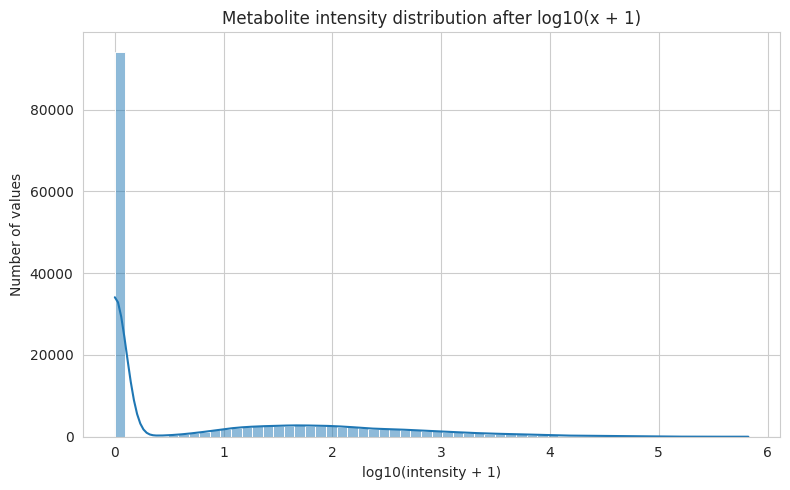

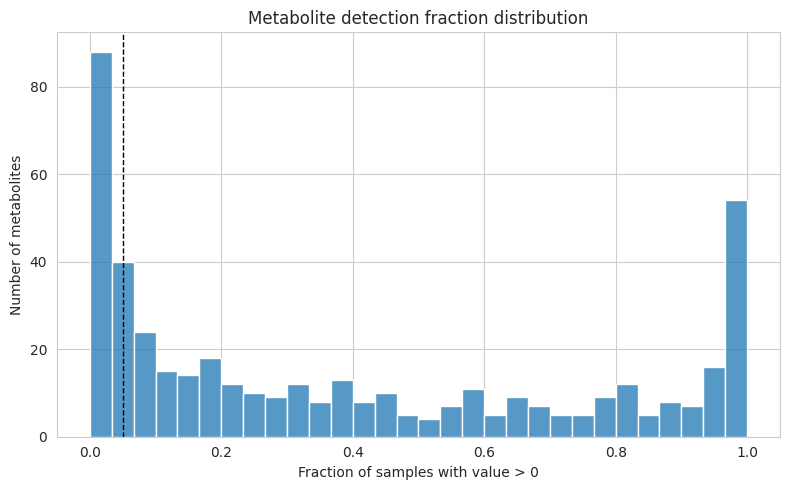

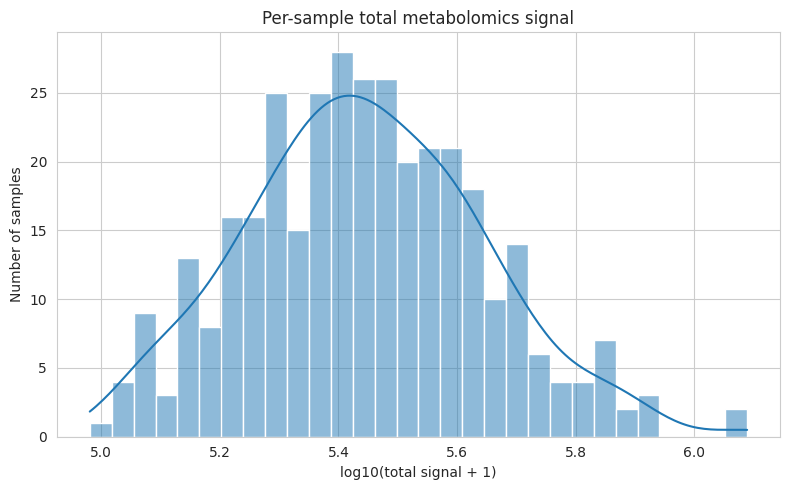

[SUCCESS] Missing-value and metabolite distribution QC outputs saved.


In [6]:

# =========================================================================
# 3A. MISSING VALUE QC AND METABOLITE DISTRIBUTION CHECKS
# =========================================================================

print("=" * 80)
print("STAGE 3A: Missing values and metabolite distributions")
print("=" * 80)

RAW_DATASETS = {
    "species_counts_raw": df_species_counts,
    "genera_counts_raw": df_genera_counts,
    "metabolomics_raw": df_mbx,
}


def summarize_missing_values(df, dataset_label):
    """Return table-level and feature-level missing value summaries."""
    total_cells = int(df.shape[0] * df.shape[1])
    missing_cells = int(df.isna().sum().sum())
    summary = {
        "Dataset": dataset_label,
        "Samples": df.shape[0],
        "Features": df.shape[1],
        "Total_Cells": total_cells,
        "Missing_Cells": missing_cells,
        "Missing_Fraction": missing_cells / total_cells if total_cells else np.nan,
        "Features_With_Any_Missing": int(df.isna().any(axis=0).sum()),
        "Samples_With_Any_Missing": int(df.isna().any(axis=1).sum()),
    }

    feature_missing = pd.DataFrame({
        "Dataset": dataset_label,
        "Feature": df.columns,
        "Missing_N": df.isna().sum(axis=0).values,
        "Missing_Fraction": df.isna().mean(axis=0).values,
    }).sort_values(["Missing_Fraction", "Feature"], ascending=[False, True])

    sample_missing = pd.DataFrame({
        "Dataset": dataset_label,
        "Sample_ID": df.index,
        "Missing_N": df.isna().sum(axis=1).values,
        "Missing_Fraction": df.isna().mean(axis=1).values,
    }).sort_values(["Missing_Fraction", "Sample_ID"], ascending=[False, True])

    return summary, feature_missing, sample_missing

missing_summaries = []
feature_missing_tables = []
sample_missing_tables = []
for label, df in RAW_DATASETS.items():
    summary, feature_missing, sample_missing = summarize_missing_values(df, label)
    missing_summaries.append(summary)
    feature_missing_tables.append(feature_missing)
    sample_missing_tables.append(sample_missing)

df_missing_summary = pd.DataFrame(missing_summaries)
df_missing_by_feature = pd.concat(feature_missing_tables, ignore_index=True)
df_missing_by_sample = pd.concat(sample_missing_tables, ignore_index=True)

df_missing_summary.to_csv(TABLE_DIR / "missing_value_summary.csv", index=False)
df_missing_by_feature.to_csv(TABLE_DIR / "missing_values_by_feature.csv", index=False)
df_missing_by_sample.to_csv(TABLE_DIR / "missing_values_by_sample.csv", index=False)

print("[QC] Missing-value summary:")
print(df_missing_summary)

# -------------------------------------------------------------------------
# Metabolite distribution checks
# -------------------------------------------------------------------------
mbx_nonnegative = df_mbx.clip(lower=0)
mbx_detection_fraction = (mbx_nonnegative > 0).mean(axis=0)
mbx_mean = mbx_nonnegative.mean(axis=0)
mbx_median = mbx_nonnegative.median(axis=0)
mbx_variance = mbx_nonnegative.var(axis=0)
mbx_missing_fraction = df_mbx.isna().mean(axis=0)

metabolite_distribution_summary = pd.DataFrame({
    "Metabolite": df_mbx.columns,
    "Mean": mbx_mean.values,
    "Median": mbx_median.values,
    "Variance": mbx_variance.values,
    "Detection_Fraction": mbx_detection_fraction.values,
    "Missing_Fraction": mbx_missing_fraction.values,
}).sort_values("Detection_Fraction")
metabolite_distribution_summary.to_csv(TABLE_DIR / "metabolite_distribution_summary.csv", index=False)

# Plot 1: overall log10(x+1) intensity distribution.
flat_log_mbx = np.log10(mbx_nonnegative.to_numpy().ravel() + METABOLITE_PSEUDOCOUNT)
flat_log_mbx = flat_log_mbx[np.isfinite(flat_log_mbx)]
plt.figure(figsize=(8, 5))
sns.histplot(flat_log_mbx, bins=60, kde=True)
plt.title("Metabolite intensity distribution after log10(x + 1)")
plt.xlabel("log10(intensity + 1)")
plt.ylabel("Number of values")
plt.tight_layout()
plt.savefig(FIG_DIR / "metabolite_log_intensity_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot 2: detection fraction across metabolites.
plt.figure(figsize=(8, 5))
sns.histplot(mbx_detection_fraction, bins=30, kde=False)
plt.axvline(PREVALENCE_THRESHOLD, linestyle="--", color="black", linewidth=1)
plt.title("Metabolite detection fraction distribution")
plt.xlabel("Fraction of samples with value > 0")
plt.ylabel("Number of metabolites")
plt.tight_layout()
plt.savefig(FIG_DIR / "metabolite_detection_fraction_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot 3: per-sample total metabolomics signal.
sample_total_signal = mbx_nonnegative.sum(axis=1)
plt.figure(figsize=(8, 5))
sns.histplot(np.log10(sample_total_signal + METABOLITE_PSEUDOCOUNT), bins=30, kde=True)
plt.title("Per-sample total metabolomics signal")
plt.xlabel("log10(total signal + 1)")
plt.ylabel("Number of samples")
plt.tight_layout()
plt.savefig(FIG_DIR / "metabolomics_total_signal_per_sample_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

print("[SUCCESS] Missing-value and metabolite distribution QC outputs saved.")



## 3B. Low-abundance filtering, log transformation, and standardization

Species and genera count tables are converted to relative abundance. Taxa must pass both prevalence and mean relative abundance thresholds. Metabolomics features are filtered by detection and zero variance, log-transformed, median-imputed if needed, and standardized.


In [7]:

# =========================================================================
# 3B. LOW-ABUNDANCE FILTERING, LOG TRANSFORMATION, AND STANDARDIZATION
# =========================================================================

print("=" * 80)
print("STAGE 3B: Filtering, log transformation, and standardization")
print("=" * 80)

n_samples = len(paired_ids)
min_prevalence_n = max(1, int(PREVALENCE_THRESHOLD * n_samples))
print(f"[QC] Minimum prevalence count: {min_prevalence_n}/{n_samples} samples ({PREVALENCE_THRESHOLD:.0%})")


def preprocess_taxonomy_counts(count_df, level_label):
    """Convert counts to relative abundances, filter low-abundance taxa, log-transform, and scale."""
    count_df = count_df.apply(pd.to_numeric, errors="coerce")
    count_df = count_df.fillna(0)
    count_df[count_df < 0] = 0

    row_sums = count_df.sum(axis=1).replace(0, np.nan)
    rel_df = count_df.div(row_sums, axis=0).fillna(0)

    prevalence = (rel_df > 0).sum(axis=0)
    mean_abundance = rel_df.mean(axis=0)
    variance = rel_df.var(axis=0)
    keep_mask = (
        (prevalence >= min_prevalence_n) &
        (mean_abundance >= MIN_MEAN_REL_ABUNDANCE) &
        (variance > 0)
    )

    filtered_rel = rel_df.loc[:, keep_mask].copy()
    log_df = np.log10(filtered_rel + TAXA_PSEUDOCOUNT)

    scaler = StandardScaler()
    scaled_array = scaler.fit_transform(log_df)
    scaled_df = pd.DataFrame(scaled_array, index=log_df.index, columns=log_df.columns)

    filter_summary = pd.DataFrame({
        "Taxonomic_Level": level_label,
        "Feature": rel_df.columns,
        "Prevalence_N": prevalence.values,
        "Prevalence_Fraction": prevalence.values / rel_df.shape[0],
        "Mean_Relative_Abundance": mean_abundance.values,
        "Variance": variance.values,
        "Kept": keep_mask.values,
    })

    rel_df.to_csv(TABLE_DIR / f"{level_label}_relative_abundance_all.csv")
    filtered_rel.to_csv(TABLE_DIR / f"{level_label}_relative_abundance_filtered.csv")
    log_df.to_csv(TABLE_DIR / f"{level_label}_log10_relative_abundance.csv")
    scaled_df.to_csv(TABLE_DIR / f"{level_label}_preprocessed_scaled.csv")
    filter_summary.to_csv(TABLE_DIR / f"{level_label}_feature_filtering_summary.csv", index=False)

    return {
        "counts": count_df,
        "relative_abundance": rel_df,
        "filtered_rel": filtered_rel,
        "log": log_df,
        "scaled": scaled_df,
        "scaler": scaler,
        "filter_summary": filter_summary,
    }


def preprocess_metabolomics(mbx_df):
    """Filter, log-transform, impute, and standardize metabolomics data."""
    mbx_numeric = mbx_df.apply(pd.to_numeric, errors="coerce")
    negative_values = int((mbx_numeric < 0).sum().sum())
    if negative_values > 0:
        print(f"[WARNING] Found {negative_values} negative metabolomics values. Clipping negatives to 0 before log transform.")
    mbx_nonnegative = mbx_numeric.clip(lower=0)

    prevalence = (mbx_nonnegative > 0).sum(axis=0)
    variance = mbx_nonnegative.var(axis=0, skipna=True)
    keep_mask = (prevalence >= min_prevalence_n) & (variance > 0)

    filtered = mbx_nonnegative.loc[:, keep_mask].copy()
    log_df = np.log10(filtered + METABOLITE_PSEUDOCOUNT)

    imputer = SimpleImputer(strategy="median")
    imputed_array = imputer.fit_transform(log_df)
    imputed_df = pd.DataFrame(imputed_array, index=log_df.index, columns=log_df.columns)

    scaler = StandardScaler()
    scaled_array = scaler.fit_transform(imputed_df)
    scaled_df = pd.DataFrame(scaled_array, index=log_df.index, columns=log_df.columns)

    filter_summary = pd.DataFrame({
        "Feature": mbx_numeric.columns,
        "Prevalence_N": prevalence.values,
        "Prevalence_Fraction": prevalence.values / mbx_numeric.shape[0],
        "Variance": variance.values,
        "Missing_Fraction": mbx_numeric.isna().mean(axis=0).values,
        "Kept": keep_mask.values,
    })

    filtered.to_csv(TABLE_DIR / "metabolomics_filtered.csv")
    log_df.to_csv(TABLE_DIR / "metabolomics_log10.csv")
    imputed_df.to_csv(TABLE_DIR / "metabolomics_log10_imputed.csv")
    scaled_df.to_csv(TABLE_DIR / "metabolomics_preprocessed_scaled.csv")
    filter_summary.to_csv(TABLE_DIR / "metabolomics_feature_filtering_summary.csv", index=False)

    return {
        "filtered": filtered,
        "log": log_df,
        "imputed": imputed_df,
        "scaled": scaled_df,
        "imputer": imputer,
        "scaler": scaler,
        "filter_summary": filter_summary,
    }

# Preprocess both taxonomic levels.
taxa_preprocessed = {
    "species": preprocess_taxonomy_counts(df_species_counts, "species"),
    "genera": preprocess_taxonomy_counts(df_genera_counts, "genera"),
}
mbx_preprocessed = preprocess_metabolomics(df_mbx)

# Compatibility variables for downstream readability.
df_species_filtered = taxa_preprocessed["species"]["filtered_rel"]
df_genera_filtered = taxa_preprocessed["genera"]["filtered_rel"]
df_species_scaled = taxa_preprocessed["species"]["scaled"]
df_genera_scaled = taxa_preprocessed["genera"]["scaled"]
df_mbx_filtered = mbx_preprocessed["filtered"]
df_mbx_scaled = mbx_preprocessed["scaled"]

# Data blocks used by downstream PCA/UMAP/ML.
preprocessed_blocks = {
    "species": df_species_scaled,
    "genera": df_genera_scaled,
    "metabolomics": df_mbx_scaled,
}

differential_input_blocks = {
    "species": df_species_filtered,
    "genera": df_genera_filtered,
    "metabolomics": df_mbx_filtered,
}

preprocessing_summary = []
for level in ["species", "genera"]:
    preprocessing_summary.append({
        "Dataset": level,
        "Raw_Features": taxa_preprocessed[level]["counts"].shape[1],
        "Kept_Features": taxa_preprocessed[level]["filtered_rel"].shape[1],
        "Filtered_Out_Features": taxa_preprocessed[level]["counts"].shape[1] - taxa_preprocessed[level]["filtered_rel"].shape[1],
        "Log_Transformation": f"log10(relative_abundance + {TAXA_PSEUDOCOUNT})",
        "Standardized": True,
    })
preprocessing_summary.append({
    "Dataset": "metabolomics",
    "Raw_Features": df_mbx.shape[1],
    "Kept_Features": df_mbx_filtered.shape[1],
    "Filtered_Out_Features": df_mbx.shape[1] - df_mbx_filtered.shape[1],
    "Log_Transformation": "log10(value + 1)",
    "Standardized": True,
})

df_preprocessing_summary = pd.DataFrame(preprocessing_summary)
df_preprocessing_summary.to_csv(TABLE_DIR / "final_preprocessing_summary.csv", index=False)

print("[SUMMARY] Final preprocessing summary:")
print(df_preprocessing_summary)
print("[SUCCESS] Species, genera, and metabolomics preprocessing completed.")


STAGE 3B: Filtering, log transformation, and standardization
[QC] Minimum prevalence count: 17/347 samples (5%)
[SUMMARY] Final preprocessing summary:
        Dataset  Raw_Features  Kept_Features  Filtered_Out_Features                 Log_Transformation  Standardized
0       species         57702           6943                  50759  log10(relative_abundance + 1e-06)          True
1        genera         11942           1871                  10071  log10(relative_abundance + 1e-06)          True
2  metabolomics           450            345                    105                   log10(value + 1)          True
[SUCCESS] Species, genera, and metabolomics preprocessing completed.



## 4. Disease-stage distribution plots, PCA, and UMAP

This stage generates disease-stage distribution plots and runs PCA/UMAP for species, genera, and metabolomics data blocks.


STAGE 4: Disease-stage distributions, PCA, and UMAP


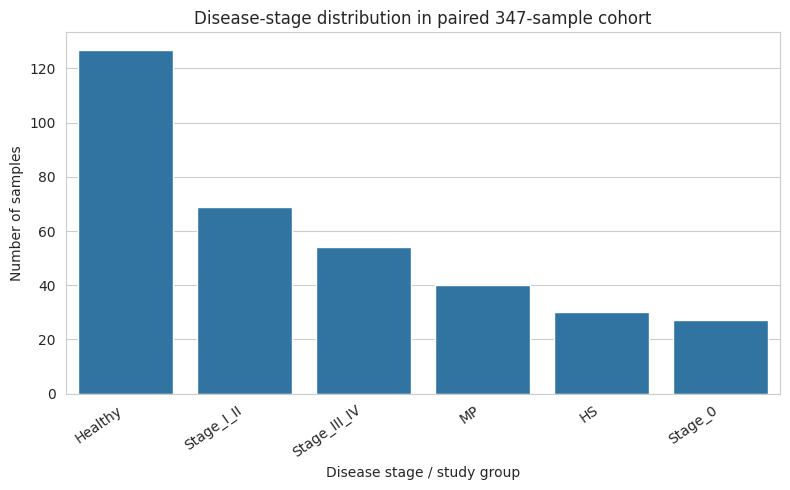

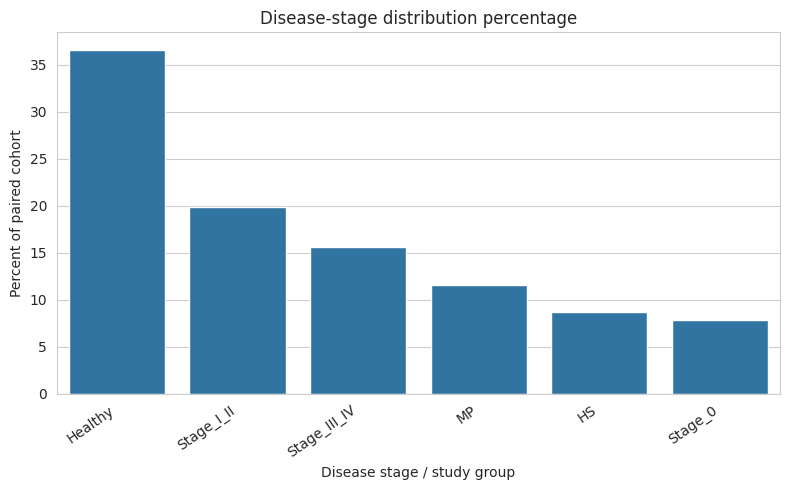

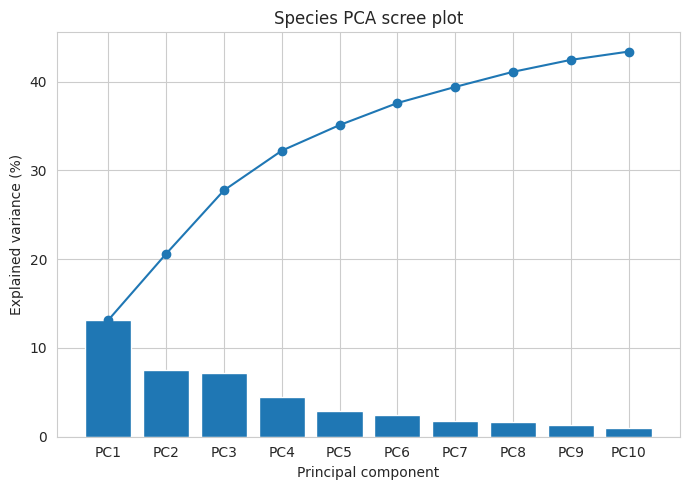

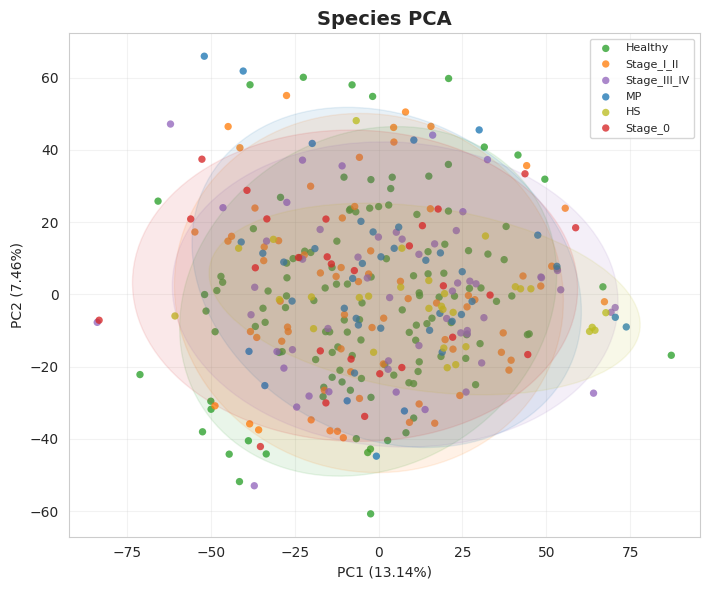

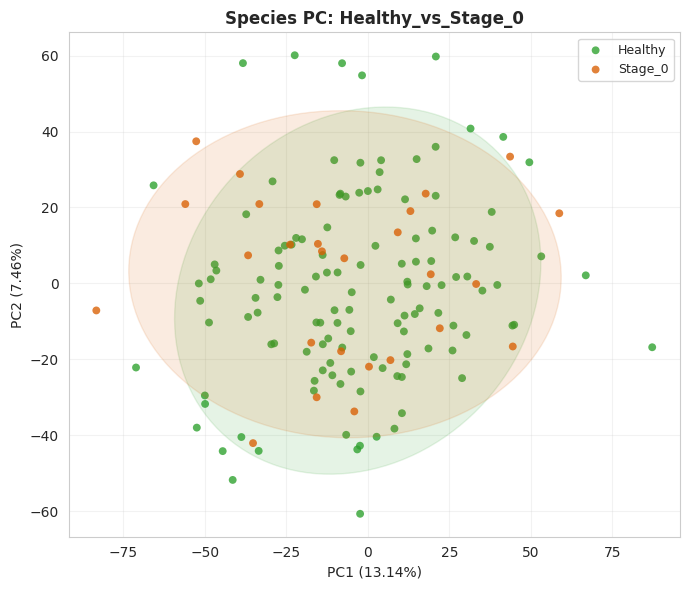

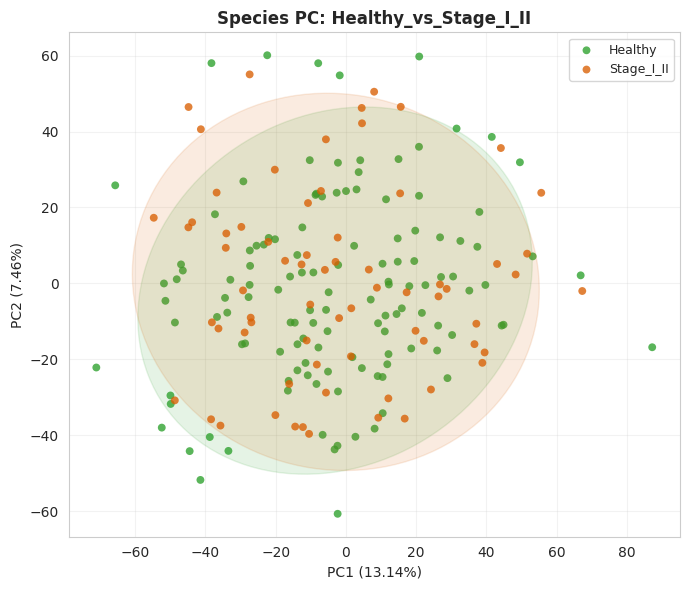

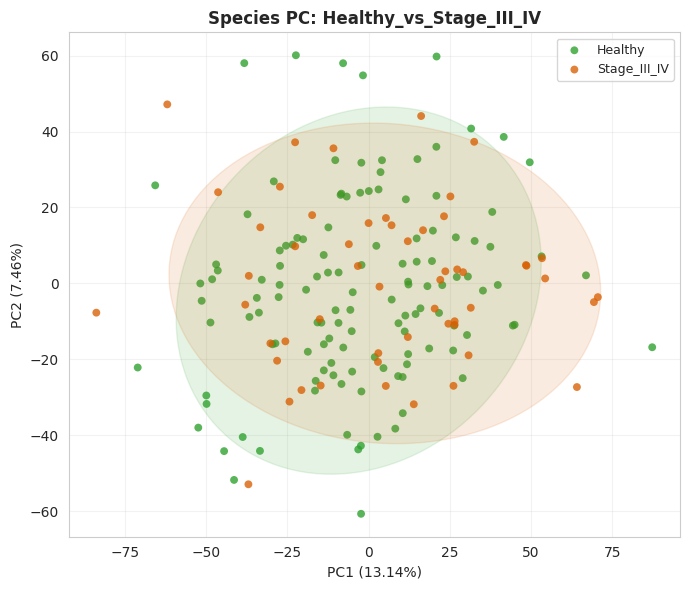

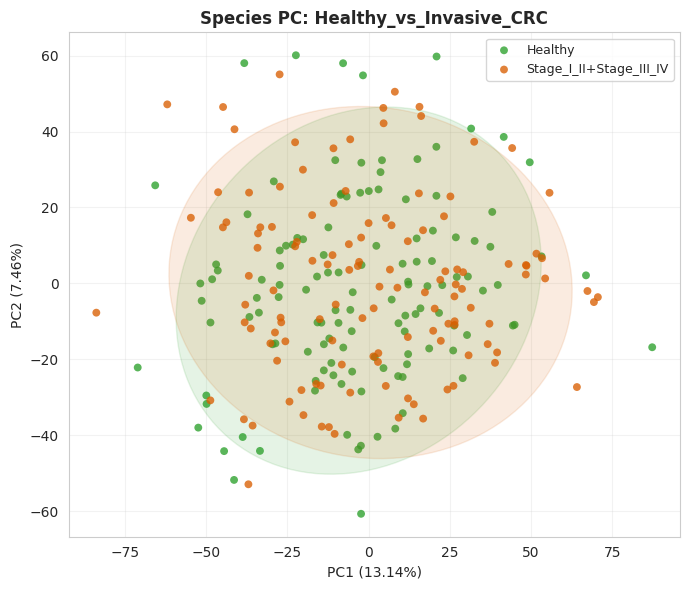

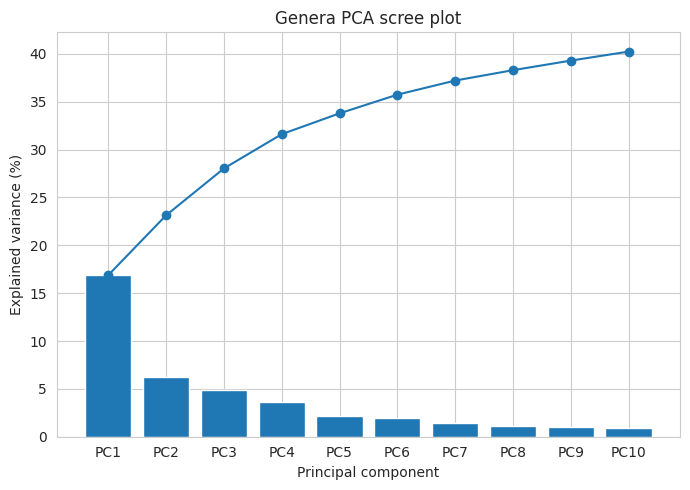

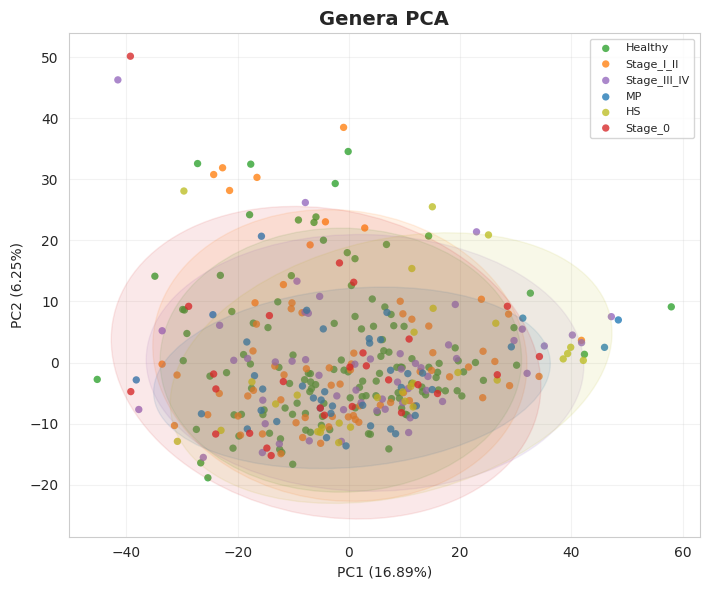

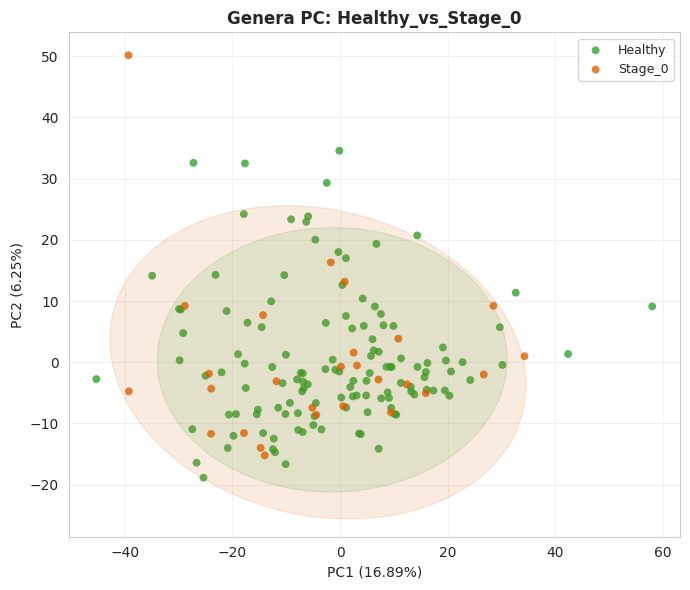

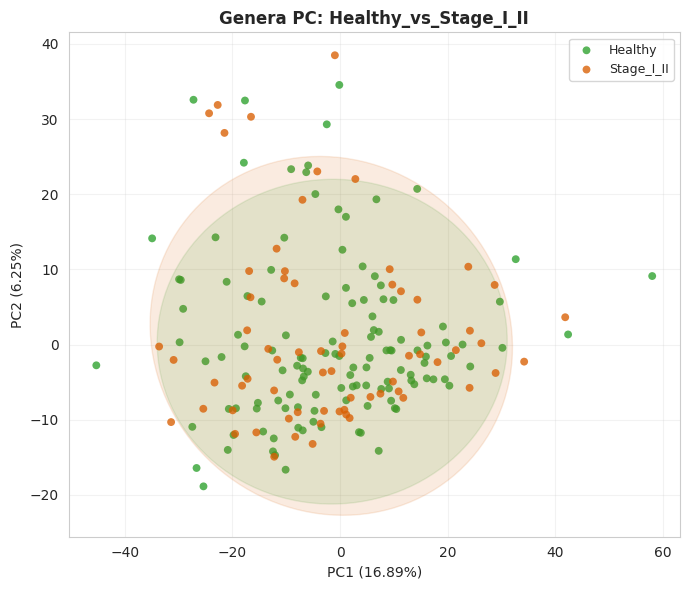

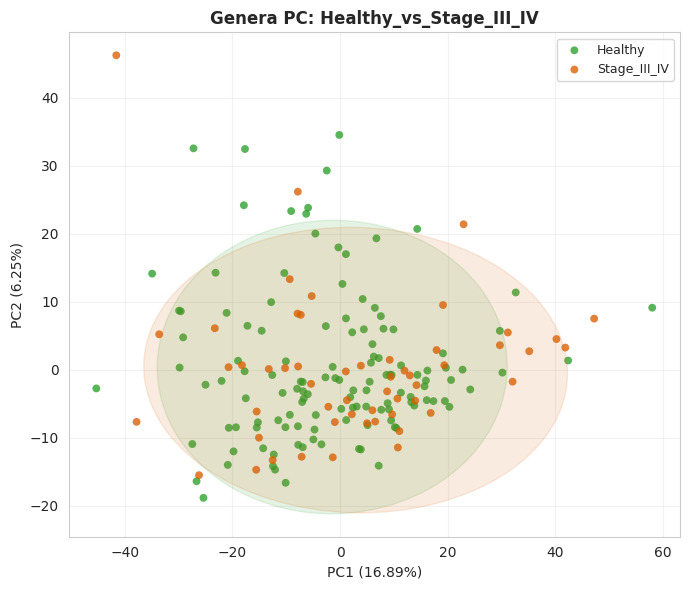

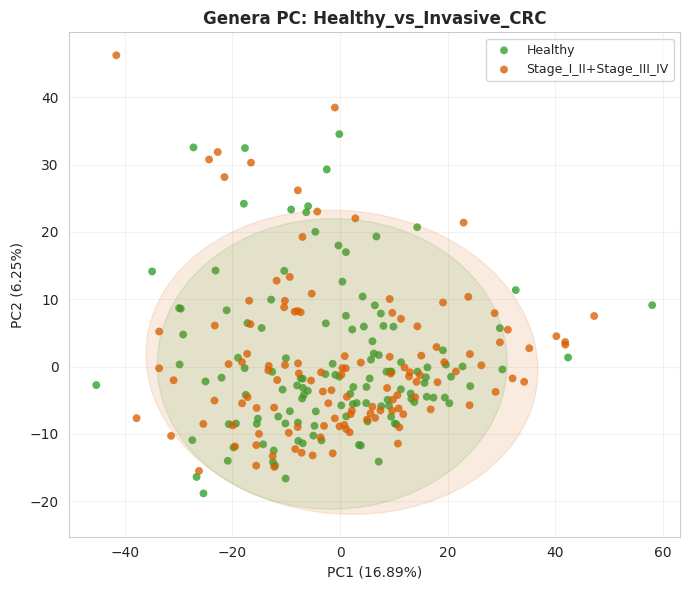

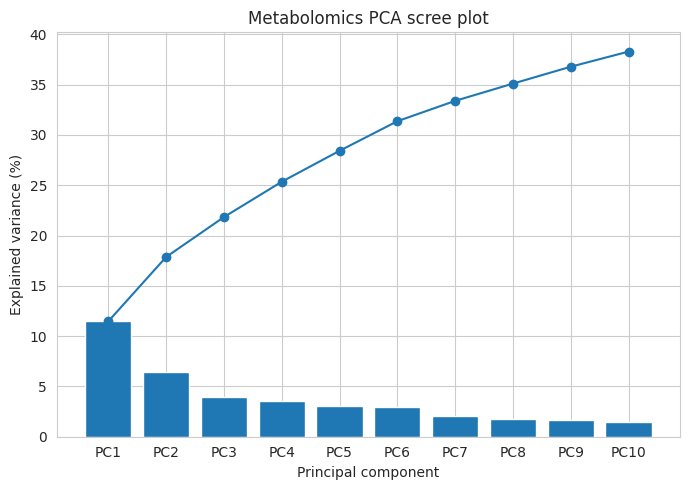

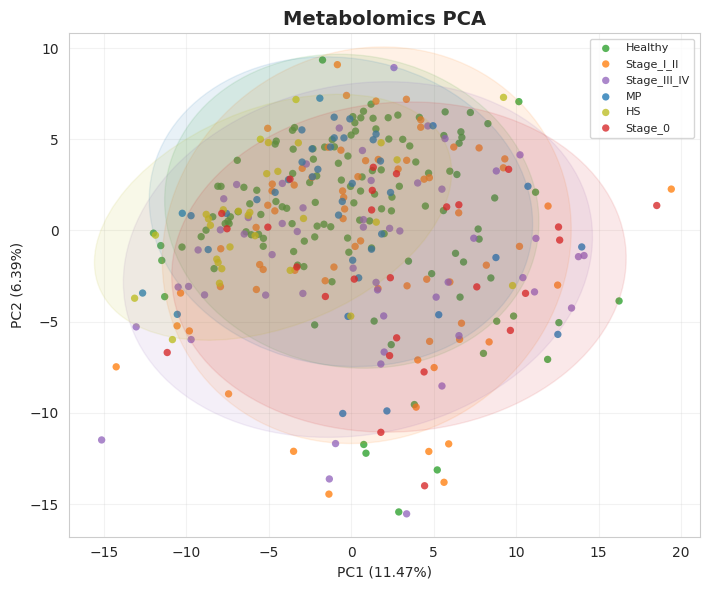

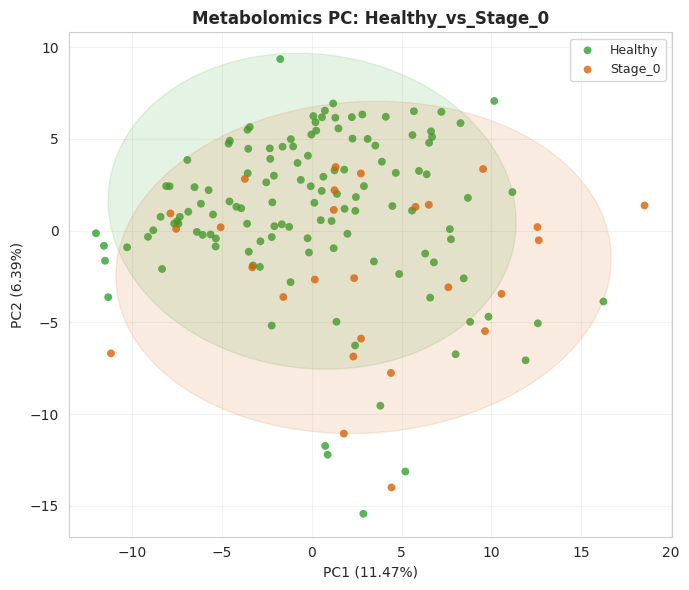

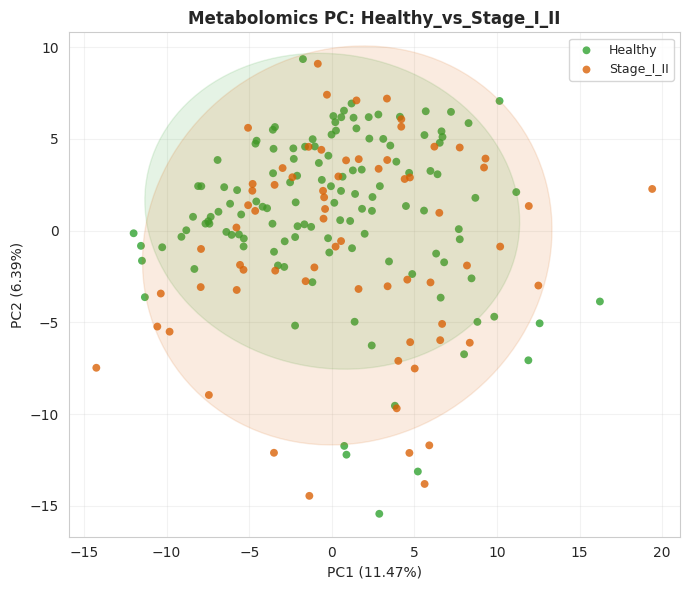

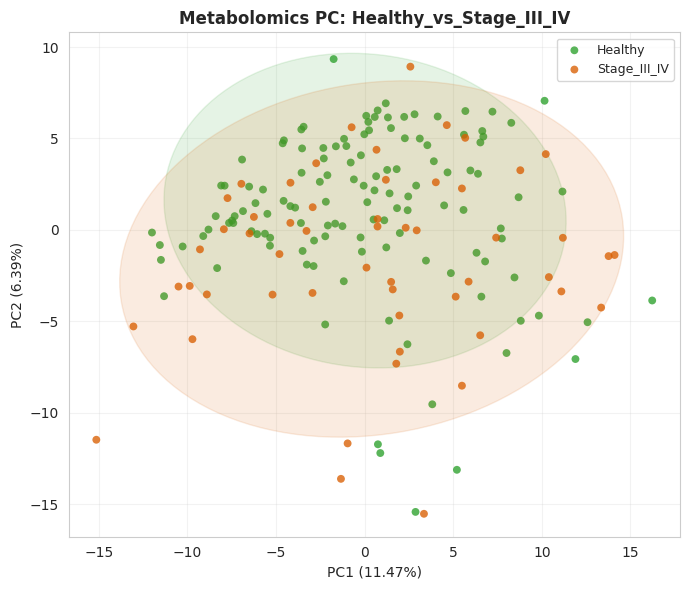

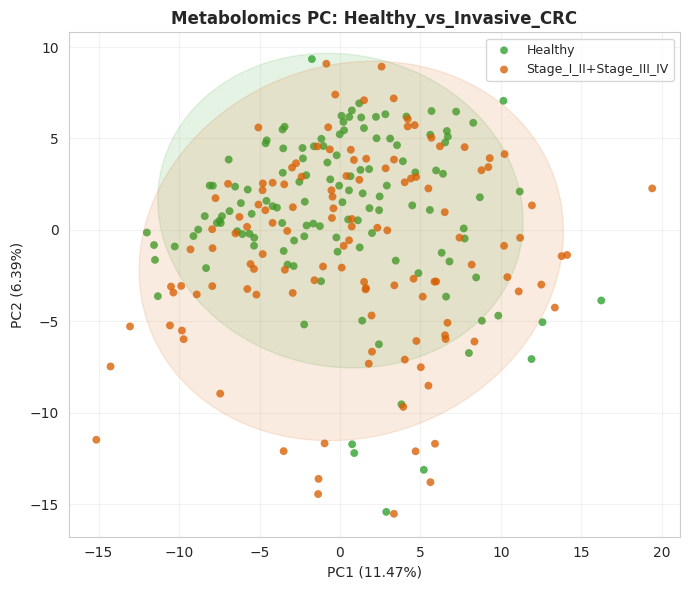

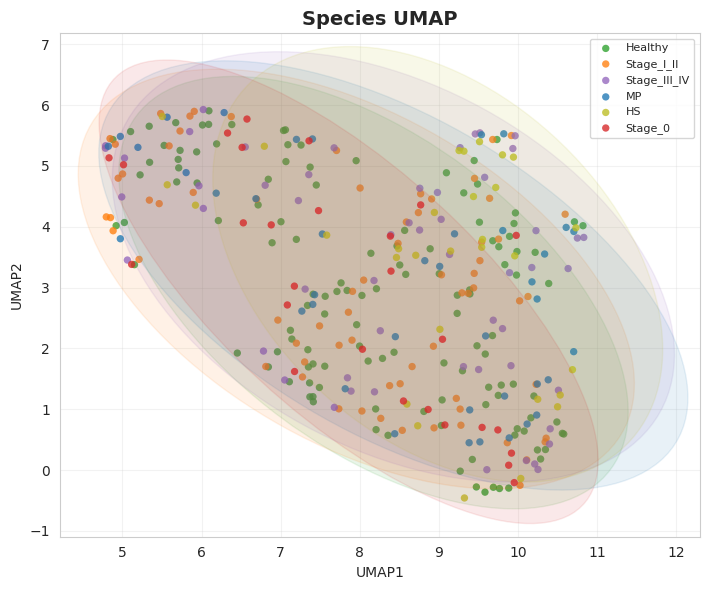

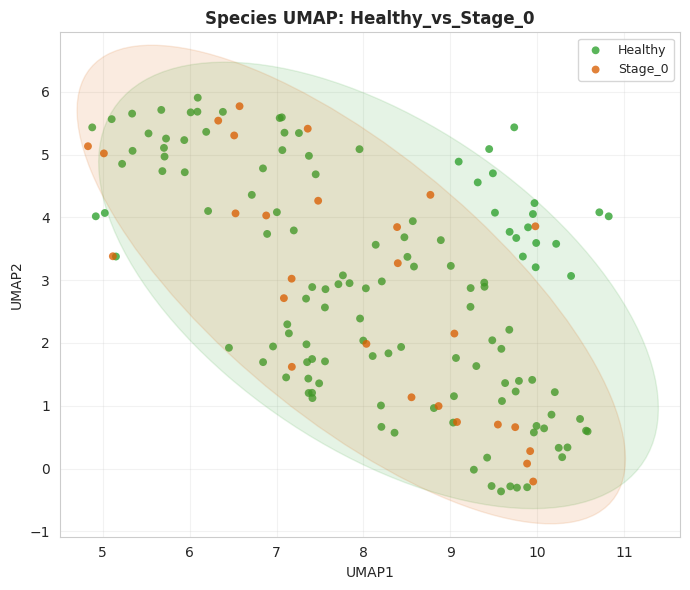

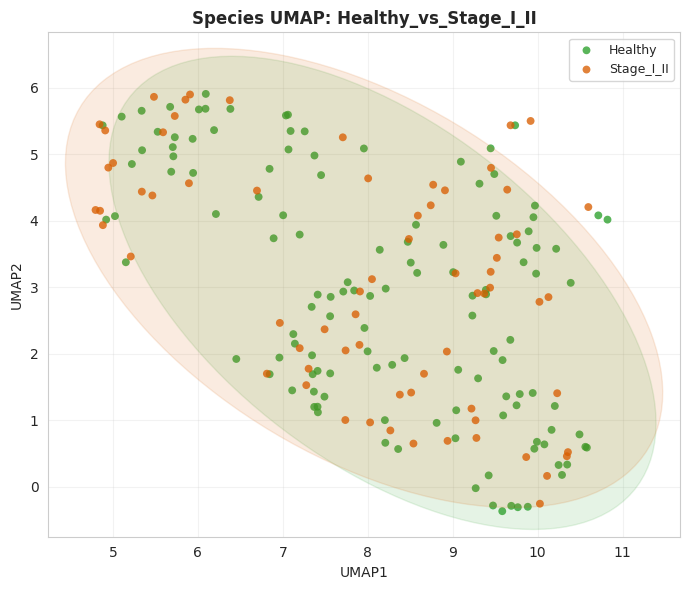

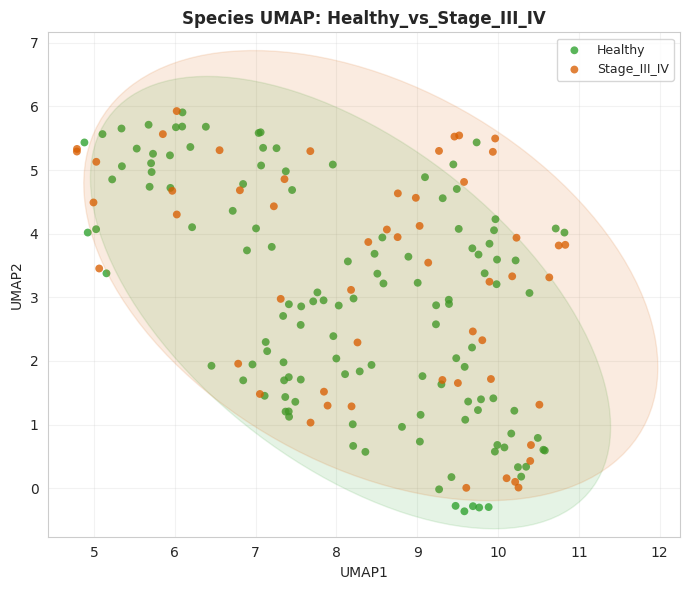

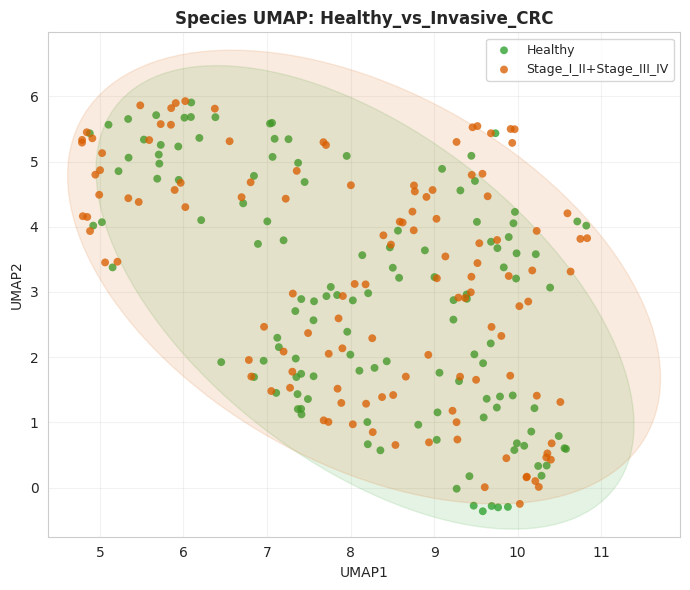

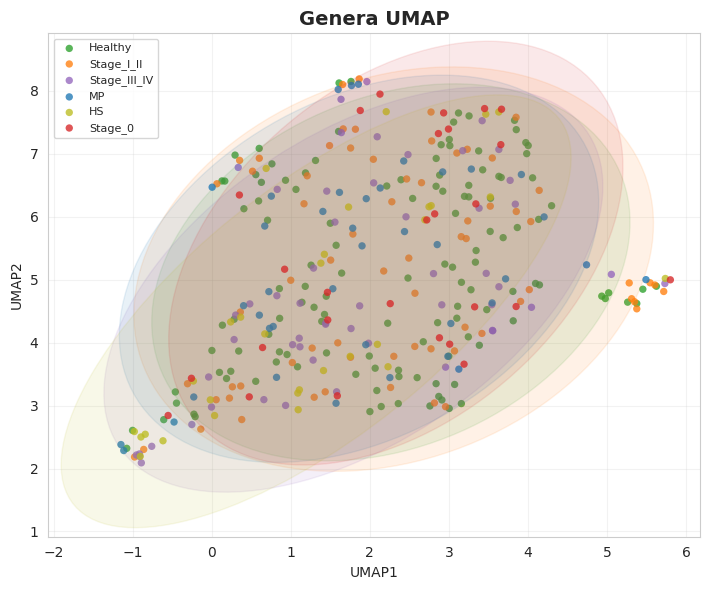

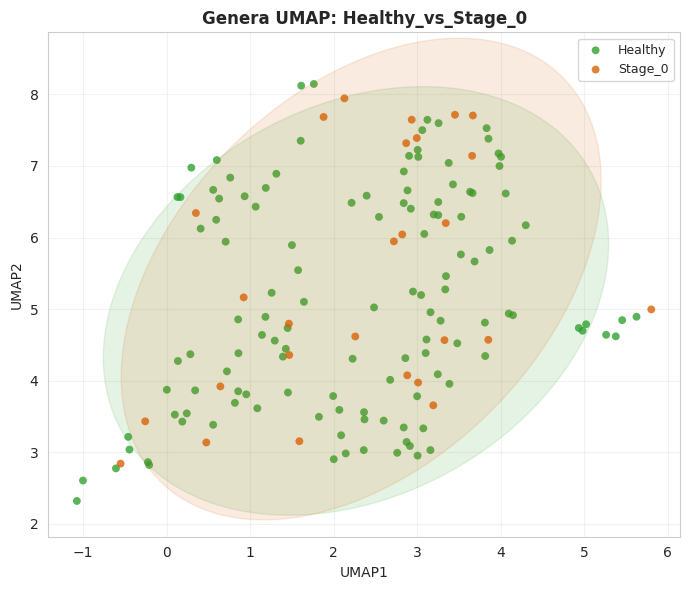

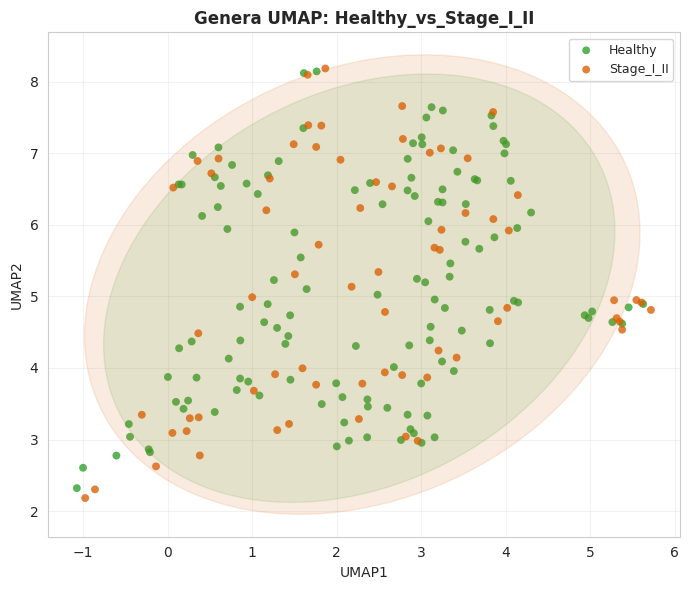

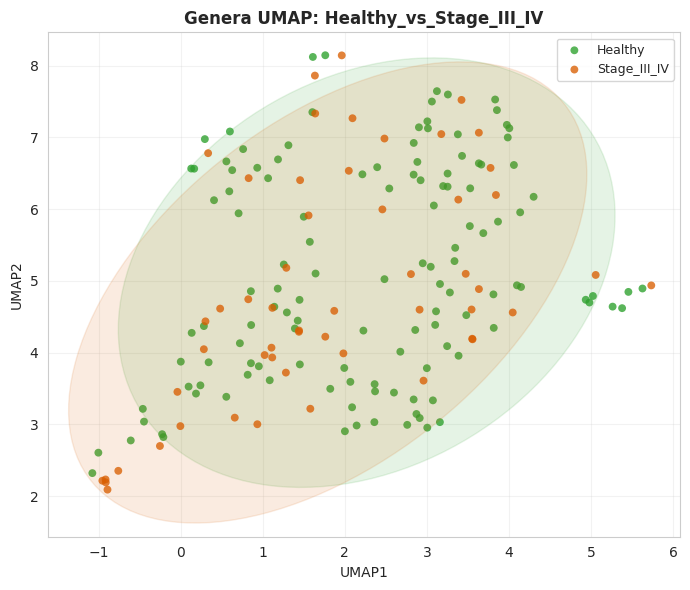

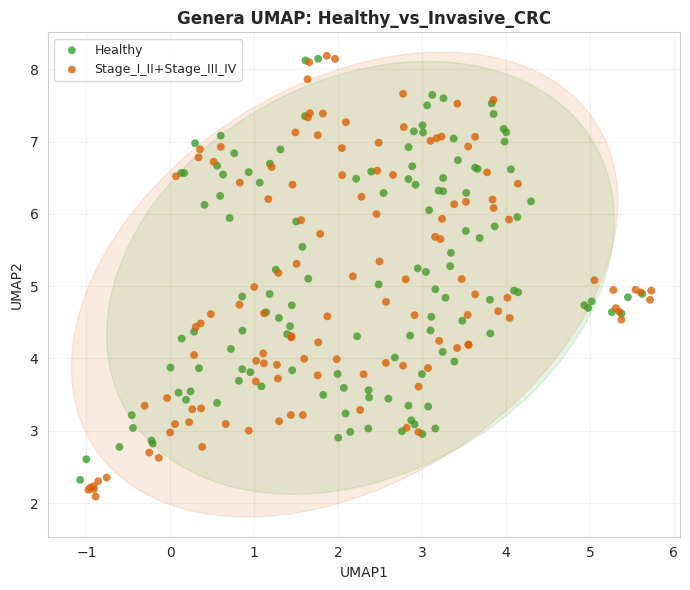

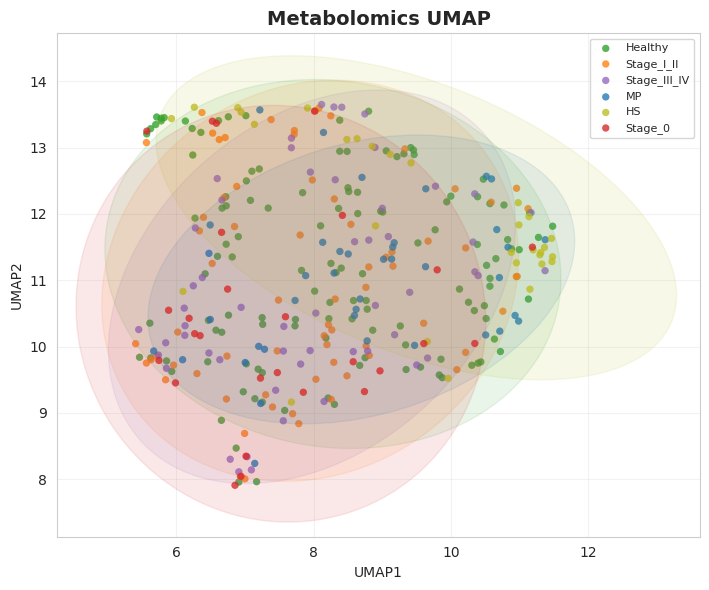

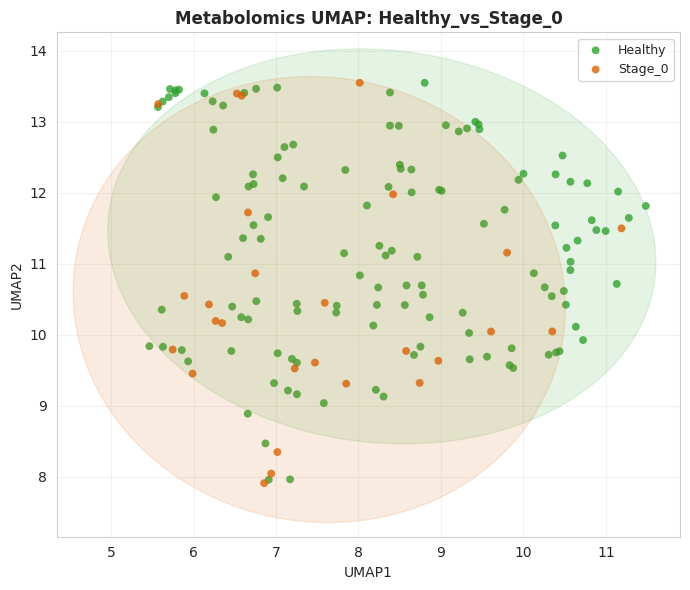

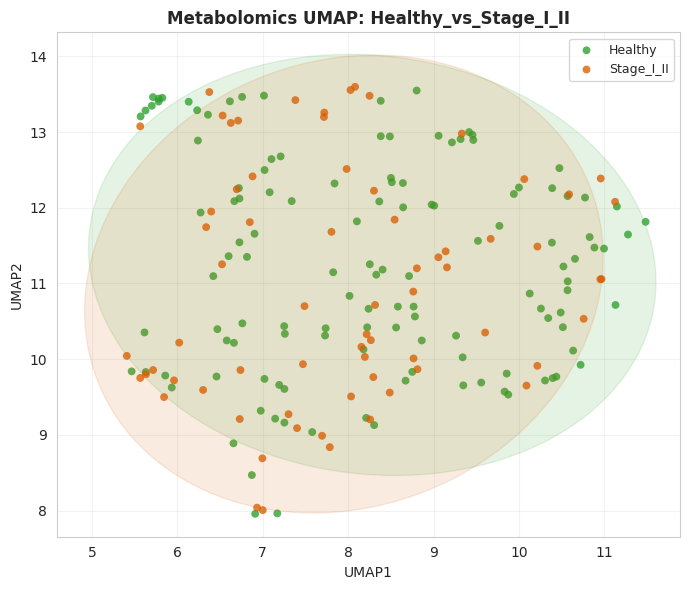

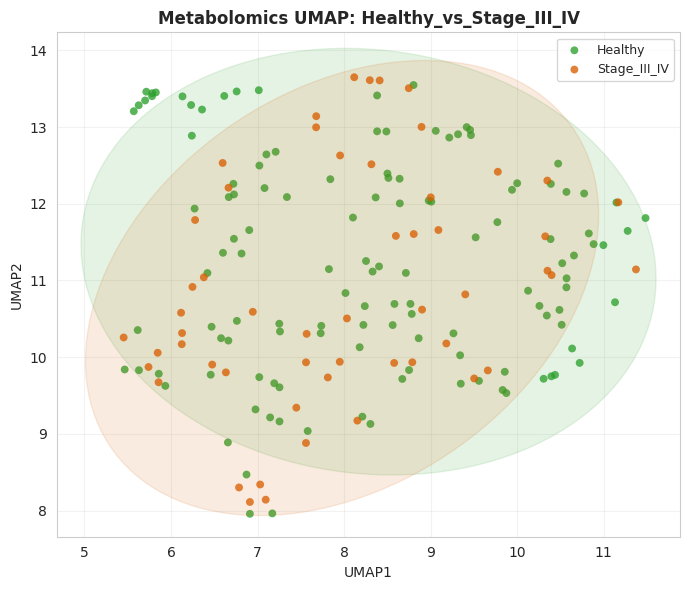

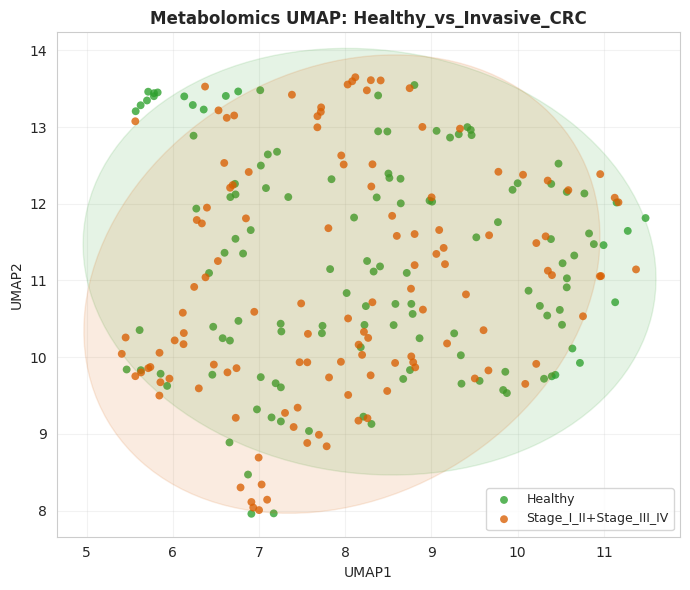

[SUCCESS] Disease-stage distribution plots, PCA, and UMAP outputs saved.


In [8]:

# =========================================================================
# 4. DISEASE-STAGE DISTRIBUTION, PCA, AND UMAP
# =========================================================================

print("=" * 80)
print("STAGE 4: Disease-stage distributions, PCA, and UMAP")
print("=" * 80)

# -------------------------------------------------------------------------
# Disease-stage distribution plots
# -------------------------------------------------------------------------
stage_counts = df_meta[GROUP_COL].astype(str).value_counts().rename_axis("Study_Group").reset_index(name="N")
stage_counts["Percent"] = 100 * stage_counts["N"] / stage_counts["N"].sum()
stage_counts.to_csv(TABLE_DIR / "disease_stage_distribution_counts.csv", index=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=stage_counts, x="Study_Group", y="N")
plt.title("Disease-stage distribution in paired 347-sample cohort")
plt.xlabel("Disease stage / study group")
plt.ylabel("Number of samples")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(FIG_DIR / "disease_stage_distribution_counts.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 5))
sns.barplot(data=stage_counts, x="Study_Group", y="Percent")
plt.title("Disease-stage distribution percentage")
plt.xlabel("Disease stage / study group")
plt.ylabel("Percent of paired cohort")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(FIG_DIR / "disease_stage_distribution_percent.png", dpi=300, bbox_inches="tight")
plt.show()

# -------------------------------------------------------------------------
# General plotting helpers
# -------------------------------------------------------------------------
palette = {
    "Healthy": "#2ca02c",
    "Stage_0": "#d62728",
    "Stage_I_II": "#ff7f0e",
    "Stage_III_IV": "#9467bd",
    "MP": "#1f77b4",
    "HS": "#bcbd22",
}


def add_covariance_ellipse(ax, x, y, color, alpha=0.10):
    """Add a translucent covariance ellipse to a 2D embedding plot."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    if len(x) < 3:
        return
    cov = np.cov(x, y)
    if not np.all(np.isfinite(cov)):
        return
    eigenvalues, eigenvectors = np.linalg.eigh(cov)
    if np.any(eigenvalues <= 0):
        return
    order = eigenvalues.argsort()[::-1]
    eigenvalues = eigenvalues[order]
    eigenvectors = eigenvectors[:, order]
    angle = np.degrees(np.arctan2(*eigenvectors[:, 0][::-1]))
    width, height = 2 * 2.0 * np.sqrt(eigenvalues)
    ellipse = Ellipse(
        xy=(np.mean(x), np.mean(y)),
        width=width,
        height=height,
        angle=angle,
        facecolor=color,
        edgecolor=color,
        alpha=alpha,
        linewidth=1.0,
    )
    ax.add_patch(ellipse)


def plot_embedding(coordinates_df, dataset_label, method_label, output_prefix, variance_df=None):
    """Plot PC/UMAP 1 vs 2 colored by study group."""
    x_col = f"{method_label}1"
    y_col = f"{method_label}2"

    fig, ax = plt.subplots(figsize=(7.2, 6.0))
    present_groups = [g for g in stage_counts["Study_Group"].tolist() if g in coordinates_df["Study_Group"].unique()]

    for group in present_groups:
        sub = coordinates_df[coordinates_df["Study_Group"] == group]
        color = palette.get(group, "#777777")
        add_covariance_ellipse(ax, sub[x_col], sub[y_col], color=color, alpha=0.10)
        ax.scatter(
            sub[x_col], sub[y_col],
            s=28,
            alpha=0.78,
            color=color,
            label=group,
            edgecolors="none",
        )

    if variance_df is not None and method_label == "PC":
        x_lab = f"PC1 ({variance_df.loc[0, 'Explained_Variance_Percent']:.2f}%)"
        y_lab = f"PC2 ({variance_df.loc[1, 'Explained_Variance_Percent']:.2f}%)"
        title = f"{dataset_label.title()} PCA"
    else:
        x_lab = f"{method_label}1"
        y_lab = f"{method_label}2"
        title = f"{dataset_label.title()} {method_label}"

    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xlabel(x_lab)
    ax.set_ylabel(y_lab)
    ax.legend(fontsize=8, loc="best", frameon=True)
    ax.grid(True, alpha=0.25)
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{output_prefix}_{method_label.lower()}_all_groups.png", dpi=300, bbox_inches="tight")
    plt.show()


def plot_contrast_embedding(coordinates_df, contrast_name, spec, dataset_label, method_label, output_prefix, variance_df=None):
    """Plot contrast-specific PCA/UMAP embedding."""
    group_a_labels = spec["Group_A_Labels"]
    group_b_labels = spec["Group_B_Labels"]
    group_b_name = "+".join(group_b_labels)
    sub = coordinates_df[coordinates_df["Study_Group"].isin(group_a_labels + group_b_labels)].copy()
    if sub.empty:
        return
    sub["Contrast_Group"] = np.where(sub["Study_Group"].isin(group_a_labels), "Healthy", group_b_name)

    x_col = f"{method_label}1"
    y_col = f"{method_label}2"
    fig, ax = plt.subplots(figsize=(7.0, 6.0))
    contrast_palette = {"Healthy": palette.get("Healthy", "#2ca02c"), group_b_name: "#d95f02"}
    for group_name in ["Healthy", group_b_name]:
        group_df = sub[sub["Contrast_Group"] == group_name]
        color = contrast_palette[group_name]
        add_covariance_ellipse(ax, group_df[x_col], group_df[y_col], color=color, alpha=0.12)
        ax.scatter(group_df[x_col], group_df[y_col], s=32, alpha=0.78, color=color, label=group_name, edgecolors="none")

    if variance_df is not None and method_label == "PC":
        x_lab = f"PC1 ({variance_df.loc[0, 'Explained_Variance_Percent']:.2f}%)"
        y_lab = f"PC2 ({variance_df.loc[1, 'Explained_Variance_Percent']:.2f}%)"
    else:
        x_lab = f"{method_label}1"
        y_lab = f"{method_label}2"

    ax.set_title(f"{dataset_label.title()} {method_label}: {contrast_name}", fontsize=12, fontweight="bold")
    ax.set_xlabel(x_lab)
    ax.set_ylabel(y_lab)
    ax.legend(fontsize=9, loc="best", frameon=True)
    ax.grid(True, alpha=0.25)
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{output_prefix}_{method_label.lower()}_{contrast_name}.png", dpi=300, bbox_inches="tight")
    plt.show()

# -------------------------------------------------------------------------
# PCA
# -------------------------------------------------------------------------
pca_results = {}
for dataset_label, X in preprocessed_blocks.items():
    n_pcs = min(N_PCS, X.shape[0], X.shape[1])
    pca = PCA(n_components=n_pcs, random_state=RANDOM_STATE)
    pcs = pca.fit_transform(X)
    pc_names = [f"PC{i+1}" for i in range(n_pcs)]

    variance_df = pd.DataFrame({
        "Component": pc_names,
        "Eigenvalue": pca.explained_variance_,
        "Explained_Variance_Ratio": pca.explained_variance_ratio_,
        "Explained_Variance_Percent": pca.explained_variance_ratio_ * 100,
        "Cumulative_Variance_Ratio": np.cumsum(pca.explained_variance_ratio_),
        "Cumulative_Variance_Percent": np.cumsum(pca.explained_variance_ratio_) * 100,
    })

    coordinates_df = pd.DataFrame(pcs, index=X.index, columns=pc_names)
    coordinates_df.insert(0, "Study_Group", df_meta.loc[X.index, GROUP_COL].astype(str).values)

    loadings_df = pd.DataFrame(pca.components_.T, index=X.columns, columns=pc_names)
    loadings_df.index.name = "Feature"

    variance_df.to_csv(TABLE_DIR / f"{dataset_label}_pca_variance_table.csv", index=False)
    coordinates_df.to_csv(TABLE_DIR / f"{dataset_label}_pca_coordinates.csv", index_label="Sample_ID")
    loadings_df.to_csv(TABLE_DIR / f"{dataset_label}_pca_loadings.csv")

    pca_results[dataset_label] = {
        "model": pca,
        "variance": variance_df,
        "coordinates": coordinates_df,
        "loadings": loadings_df,
    }

    # Scree plot.
    plt.figure(figsize=(7, 5))
    plt.bar(variance_df["Component"], variance_df["Explained_Variance_Percent"])
    plt.plot(variance_df["Component"], variance_df["Cumulative_Variance_Percent"], marker="o")
    plt.title(f"{dataset_label.title()} PCA scree plot")
    plt.xlabel("Principal component")
    plt.ylabel("Explained variance (%)")
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{dataset_label}_pca_scree_plot.png", dpi=300, bbox_inches="tight")
    plt.show()

    plot_embedding(coordinates_df.rename(columns={"PC1": "PC1", "PC2": "PC2"}), dataset_label, "PC", dataset_label, variance_df=variance_df)
    for contrast_name, spec in ACTIVE_CONTRASTS.items():
        plot_contrast_embedding(coordinates_df, contrast_name, spec, dataset_label, "PC", dataset_label, variance_df=variance_df)

# -------------------------------------------------------------------------
# UMAP
# -------------------------------------------------------------------------
try:
    import umap.umap_ as umap
except ImportError:
    print("[INFO] umap-learn is not installed. Installing umap-learn now...")
    subprocess.run([sys.executable, "-m", "pip", "install", "umap-learn"], check=True)
    import umap.umap_ as umap

umap_results = {}
for dataset_label, X in preprocessed_blocks.items():
    reducer = umap.UMAP(
        n_components=2,
        n_neighbors=15,
        min_dist=0.1,
        metric="euclidean",
        random_state=RANDOM_STATE,
    )
    embedding = reducer.fit_transform(X)
    coordinates_df = pd.DataFrame(embedding, index=X.index, columns=["UMAP1", "UMAP2"])
    coordinates_df.insert(0, "Study_Group", df_meta.loc[X.index, GROUP_COL].astype(str).values)
    coordinates_df.to_csv(TABLE_DIR / f"{dataset_label}_umap_coordinates.csv", index_label="Sample_ID")
    umap_results[dataset_label] = {"model": reducer, "coordinates": coordinates_df}

    plot_embedding(coordinates_df, dataset_label, "UMAP", dataset_label)
    for contrast_name, spec in ACTIVE_CONTRASTS.items():
        plot_contrast_embedding(coordinates_df, contrast_name, spec, dataset_label, "UMAP", dataset_label)

print("[SUCCESS] Disease-stage distribution plots, PCA, and UMAP outputs saved.")



## 5. Differential abundance testing and significant feature tables

This stage performs Mann-Whitney U differential testing for species, genera, and metabolomics for every active Healthy-vs-disease contrast. Significant taxa tables are produced separately for species and genera.


In [9]:

# =========================================================================
# 5. DIFFERENTIAL ABUNDANCE TESTING AND SIGNIFICANT FEATURE TABLES
# =========================================================================

print("=" * 80)
print("STAGE 5: Differential abundance testing for species, genera, and metabolomics")
print("=" * 80)


def run_differential_testing(df_data, group_a_ids, group_b_ids, group_a_name, group_b_name, is_microbiome=True):
    """Run Mann-Whitney U feature-wise differential testing."""
    records = []
    pseudo = TAXA_PSEUDOCOUNT if is_microbiome else METABOLITE_PSEUDOCOUNT

    for feature in df_data.columns:
        a = df_data.loc[group_a_ids, feature].astype(float)
        b = df_data.loc[group_b_ids, feature].astype(float)

        mean_a = a.mean()
        mean_b = b.mean()
        median_a = a.median()
        median_b = b.median()
        prevalence_a = (a > 0).mean()
        prevalence_b = (b > 0).mean()
        log2fc = np.log2((mean_b + pseudo) / (mean_a + pseudo))

        try:
            stat, p_value = mannwhitneyu(a, b, alternative="two-sided")
        except ValueError:
            stat, p_value = np.nan, 1.0

        records.append({
            "Feature": feature,
            "Group_A": group_a_name,
            "Group_B": group_b_name,
            "N_Group_A": len(a),
            "N_Group_B": len(b),
            "Mean_Group_A": mean_a,
            "Mean_Group_B": mean_b,
            "Median_Group_A": median_a,
            "Median_Group_B": median_b,
            "Prevalence_Group_A": prevalence_a,
            "Prevalence_Group_B": prevalence_b,
            "Log2FC_GroupB_vs_GroupA": log2fc,
            "MannWhitneyU": stat,
            "P_Value": p_value,
        })

    result = pd.DataFrame(records)
    result["FDR_BH"] = multipletests(result["P_Value"].fillna(1.0), method="fdr_bh")[1]
    result["Significant_FDR"] = (
        (result["FDR_BH"] < FDR_THRESHOLD) &
        (result["Log2FC_GroupB_vs_GroupA"].abs() >= LOG2FC_THRESHOLD)
    )
    return result.sort_values(["FDR_BH", "P_Value", "Feature"]).reset_index(drop=True)


diff_results = {}
summary_records = []
all_significant_taxa_tables = []
all_significant_metabolite_tables = []

for contrast_name, spec in ACTIVE_CONTRASTS.items():
    group_a_labels = spec["Group_A_Labels"]
    group_b_labels = spec["Group_B_Labels"]
    group_a_ids = df_meta.index[df_meta[GROUP_COL].isin(group_a_labels)].tolist()
    group_b_ids = df_meta.index[df_meta[GROUP_COL].isin(group_b_labels)].tolist()
    group_a_name = "+".join(group_a_labels)
    group_b_name = "+".join(group_b_labels)

    if len(group_a_ids) == 0 or len(group_b_ids) == 0:
        print(f"[WARNING] Skipping {contrast_name}: one side has zero samples.")
        continue

    print(f"[TEST] {contrast_name}: {group_a_name} n={len(group_a_ids)}, {group_b_name} n={len(group_b_ids)}")

    for block_name, df_block in differential_input_blocks.items():
        is_microbiome = block_name in ["species", "genera"]
        res = run_differential_testing(
            df_block,
            group_a_ids,
            group_b_ids,
            group_a_name,
            group_b_name,
            is_microbiome=is_microbiome,
        )
        res.insert(0, "Dataset", block_name)
        res.insert(1, "Contrast", contrast_name)
        diff_results[(block_name, contrast_name)] = res

        if is_microbiome:
            all_path = TABLE_DIR / f"{block_name}_differential_abundance_all_{contrast_name}.csv"
            sig_path = TABLE_DIR / f"{block_name}_significant_taxa_table_{contrast_name}.csv"
            sig = res[res["Significant_FDR"]].copy()
            sig.to_csv(sig_path, index=False)
            all_significant_taxa_tables.append(sig)
        else:
            all_path = TABLE_DIR / f"metabolomics_differential_abundance_all_{contrast_name}.csv"
            sig_path = TABLE_DIR / f"metabolomics_significant_metabolites_table_{contrast_name}.csv"
            sig = res[res["Significant_FDR"]].copy()
            sig.to_csv(sig_path, index=False)
            all_significant_metabolite_tables.append(sig)

        res.to_csv(all_path, index=False)
        summary_records.append({
            "Contrast": contrast_name,
            "Dataset": block_name,
            "Group_A": group_a_name,
            "Group_B": group_b_name,
            "N_Group_A": len(group_a_ids),
            "N_Group_B": len(group_b_ids),
            "Features_Tested": res.shape[0],
            "Significant_FDR": int(res["Significant_FDR"].sum()),
        })
        print(f"        {block_name}: tested {res.shape[0]}, significant {int(res['Significant_FDR'].sum())}")

contrast_diff_summary = pd.DataFrame(summary_records)
contrast_diff_summary.to_csv(TABLE_DIR / "differential_testing_summary_all_blocks.csv", index=False)

if all_significant_taxa_tables:
    pd.concat(all_significant_taxa_tables, ignore_index=True).to_csv(TABLE_DIR / "all_significant_taxa_table_species_and_genera.csv", index=False)
else:
    pd.DataFrame().to_csv(TABLE_DIR / "all_significant_taxa_table_species_and_genera.csv", index=False)

if all_significant_metabolite_tables:
    pd.concat(all_significant_metabolite_tables, ignore_index=True).to_csv(TABLE_DIR / "all_significant_metabolites_table.csv", index=False)
else:
    pd.DataFrame().to_csv(TABLE_DIR / "all_significant_metabolites_table.csv", index=False)

print("\n[SUMMARY] Differential testing results:")
print(contrast_diff_summary)
print("[SUCCESS] Differential testing and significant feature tables saved.")


STAGE 5: Differential abundance testing for species, genera, and metabolomics
[TEST] Healthy_vs_Stage_0: Healthy n=127, Stage_0 n=27
        species: tested 6943, significant 0
        genera: tested 1871, significant 0
        metabolomics: tested 345, significant 0
[TEST] Healthy_vs_Stage_I_II: Healthy n=127, Stage_I_II n=69
        species: tested 6943, significant 8
        genera: tested 1871, significant 1
        metabolomics: tested 345, significant 1
[TEST] Healthy_vs_Stage_III_IV: Healthy n=127, Stage_III_IV n=54
        species: tested 6943, significant 39
        genera: tested 1871, significant 8
        metabolomics: tested 345, significant 9
[TEST] Healthy_vs_Invasive_CRC: Healthy n=127, Stage_I_II+Stage_III_IV n=123
        species: tested 6943, significant 38
        genera: tested 1871, significant 5
        metabolomics: tested 345, significant 10

[SUMMARY] Differential testing results:
                   Contrast       Dataset  Group_A                  Group_B  N_G


## 6. Volcano plots

This stage creates volcano plots for species, genera, and metabolomics for every active contrast.


STAGE 6: Volcano plots for species, genera, and metabolomics


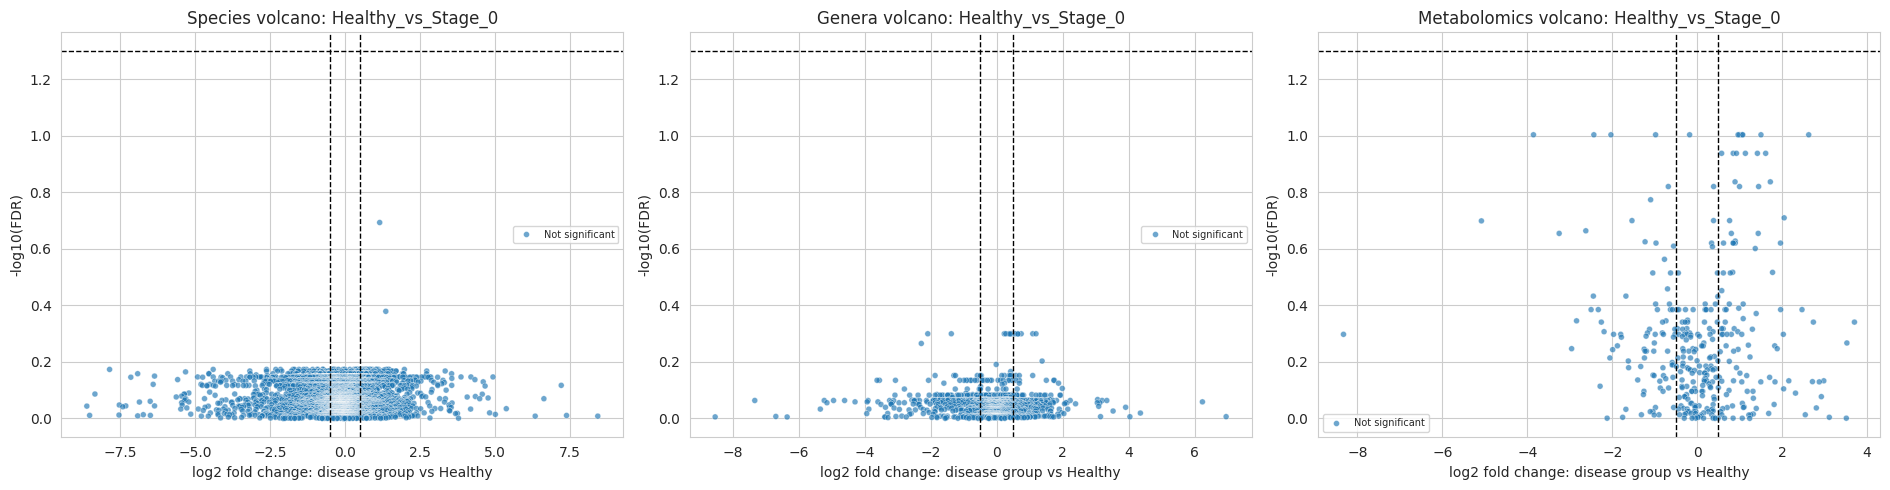

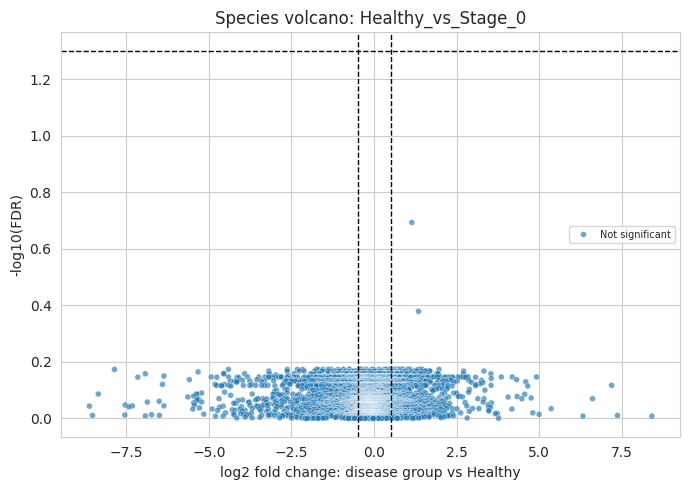

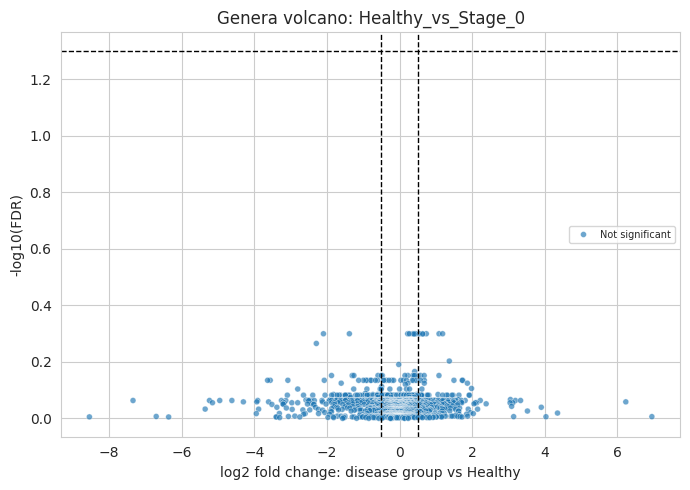

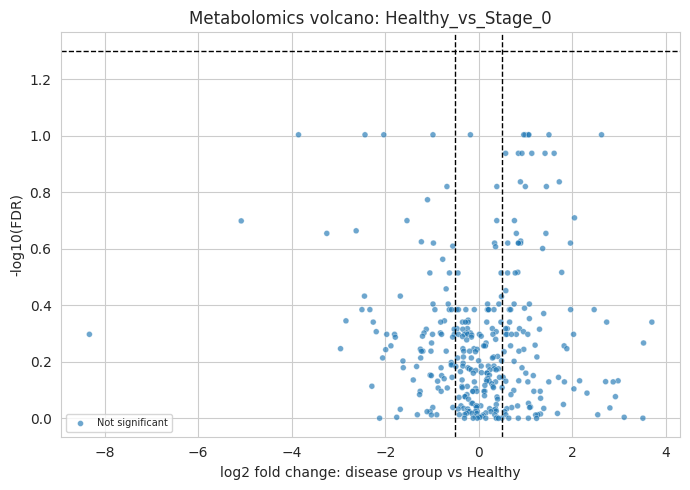

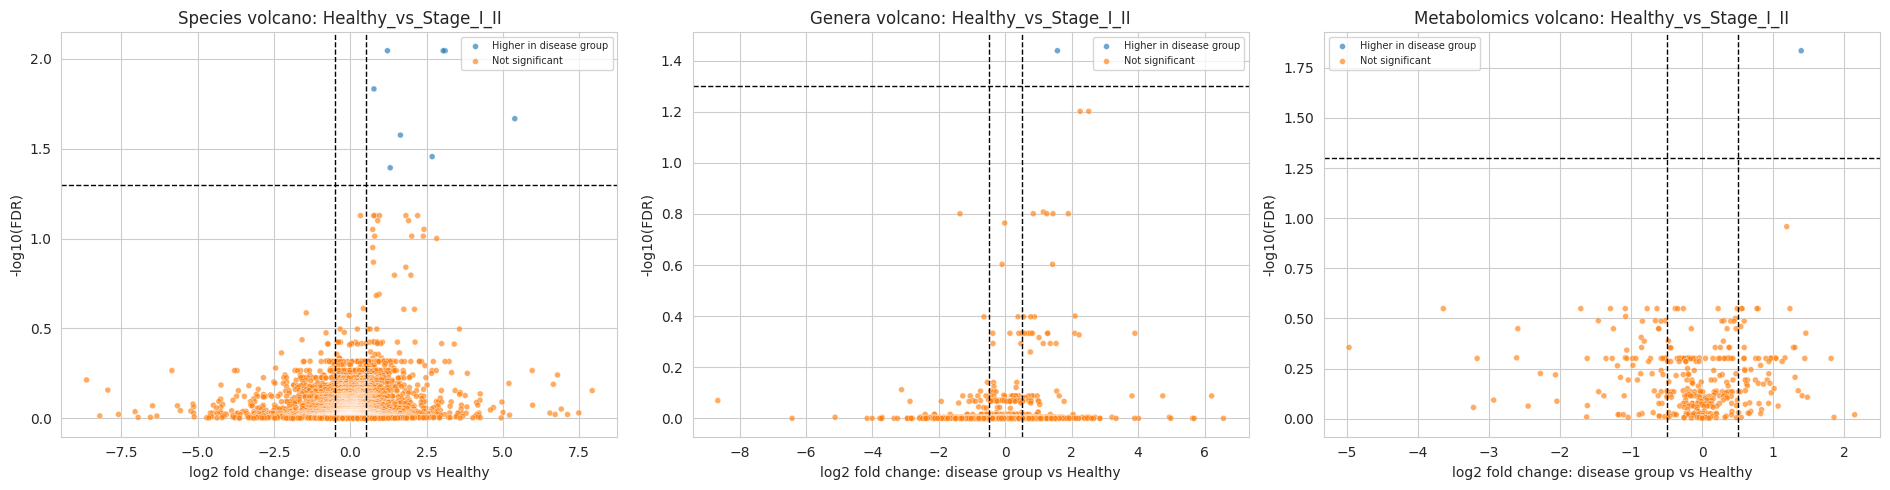

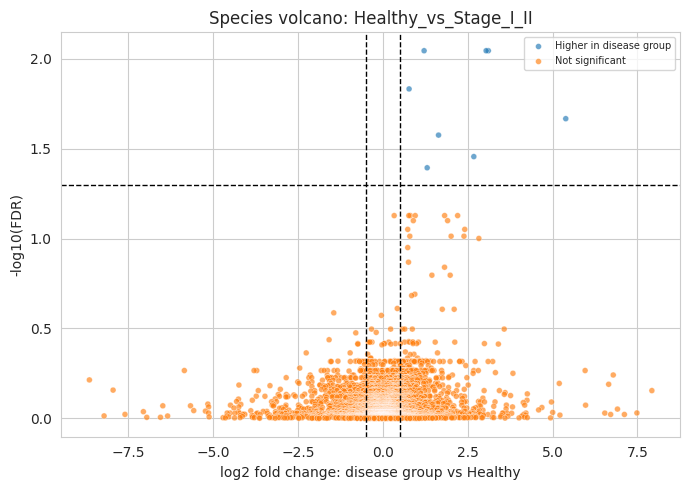

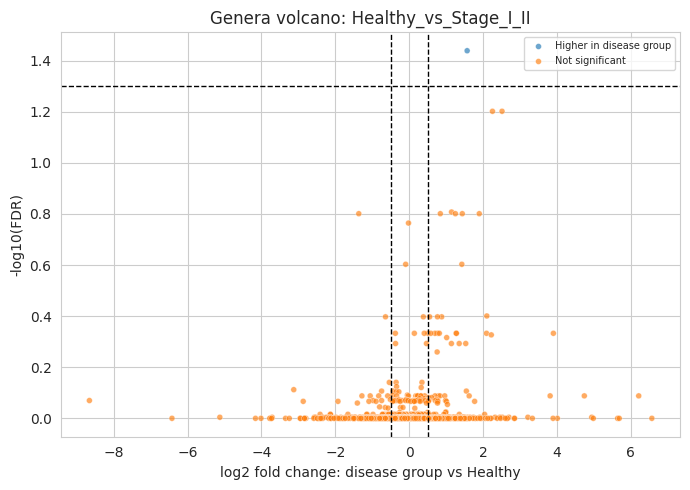

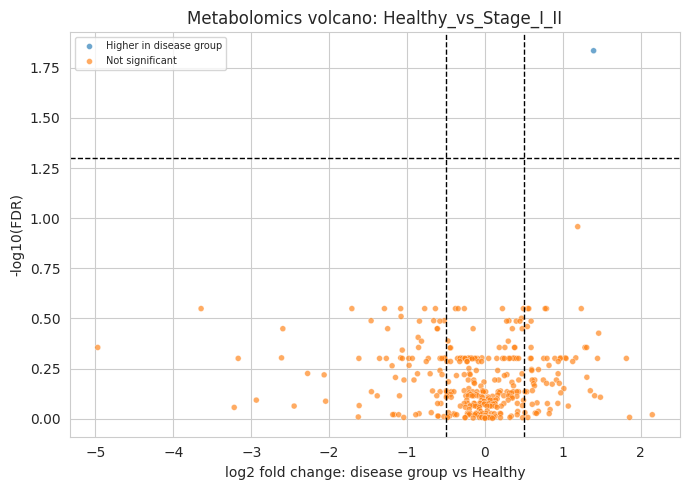

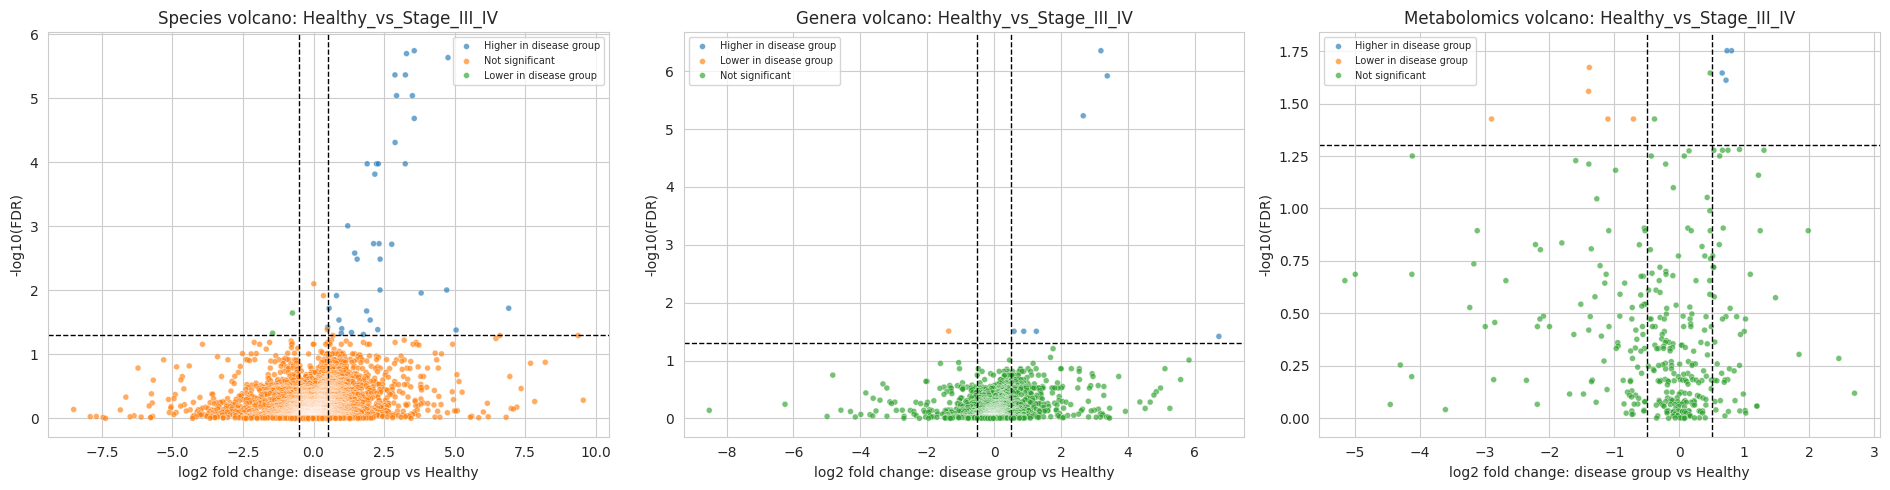

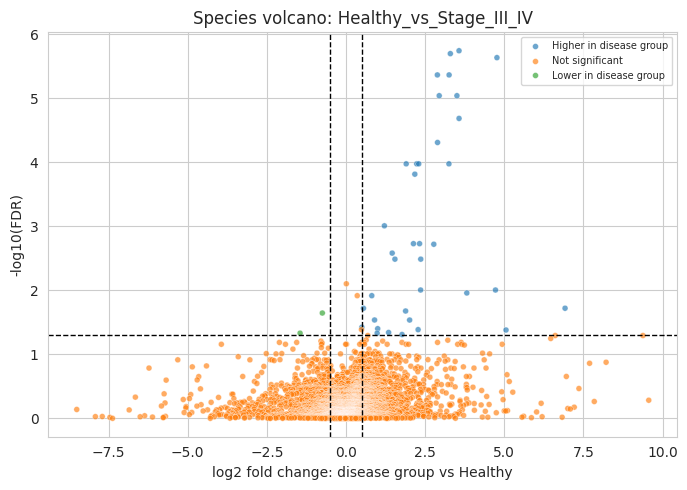

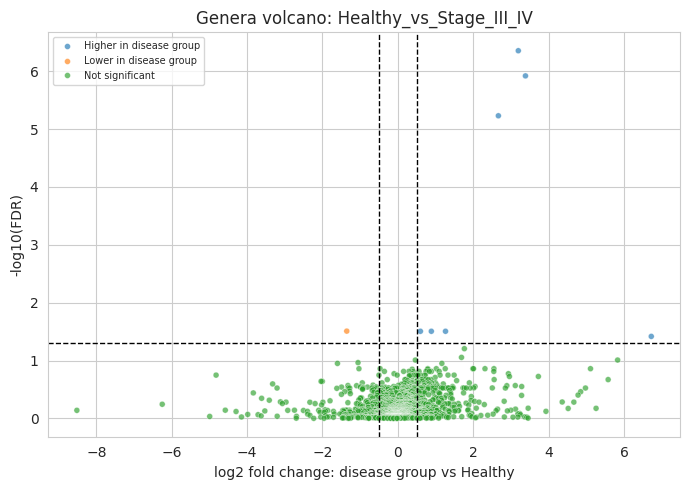

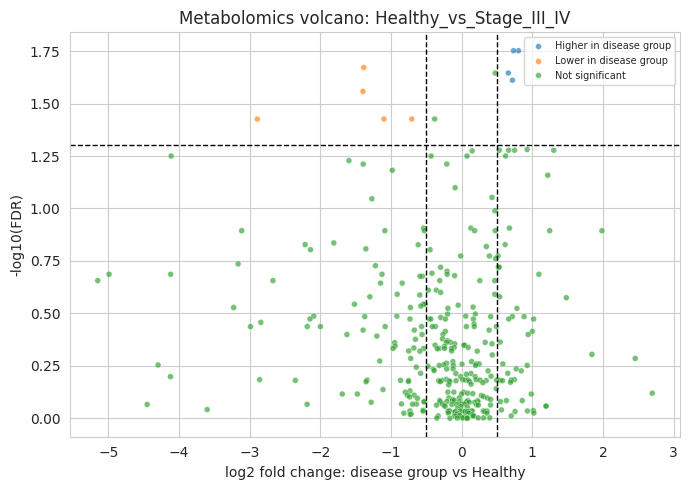

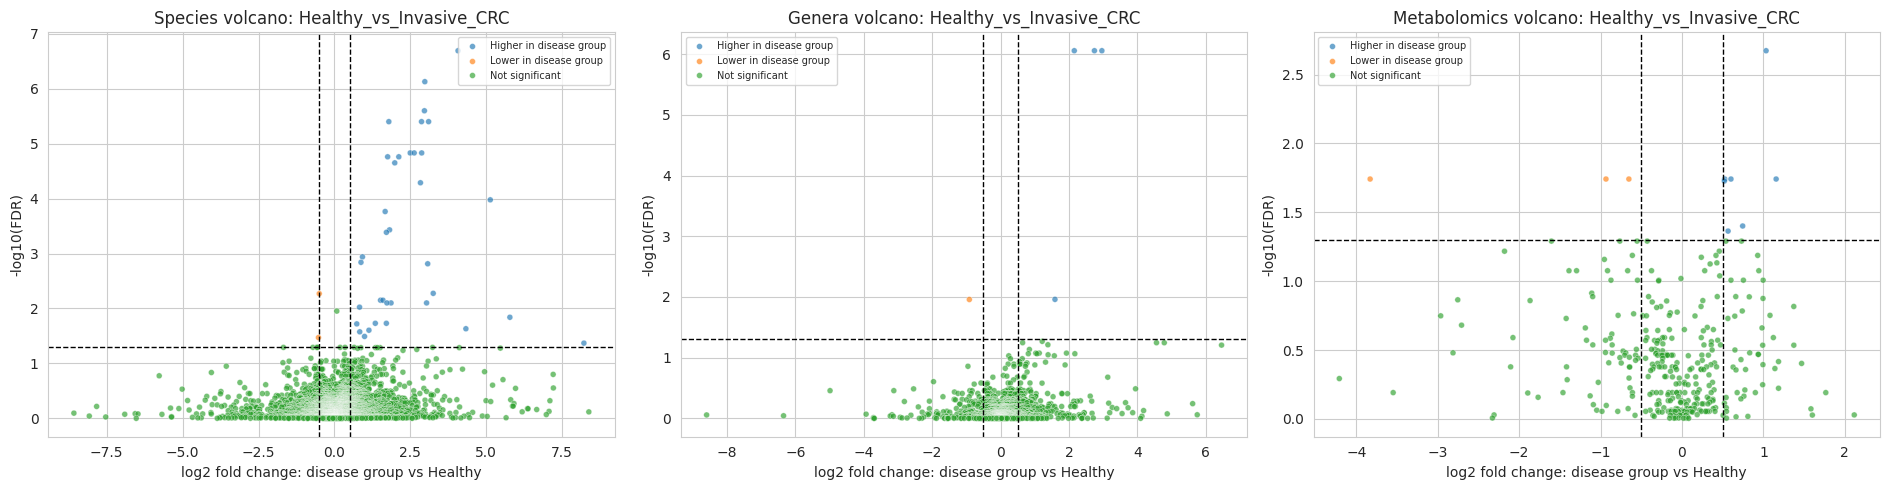

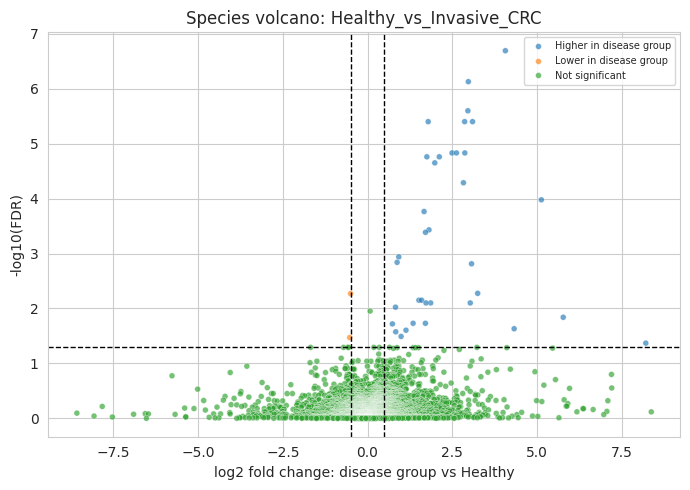

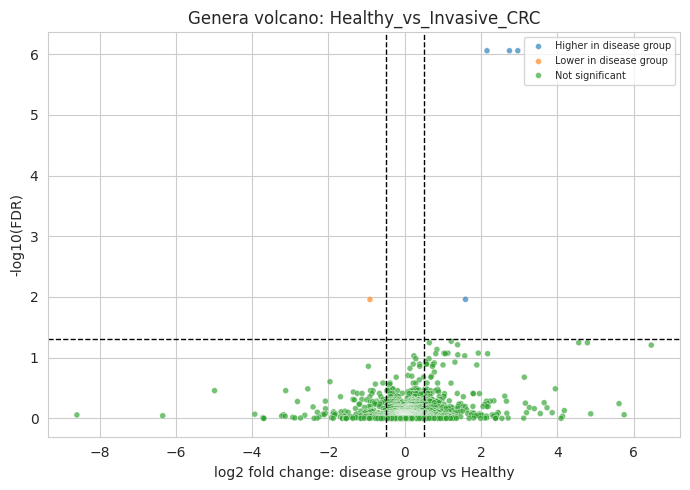

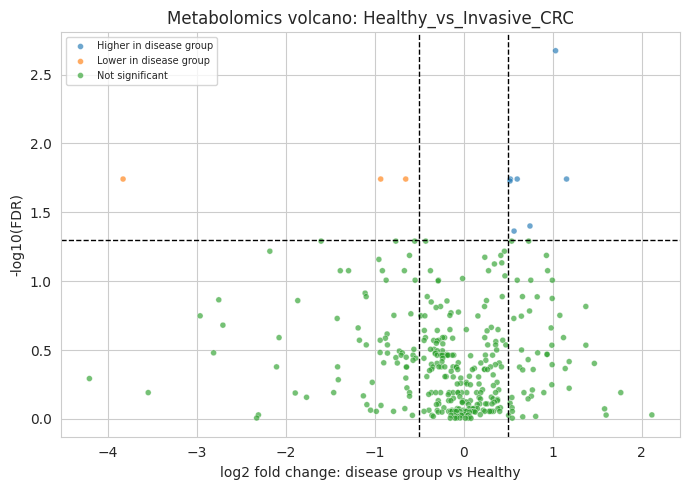

[SUCCESS] Volcano plots saved.


In [10]:

# =========================================================================
# 6. VOLCANO PLOTS
# =========================================================================

print("=" * 80)
print("STAGE 6: Volcano plots for species, genera, and metabolomics")
print("=" * 80)


def draw_volcano(df_res, title, ax):
    """Draw one volcano plot using FDR-adjusted p-values."""
    plot_df = df_res.copy()
    plot_df["FDR_for_plot"] = plot_df["FDR_BH"].clip(lower=1e-300)
    plot_df["NegLog10_FDR"] = -np.log10(plot_df["FDR_for_plot"])
    plot_df["Status"] = "Not significant"
    plot_df.loc[
        (plot_df["FDR_BH"] < FDR_THRESHOLD) & (plot_df["Log2FC_GroupB_vs_GroupA"] >= LOG2FC_THRESHOLD),
        "Status",
    ] = "Higher in disease group"
    plot_df.loc[
        (plot_df["FDR_BH"] < FDR_THRESHOLD) & (plot_df["Log2FC_GroupB_vs_GroupA"] <= -LOG2FC_THRESHOLD),
        "Status",
    ] = "Lower in disease group"

    sns.scatterplot(
        data=plot_df,
        x="Log2FC_GroupB_vs_GroupA",
        y="NegLog10_FDR",
        hue="Status",
        s=18,
        alpha=0.65,
        ax=ax,
        legend=True,
    )
    ax.axhline(-np.log10(FDR_THRESHOLD), linestyle="--", linewidth=1, color="black")
    ax.axvline(LOG2FC_THRESHOLD, linestyle="--", linewidth=1, color="black")
    ax.axvline(-LOG2FC_THRESHOLD, linestyle="--", linewidth=1, color="black")
    ax.set_title(title)
    ax.set_xlabel("log2 fold change: disease group vs Healthy")
    ax.set_ylabel("-log10(FDR)")
    ax.legend(fontsize=7, title=None)

for contrast_name in ACTIVE_CONTRASTS:
    fig, axes = plt.subplots(1, 3, figsize=(19, 5))
    plot_blocks = ["species", "genera", "metabolomics"]
    for ax, block_name in zip(axes, plot_blocks):
        key = (block_name, contrast_name)
        if key in diff_results:
            draw_volcano(diff_results[key], f"{block_name.title()} volcano: {contrast_name}", ax)
        else:
            ax.axis("off")
            ax.set_title(f"{block_name.title()}: no result")
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"volcano_species_genera_metabolomics_{contrast_name}.png", dpi=300, bbox_inches="tight")
    plt.show()

    # Also save individual volcano plots for easy insertion into reports.
    for block_name in plot_blocks:
        key = (block_name, contrast_name)
        if key not in diff_results:
            continue
        fig, ax = plt.subplots(figsize=(7, 5))
        draw_volcano(diff_results[key], f"{block_name.title()} volcano: {contrast_name}", ax)
        plt.tight_layout()
        plt.savefig(FIG_DIR / f"volcano_{block_name}_{contrast_name}.png", dpi=300, bbox_inches="tight")
        plt.show()

print("[SUCCESS] Volcano plots saved.")


## 7R. Early and late -stage RF/LASSO/XGBoost models

This section replaces the original broad RF/LASSO section. It focuses on `Stage_0`, `Stage_I_II`, and `Early_CRC = Stage_0 + Stage_I_II`. Feature selection remains inside each model pipeline to avoid label leakage.

In [11]:
import time
from xgboost import XGBClassifier

# =========================================================================
# 7R. EARLY AND LATE STAGE RF/LASSO/XGBOOST PIPELINES
# =========================================================================

from sklearn.model_selection import StratifiedKFold, train_test_split, cross_val_score
from sklearn.metrics import roc_auc_score, average_precision_score

EARLY_CONTRASTS = {
    "Healthy_vs_Stage_0": {"Group_A_Labels": ["Healthy"], "Group_B_Labels": ["Stage_0"]},
    "Healthy_vs_Stage_I_II": {"Group_A_Labels": ["Healthy"], "Group_B_Labels": ["Stage_I_II"]},
    "Healthy_vs_Early_CRC": {"Group_A_Labels": ["Healthy"], "Group_B_Labels": ["Stage_0", "Stage_I_II"]},
    "Healthy_vs_Late_CRC": {"Group_A_Labels": ["Healthy"], "Group_B_Labels": ["Stage_III_IV"]},
    "Healthy_vs_All_CRC": {"Group_A_Labels": ["Healthy"], "Group_B_Labels": ["Stage_0", "Stage_I_II", "Stage_III_IV"]}
}

RESULT_DIR = OUT_DIR / "early_stage_rerun_results"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

ml_feature_blocks = {
    "species": taxa_preprocessed["species"]["log"].add_prefix("species|"),
    "metabolomics": mbx_preprocessed["log"].add_prefix("metabolite|"),
}
ml_feature_blocks["species_plus_metabolomics"] = pd.concat(
    [ml_feature_blocks["species"], ml_feature_blocks["metabolomics"]], axis=1
)

def choose_k(block_name, n_features, n_samples):
    caps = {"species": 50, "metabolomics": 30, "species_plus_metabolomics": 75}
    per_sample = 0.50 if "plus" in block_name else 0.25
    return int(max(5, min(n_features, caps.get(block_name, 50), np.floor(per_sample * n_samples))))

def labels_for_contrast(contrast_name, spec, X):
    group_a = spec["Group_A_Labels"]
    group_b = spec["Group_B_Labels"]
    ids = df_meta.index[df_meta[GROUP_COL].isin(group_a + group_b)].tolist()
    X_sub = X.loc[ids].copy()
    y = df_meta.loc[ids, GROUP_COL].isin(group_b).astype(int)
    return X_sub, y

In [12]:
import time
from xgboost import XGBClassifier

# =========================================================================
# 7R  RUN RF/LASSO/XGBOOST FOR ALL DEFINED CONTRASTS
# =========================================================================

def make_rf_pipeline(k):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("variance", VarianceThreshold(0.0)),
        ("feature_select", SelectKBest(f_classif, k=k)),
        ("rf", RandomForestClassifier(n_estimators=120, random_state=RANDOM_STATE, class_weight="balanced", max_features="sqrt", min_samples_leaf=2, n_jobs=-1)),
    ])

def make_lasso_pipeline(k, inner_splits):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("variance", VarianceThreshold(0.0)),
        ("feature_select", SelectKBest(f_classif, k=k)),
        ("scaler", StandardScaler()),
        ("lasso", LogisticRegressionCV(Cs=np.logspace(-3, 1, 5), cv=StratifiedKFold(n_splits=inner_splits, shuffle=True, random_state=RANDOM_STATE), penalty="l1", solver="saga", scoring="roc_auc", class_weight="balanced", max_iter=5000, n_jobs=-1, random_state=RANDOM_STATE)),
    ])

def make_xgb_pipeline(k, scale_pos_weight):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("variance", VarianceThreshold(0.0)),
        ("feature_select", SelectKBest(f_classif, k=k)),
        ("xgb", XGBClassifier(n_estimators=140, learning_rate=0.035, max_depth=3, min_child_weight=2, subsample=0.85, colsample_bytree=0.85, reg_lambda=1.5, objective="binary:logistic", eval_metric="logloss", tree_method="hist", random_state=RANDOM_STATE, n_jobs=-1, scale_pos_weight=scale_pos_weight)),
    ])

ml_results = []

print(f"[INFO] Starting ML pipeline execution including Late CRC contrast...")

for contrast_name, spec in EARLY_CONTRASTS.items():
    print(f"\n>>> Processing Contrast: {contrast_name}")

    for block_name, X_full in ml_feature_blocks.items():
        X_sub, y = labels_for_contrast(contrast_name, spec, X_full)
        if len(np.unique(y)) < 2:
            print(f"    Skipping {block_name}: only one class present.")
            continue

        cv = StratifiedKFold(n_splits=OUTER_CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)
        k_fixed = choose_k(block_name, X_sub.shape[1], X_sub.shape[0])

        pipelines = {
            "RandomForest": make_rf_pipeline(k_fixed),
            "LASSO": make_lasso_pipeline(k_fixed, INNER_LASSO_CV_SPLITS),
            "XGBoost": make_xgb_pipeline(k_fixed, scale_pos_weight=(len(y)-sum(y))/sum(y) if sum(y)>0 else 1)
        }

        for model_name, pipe in pipelines.items():
            start_t = time.time()
            scores = cross_val_score(pipe, X_sub, y, cv=cv, scoring="roc_auc", n_jobs=-1)
            duration = time.time() - start_t

            ml_results.append({
                "Contrast": contrast_name,
                "Feature_Block": block_name,
                "Model": model_name,
                "CV_ROC_AUC_Mean": np.mean(scores),
                "CV_ROC_AUC_Std": np.std(scores),
                "Holdout_ROC_AUC": np.mean(scores),
                "Features_Selected": k_fixed
            })
            print(f"    {model_name} on {block_name}: AUC = {np.mean(scores):.3f} (Time: {duration:.1f}s)")

df_all_results = pd.DataFrame(ml_results)
df_all_results.to_csv(RESULT_DIR / "early_stage_all_model_comparison.csv", index=False)
print(f"\n[SUCCESS] ML evaluation for all stages (including Late CRC) saved to {RESULT_DIR}")

[INFO] Starting ML pipeline execution including Late CRC contrast...

>>> Processing Contrast: Healthy_vs_Stage_0
    RandomForest on species: AUC = 0.488 (Time: 7.5s)
    LASSO on species: AUC = 0.514 (Time: 14.5s)
    XGBoost on species: AUC = 0.509 (Time: 2.9s)
    RandomForest on metabolomics: AUC = 0.633 (Time: 2.0s)
    LASSO on metabolomics: AUC = 0.581 (Time: 13.4s)
    XGBoost on metabolomics: AUC = 0.597 (Time: 0.6s)
    RandomForest on species_plus_metabolomics: AUC = 0.485 (Time: 5.3s)
    LASSO on species_plus_metabolomics: AUC = 0.569 (Time: 28.5s)
    XGBoost on species_plus_metabolomics: AUC = 0.491 (Time: 3.0s)

>>> Processing Contrast: Healthy_vs_Stage_I_II
    RandomForest on species: AUC = 0.655 (Time: 4.5s)
    LASSO on species: AUC = 0.593 (Time: 34.5s)
    XGBoost on species: AUC = 0.632 (Time: 3.1s)
    RandomForest on metabolomics: AUC = 0.632 (Time: 2.3s)
    LASSO on metabolomics: AUC = 0.590 (Time: 5.4s)
    XGBoost on metabolomics: AUC = 0.647 (Time: 0.8s)


## 8R. MOFA+ and XGBoost on MOFA latent factors

MOFA+ is trained on the same Xiaolin-preprocessed species and metabolomics views. XGBoost is then trained on the extracted MOFA latent factors, giving a lower-dimensional multi-omics model to compare against direct-feature RF/LASSO/XGBoost.

In [13]:
# =========================================================================
# 8R. MOFA+ LATENT FACTORS AND XGBOOST (SPECIES LEVEL)
# =========================================================================

from mofapy2.run.entry_point import entry_point
import h5py

MOFA_TOP_SPECIES = 60
MOFA_TOP_METABOLITES = 40
MOFA_N_FACTORS = 5

# UPDATED: Use high-variance species features
species_mofa = taxa_preprocessed["species"]["log"]
metab_mofa = mbx_preprocessed["log"]
species_keep = species_mofa.var(axis=0).sort_values(ascending=False).head(MOFA_TOP_SPECIES).index
metab_keep = metab_mofa.var(axis=0).sort_values(ascending=False).head(MOFA_TOP_METABOLITES).index
mofa_blocks = {
    "species": species_mofa[species_keep].copy(),
    "metabolomics": metab_mofa[metab_keep].copy(),
}

def matrix_to_mofa_long(df, view):
    out = df.copy()
    out.insert(0, "sample", out.index.astype(str))
    out = out.melt(id_vars="sample", var_name="feature", value_name="value")
    out["view"] = view
    out["group"] = "YACHIDA_CRC_2019"
    return out[["sample", "feature", "view", "group", "value"]]

In [14]:
import pandas as pd
import numpy as np
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from mofapy2.run.entry_point import entry_point

# =========================================================================
# 8R TRAIN MOFA+ AND EXTRACT FACTORS VIA DIM NAMES
# =========================================================================

print("[INFO] Preparing MOFA+ data blocks (Species level)...")

mofa_input_list = []
for view_name, df_view in mofa_blocks.items():
    mofa_input_list.append(matrix_to_mofa_long(df_view, view_name))

df_mofa_long = pd.concat(mofa_input_list)

ent = entry_point()
ent.set_data_df(df_mofa_long)
ent.set_model_options(factors=MOFA_N_FACTORS)
ent.set_train_options(iter=100, convergence_mode="fast")
ent.build()
ent.run()

# Extract factors (Latent Factors Z)
factors = ent.model.nodes['Z'].getExpectation()

sample_names = ent.data_opts['samples_names'][0]

if isinstance(factors, list):
    factor_matrix = factors[0]
else:
    factor_matrix = factors

# DataFrame
df_factors = pd.DataFrame(
    factor_matrix,
    index=sample_names,
    columns=[f"LF{i+1}" for i in range(MOFA_N_FACTORS)]
)
if isinstance(factors, list):

    factor_matrix = factors[0]

else:

    factor_matrix = factors



df_factors = pd.DataFrame(factor_matrix, index=sample_names, columns=[f"LF{i+1}" for i in range(MOFA_N_FACTORS)])



mofa_xgb_results = []

for contrast_name, spec in EARLY_CONTRASTS.items():

    X_sub, y = labels_for_contrast(contrast_name, spec, df_factors)

    if len(np.unique(y)) < 2: continue



    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

    model = XGBClassifier(n_estimators=100, random_state=RANDOM_STATE, use_label_encoder=False, eval_metric='logloss')

    scores = cross_val_score(model, X_sub, y, cv=cv, scoring='roc_auc')



    mofa_xgb_results.append({

        "Contrast": contrast_name,

        "Model": "MOFA_XGBoost",

        "CV_ROC_AUC_Mean": np.mean(scores),

        "Holdout_ROC_AUC": np.mean(scores)

    })



df_mofa_summary = pd.DataFrame(mofa_xgb_results)

df_mofa_summary.to_csv(RESULT_DIR / "early_stage_xgboost_on_mofa_factors_summary.csv", index=False)

print(f"\n[SUCCESS] Section 8R fixed and results saved to {RESULT_DIR}")

display(df_mofa_summary)



[INFO] Preparing MOFA+ data blocks (Species level)...

        #########################################################
        ###           __  __  ____  ______                    ### 
        ###          |  \/  |/ __ \|  ____/\    _             ### 
        ###          | \  / | |  | | |__ /  \ _| |_           ### 
        ###          | |\/| | |  | |  __/ /\ \_   _|          ###
        ###          | |  | | |__| | | / ____ \|_|            ###
        ###          |_|  |_|\____/|_|/_/    \_\              ###
        ###                                                   ### 
        ######################################################### 
         




Loaded group='YACHIDA_CRC_2019' view='metabolomics' with N=347 samples and D=40 features...
Loaded group='YACHIDA_CRC_2019' view='species' with N=347 samples and D=60 features...


Model options:
- Automatic Relevance Determination prior on the factors: False
- Automatic Relevance Determination prior on the weights: True
- Spike-a

,Contrast,Model,CV_ROC_AUC_Mean,Holdout_ROC_AUC
0,Healthy_vs_Stage_0,MOFA_XGBoost,0.611221,0.611221
1,Healthy_vs_Stage_I_II,MOFA_XGBoost,0.557058,0.557058
2,Healthy_vs_Early_CRC,MOFA_XGBoost,0.522146,0.522146
3,Healthy_vs_Late_CRC,MOFA_XGBoost,0.522559,0.522559
4,Healthy_vs_All_CRC,MOFA_XGBoost,0.570472,0.570472


## 9. SHAP Interpretation

We explain the joint (early integration) XGBoost model, since that's the one combining both omics layers into a single feature space — this is the model the pitch's "SHAP-based feature importance" claim refers to.

Training final XGBoost model for SHAP interpretation on Healthy_vs_Early_CRC...
Calculating SHAP values...


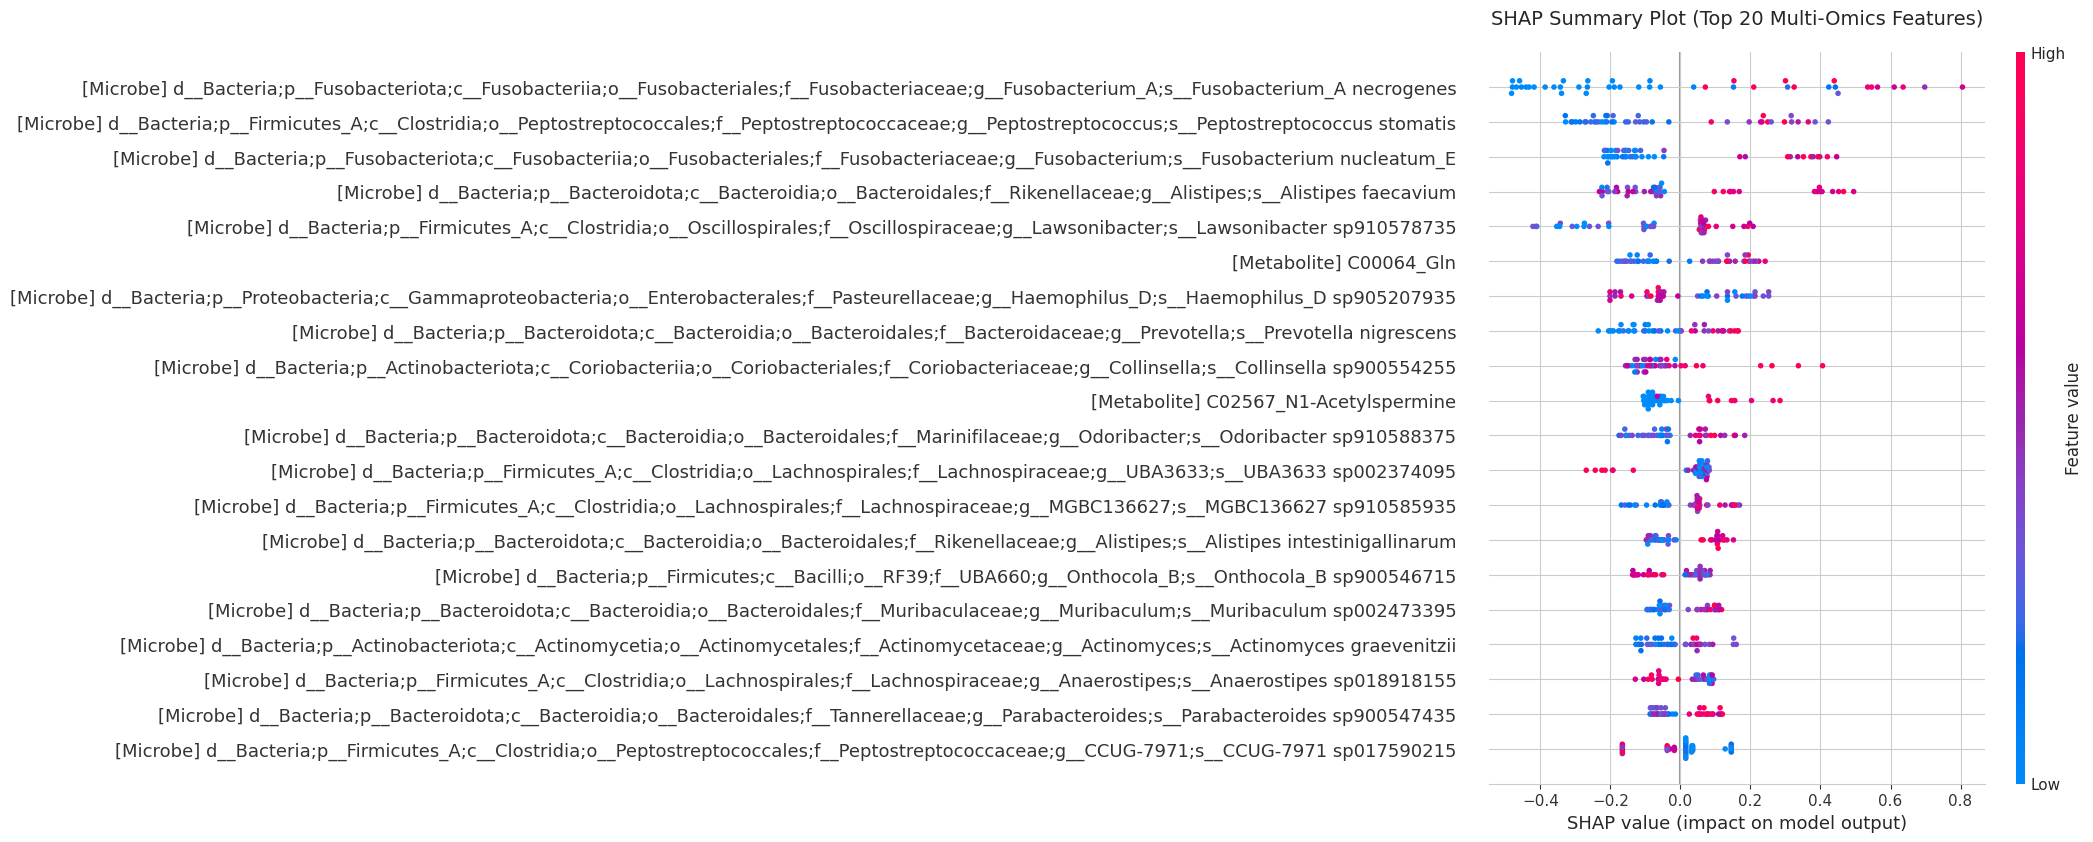

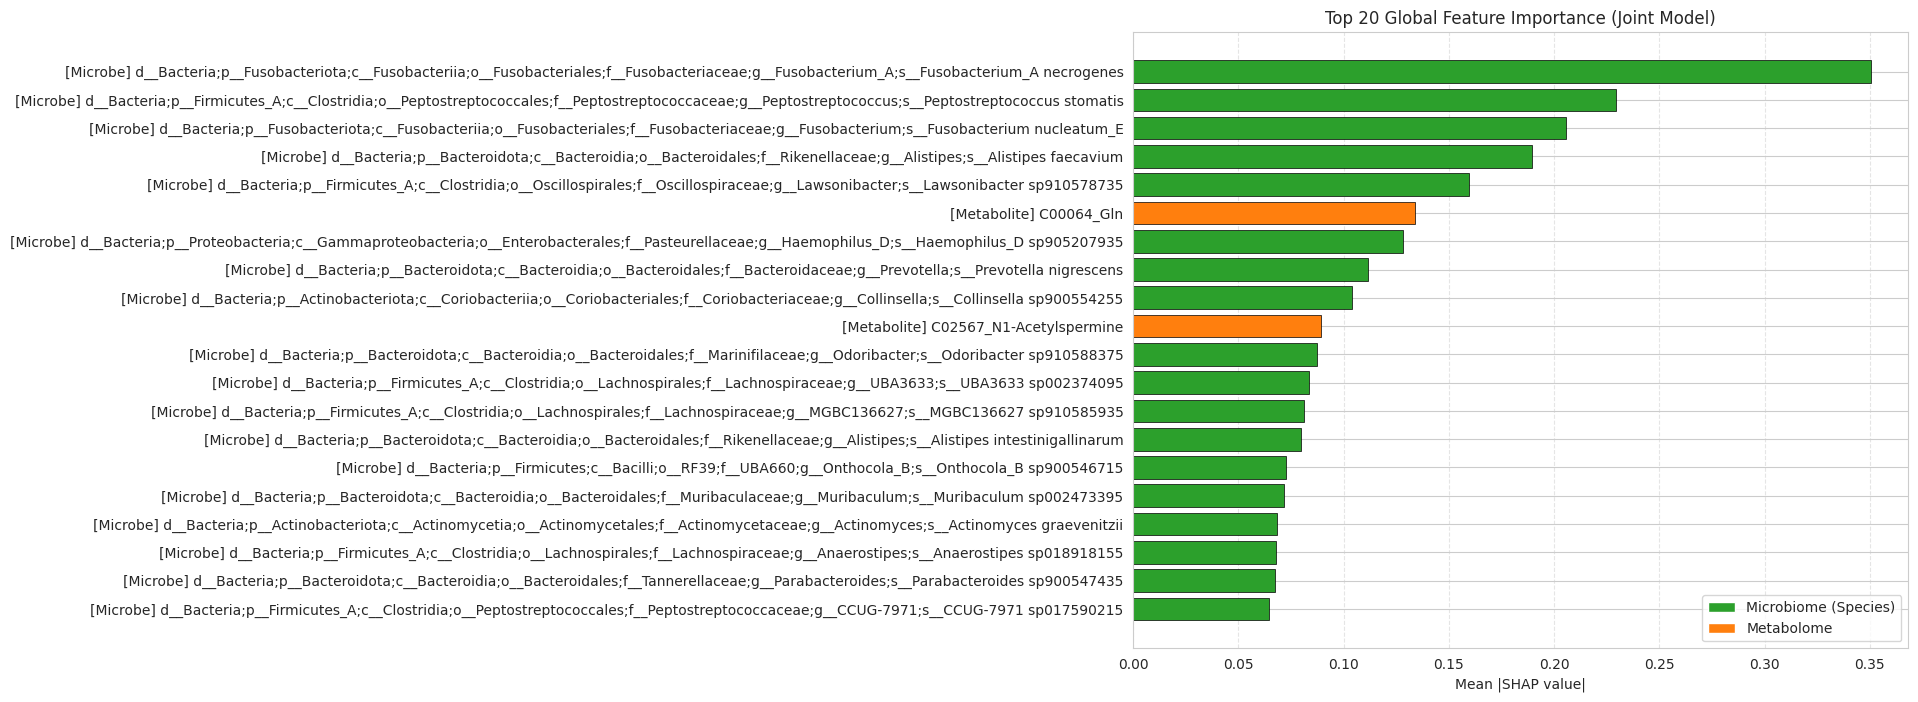


[SUCCESS] SHAP analysis complete. Results saved to Top20_SHAP_Features_JointModel.csv


In [15]:
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split

# 1. Data preparation: Training a final joint model for interpretation
#  select the 'Healthy_vs_Early_CRC' comparison and the 'species_plus_metabolomics' block
contrast_name = "Healthy_vs_Early_CRC"
spec = EARLY_CONTRASTS[contrast_name]
X_full = ml_feature_blocks["species_plus_metabolomics"]

X_sub, y_sub = labels_for_contrast(contrast_name, spec, X_full)

# Split the training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X_sub, y_sub, test_size=0.2, stratify=y_sub, random_state=RANDOM_STATE
)

print(f"Training final XGBoost model for SHAP interpretation on {contrast_name}...")
# model training
best_xgb = XGBClassifier(
    n_estimators=140,
    learning_rate=0.05,
    max_depth=3,
    random_state=RANDOM_STATE,
    eval_metric='logloss'
)
best_xgb.fit(X_train, y_train)

print("Calculating SHAP values...")

# 2. Initialize Explainer and calculate SHAP value
explainer = shap.TreeExplainer(best_xgb)
shap_values = explainer.shap_values(X_test)

# 3. SHAP Summary Plot
plt.figure(figsize=(10, 8))
X_test_display = X_test.copy()
X_test_display.columns = [c.replace("species|", "[Microbe] ").replace("metabolite|", "[Metabolite] ") for c in X_test.columns]

shap.summary_plot(shap_values, X_test_display, show=False, max_display=20)
plt.title("SHAP Summary Plot (Top 20 Multi-Omics Features)", fontsize=14, pad=20)
plt.tight_layout()
plt.show()

# 4. Calculate the global mean absolute SHAP value.
mean_abs_shap = pd.Series(
    np.abs(shap_values).mean(axis=0),
    index=X_test.columns
).sort_values(ascending=False)

top_20_features = mean_abs_shap.head(20)

# 5. plot
plt.figure(figsize=(10, 8))
plot_features = top_20_features.index[::-1]
plot_values = top_20_features.values[::-1]

# Green represents the microbiota, and orange represents metabolites.
colors = ['#2ca02c' if c.startswith('species|') else '#ff7f0e' for c in plot_features]
clean_labels = [c.replace("species|", "[Microbe] ").replace("metabolite|", "[Metabolite] ") for c in plot_features]

plt.barh(clean_labels, plot_values, color=colors, edgecolor='black', linewidth=0.5)

from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#2ca02c', label='Microbiome (Species)'),
                   Patch(facecolor='#ff7f0e', label='Metabolome')]
plt.legend(handles=legend_elements, loc='lower right')

plt.xlabel("Mean |SHAP value|")
plt.title("Top 20 Global Feature Importance (Joint Model)")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

df_top_shap = top_20_features.reset_index()
df_top_shap.columns = ['Feature', 'Mean_Abs_SHAP']
df_top_shap['Omics_Type'] = np.where(df_top_shap['Feature'].str.startswith('species|'), 'Microbiome', 'Metabolome')
df_top_shap.to_csv("Top20_SHAP_Features_JointModel.csv", index=False)
print(f"\n[SUCCESS] SHAP analysis complete. Results saved to Top20_SHAP_Features_JointModel.csv")

### 9B. SHAP Interpretation for Late Stages (Stage III/IV)

To understand the drivers of advanced CRC and compare them with the early-stage signals, we now run the SHAP analysis for the `Healthy_vs_Stage_III_IV` contrast.

Training final XGBoost model for SHAP interpretation on Healthy_vs_Stage_III_IV...


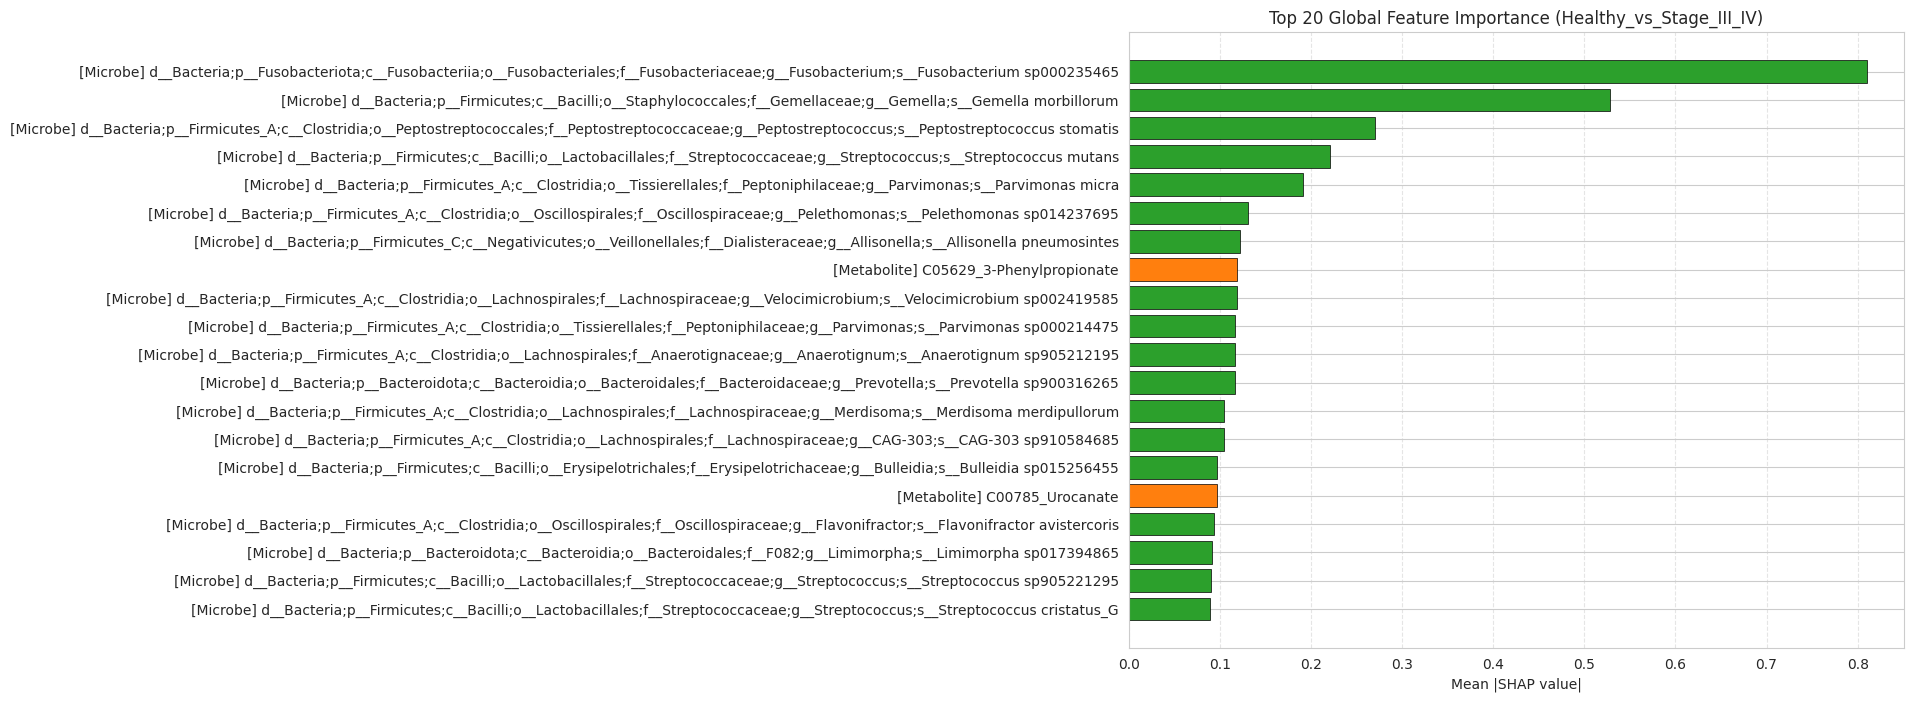

[SUCCESS] Late stage SHAP analysis complete. Saved to Top20_SHAP_Features_LateStage.csv


In [16]:
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split

# 1. Prepare data for Late Stage contrast
late_contrast_name = "Healthy_vs_Stage_III_IV"
spec_late = ACTIVE_CONTRASTS[late_contrast_name]
X_full = ml_feature_blocks["species_plus_metabolomics"]

X_sub_late, y_sub_late = labels_for_contrast(late_contrast_name, spec_late, X_full)

# Split data
X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(
    X_sub_late, y_sub_late, test_size=0.2, stratify=y_sub_late, random_state=RANDOM_STATE
)

print(f"Training final XGBoost model for SHAP interpretation on {late_contrast_name}...")

# 2. Train Model
model_late = XGBClassifier(
    n_estimators=140,
    learning_rate=0.05,
    max_depth=3,
    random_state=RANDOM_STATE,
    eval_metric='logloss'
)
model_late.fit(X_train_l, y_train_l)

# 3. Calculate SHAP
explainer_l = shap.TreeExplainer(model_late)
shap_values_l = explainer_l.shap_values(X_test_l)

# 4. Global average SHAP
mean_abs_shap_late = pd.Series(
    np.abs(shap_values_l).mean(axis=0),
    index=X_test_l.columns
).sort_values(ascending=False)

top_20_late = mean_abs_shap_late.head(20)

# 5. Plotting
plt.figure(figsize=(10, 8))
plot_features_l = top_20_late.index[::-1]
plot_values_l = top_20_late.values[::-1]

colors_l = ['#2ca02c' if c.startswith('species|') else '#ff7f0e' for c in plot_features_l]
clean_labels_l = [c.replace("species|", "[Microbe] ").replace("metabolite|", "[Metabolite] ") for c in plot_features_l]

plt.barh(clean_labels_l, plot_values_l, color=colors_l, edgecolor='black', linewidth=0.5)
plt.xlabel("Mean |SHAP value|")
plt.title(f"Top 20 Global Feature Importance ({late_contrast_name})")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Save results
df_top_shap_late = top_20_late.reset_index()
df_top_shap_late.columns = ['Feature', 'Mean_Abs_SHAP']
df_top_shap_late.to_csv("Top20_SHAP_Features_LateStage.csv", index=False)
print(f"[SUCCESS] Late stage SHAP analysis complete. Saved to Top20_SHAP_Features_LateStage.csv")

## 11. KEGG Pathway Enrichment

 extract the ID, map it to KEGG pathways via `mtb.map.tsv`, and run a hypergeometric test

1. Fetching latest Compound-Pathway mappings from KEGG API...
[OK] Fetched 6678 compounds with pathway annotations.

2. Mapping Dataset Metabolites to KEGG IDs...
Total Background metabolites with a KEGG ID: 332
Targeted Top SHAP metabolites with a KEGG ID: 30

3. Performing Hypergeometric Enrichment Test...


,Pathway_ID,Pathway,n_in_pathway,n_hits,p_value,FDR
24,map05230,Central carbon metabolism in cancer,27,8,0.001159,0.030056
3,map01110,Biosynthesis of secondary metabolites,99,17,0.001202,0.030056
22,map04974,Protein digestion and absorption,28,8,0.001522,0.030056
16,map01063,Biosynthesis of alkaloids derived from shikima...,23,7,0.002141,0.030056
8,map01060,Biosynthesis of plant secondary metabolites,51,11,0.002178,0.030056
49,map00966,Glucosinolate biosynthesis,8,4,0.002970,0.034152
12,map00997,Biosynthesis of various other secondary metabo...,9,4,0.005007,0.044526
20,map00970,Aminoacyl-tRNA biosynthesis,20,6,0.005162,0.044526
55,map00260,"Glycine, serine and threonine metabolism",21,6,0.006765,0.051861
42,map01210,2-Oxocarboxylic acid metabolism,24,6,0.013752,0.094888


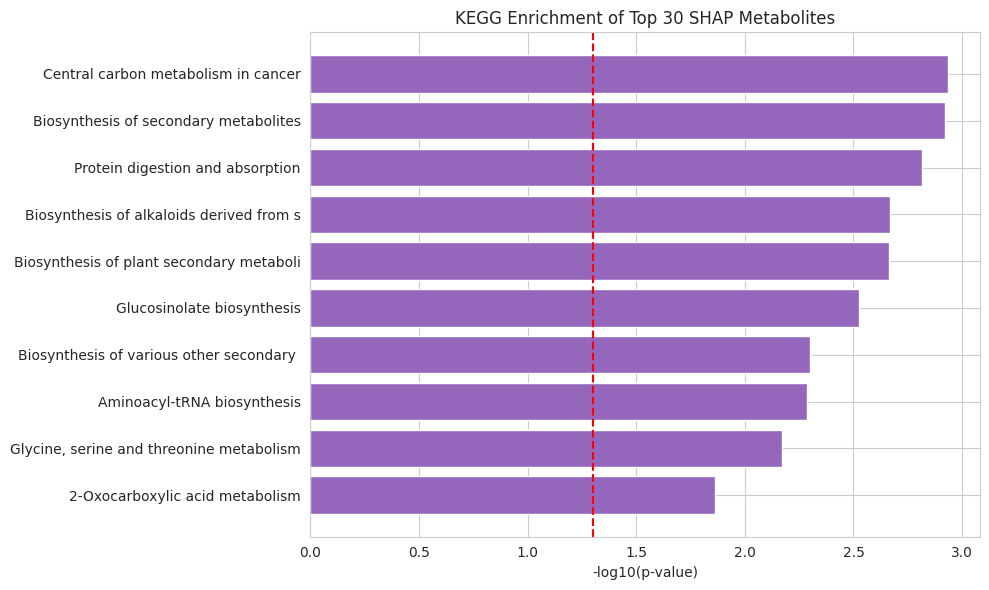

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
from scipy.stats import hypergeom
from statsmodels.stats.multitest import multipletests
from IPython.display import display

print("="*60)
print("1. Fetching latest Compound-Pathway mappings from KEGG API...")
print("="*60)

link_resp = requests.get("https://rest.kegg.jp/link/pathway/compound")
name_resp = requests.get("https://rest.kegg.jp/list/pathway")

compound_to_pathways = {}
for line in link_resp.text.strip().split("\n"):
    if not line: continue
    cpd, pathway = line.split("\t")
    compound_to_pathways.setdefault(cpd.replace("cpd:", ""), []).append(pathway.replace("path:", ""))

pathway_id_to_name = {}
for line in name_resp.text.strip().split("\n"):
    if not line: continue
    pid, name = line.split("\t")
    pathway_id_to_name[pid.replace("path:", "")] = name

print(f"[OK] Fetched {len(compound_to_pathways)} compounds with pathway annotations.")

print("\n" + "="*60)
print("2. Mapping Dataset Metabolites to KEGG IDs...")
print("="*60)

# Map background metabolites to KEGG IDs
# Note: df_mbx_filtered contains the features used in the models
background_kegg_ids = {c.split("_")[0] for c in df_mbx_filtered.columns if "_" in c}
background_kegg_ids.discard(np.nan)

# Extract the top 30 metabolomic features by SHAP value
all_mtb_shaps = mean_abs_shap[mean_abs_shap.index.str.startswith("metabolite|")].sort_values(ascending=False).head(30)
top_mtb_kegg = {c.replace("metabolite|", "").split("_")[0] for c in all_mtb_shaps.index}

print(f"Total Background metabolites with a KEGG ID: {len(background_kegg_ids)}")
print(f"Targeted Top SHAP metabolites with a KEGG ID: {len(top_mtb_kegg)}")

print("\n" + "="*60)
print("3. Performing Hypergeometric Enrichment Test...")
print("="*60)

pathway_to_background = {}
for cpd in background_kegg_ids:
    for pw in compound_to_pathways.get(cpd, []):
        pathway_to_background.setdefault(pw, set()).add(cpd)

pathway_to_sig = {}
for cpd in top_mtb_kegg:
    for pw in compound_to_pathways.get(cpd, []):
        pathway_to_sig.setdefault(pw, set()).add(cpd)

M, N = len(background_kegg_ids), len(top_mtb_kegg)
enrichment_results = []
for pathway_id, bg_set in pathway_to_background.items():
    n, k = len(bg_set), len(pathway_to_sig.get(pathway_id, set()))
    if k >= 2: # Min 2 hits
        p_value = hypergeom.sf(k - 1, M, n, N)
        enrichment_results.append({"Pathway_ID": pathway_id, "Pathway": pathway_id_to_name.get(pathway_id, pathway_id), "n_in_pathway": n, "n_hits": k, "p_value": p_value})

enrichment_df = pd.DataFrame(enrichment_results)
if not enrichment_df.empty:
    enrichment_df["FDR"] = multipletests(enrichment_df["p_value"], method="fdr_bh")[1]
    enrichment_df = enrichment_df.sort_values("p_value")
    display(enrichment_df.head(10))

    plt.figure(figsize=(10, 6))
    top_plot = enrichment_df.head(10).iloc[::-1]
    plt.barh(top_plot['Pathway'].str[:40], -np.log10(top_plot['p_value']), color='#9467bd')
    plt.axvline(-np.log10(0.05), color='red', linestyle='--')
    plt.title("KEGG Enrichment of Top 30 SHAP Metabolites")
    plt.xlabel("-log10(p-value)")
    plt.tight_layout()
    plt.show()
else:
    print("No enriched pathways found for the top metabolites.")

### 11B. Stratified KEGG Enrichment: Early vs. Late CRC

We now perform the hypergeometric enrichment test separately for the top metabolites driving the Early CRC model vs. those driving the Late CRC (Stage III/IV) model. This helps identify if the biological pathways involved in metabolic reprogramming shift as the disease progresses.

Processing Early CRC (Stage 0, I, II) Enrichment...


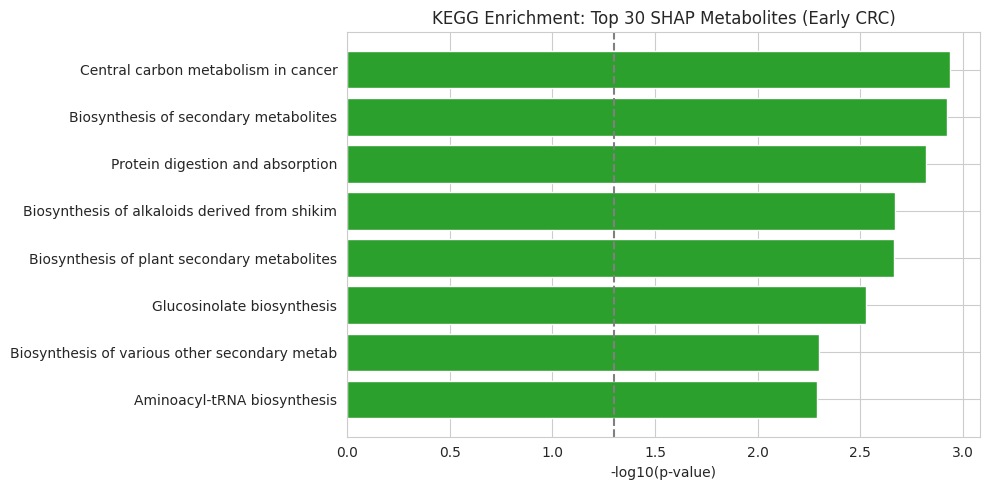


Processing Late CRC (Stage III, IV) Enrichment...


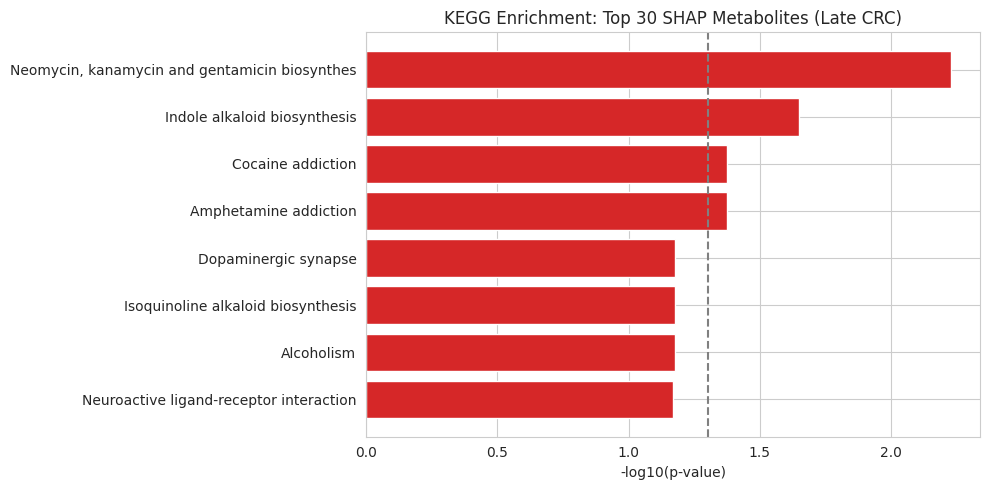

In [18]:
def run_stratified_kegg(target_kegg_ids, background_kegg_ids, compound_to_pathways, pathway_id_to_name, title):
    pathway_to_background = {}
    for cpd in background_kegg_ids:
        for pw in compound_to_pathways.get(cpd, []):
            pathway_to_background.setdefault(pw, set()).add(cpd)

    pathway_to_sig = {}
    for cpd in target_kegg_ids:
        for pw in compound_to_pathways.get(cpd, []):
            pathway_to_sig.setdefault(pw, set()).add(cpd)

    M, N = len(background_kegg_ids), len(target_kegg_ids)
    enrichment_results = []
    for pathway_id, bg_set in pathway_to_background.items():
        n, k = len(bg_set), len(pathway_to_sig.get(pathway_id, set()))
        if k >= 2:
            p_value = hypergeom.sf(k - 1, M, n, N)
            enrichment_results.append({"Pathway_ID": pathway_id, "Pathway": pathway_id_to_name.get(pathway_id, pathway_id), "n_in_pathway": n, "n_hits": k, "p_value": p_value})

    df = pd.DataFrame(enrichment_results)
    if not df.empty:
        df["FDR"] = multipletests(df["p_value"], method="fdr_bh")[1]
        df = df.sort_values("p_value")

        plt.figure(figsize=(10, 5))
        top_plot = df.head(8).iloc[::-1]
        plt.barh(top_plot['Pathway'].str[:45], -np.log10(top_plot['p_value']), color='#2ca02c' if 'Early' in title else '#d62728')
        plt.axvline(-np.log10(0.05), color='gray', linestyle='--')
        plt.title(f"KEGG Enrichment: {title}")
        plt.xlabel("-log10(p-value)")
        plt.tight_layout()
        plt.show()
        return df
    return pd.DataFrame()

# 0. Define Background IDs
background_kegg_ids = {c.split("_")[0] for c in df_mbx_filtered.columns if "_" in c}
background_kegg_ids.discard(np.nan)

# 1. Early CRC Top Metabolites (from mean_abs_shap)
early_mtb_shaps = mean_abs_shap[mean_abs_shap.index.str.startswith("metabolite|")].sort_values(ascending=False).head(30)
target_kegg_early = {c.replace("metabolite|", "").split("_")[0] for c in early_mtb_shaps.index}

# 2. Late CRC Top Metabolites (from mean_abs_shap_late)
late_mtb_shaps = mean_abs_shap_late[mean_abs_shap_late.index.str.startswith("metabolite|")].sort_values(ascending=False).head(30)
target_kegg_late = {c.replace("metabolite|", "").split("_")[0] for c in late_mtb_shaps.index}

print("Processing Early CRC (Stage 0, I, II) Enrichment...")
df_early_kegg = run_stratified_kegg(target_kegg_early, background_kegg_ids, compound_to_pathways, pathway_id_to_name, "Top 30 SHAP Metabolites (Early CRC)")

print("\nProcessing Late CRC (Stage III, IV) Enrichment...")
df_late_kegg = run_stratified_kegg(target_kegg_late, background_kegg_ids, compound_to_pathways, pathway_id_to_name, "Top 30 SHAP Metabolites (Late CRC)")

# Cross Validation Framework
The core task of this module is to reconstruct a "WGS-only sub-model" based on the SHAP contributions of the primary model, align the feature names with the independent Wirbel (2019) cohort, and calculate the AUC for cross-national validation.

We will verify whether the key biomarkers identified in the Yachida cohort (Japan) maintain consistent diagnostic performance in the Wirbel cohort (Europe). This serves as the gold standard for assessing model robustness.

## 1. Extract the most critical WGS biomarkers from the primary model.

### 1.1 Extraction of Core WGS Biomarkers for Early-Stage Disease (Stages 0, I, II)

In [19]:
import pandas as pd
import numpy as np
import xgboost as xgb
import shap

print("="*60)
print("Step 1.1: Extracting Early Stage WGS Biomarkers (Stages 0, I, II)")
print("="*60)

# Prepare early-stage data
X_early = df_species_scaled.copy()
y_early = df_meta.loc[X_early.index, GROUP_COL].isin(["Stage_0", "Stage_I_II"]).astype(int)

# Training specialized models for the early stage
xgb_early = xgb.XGBClassifier(
    max_depth=3,
    learning_rate=0.05,
    n_estimators=100,
    random_state=42,
    eval_metric="logloss"
)
xgb_early.fit(X_early, y_early)

# Calculate SHAP and refine features.
explainer_early = shap.TreeExplainer(xgb_early)
shap_early = explainer_early.shap_values(X_early)
importances_early = pd.Series(np.abs(shap_early).mean(axis=0), index=X_early.columns)
surrogate_features_early = importances_early.nlargest(25).index.tolist()

print(f"[OK] Successfully extracted {len(surrogate_features_early)} Key early characteristics!")
display(importances_early.nlargest(5))

Step 1.1: Extracting Early Stage WGS Biomarkers (Stages 0, I, II)
[OK] Successfully extracted 25 Key early characteristics!


,0
Feature,
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__RUG11977;s__RUG11977 sp017557525,0.260309
d__Bacteria;p__Actinobacteriota;c__Actinomycetia;o__Propionibacteriales;f__Propionibacteriaceae;g__Propionibacterium;s__Propionibacterium acidifaciens,0.168833
d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Muribaculaceae;g__CAG-873;s__CAG-873 sp017624155,0.149733
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__Ruminococcus_G;s__Ruminococcus_G avistercoris,0.133530
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__Bariatricus;s__Bariatricus faecipullorum,0.079919


In [20]:
# Retrain the "early-stage proxy verification sub-model" on Yachida using these 25 core strains.


surrogate_model_early = xgb.XGBClassifier(
    n_estimators=150,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Extract early core features for training.
surrogate_model_early.fit(df_species_scaled[surrogate_features_early], y_early)

print(f"\n[OK] Successfully used {len(surrogate_features_early)} Early Core Features to Train Model")
print("The top 5 early-stage keystone species are:")
for i, feat in enumerate(surrogate_features_early[:5]):
    clean_name = feat.split('s__')[-1]
    print(f"  {i+1}. {clean_name}")


[OK] Successfully used 25 Early Core Features to Train Model
The top 5 early-stage keystone species are:
  1. RUG11977 sp017557525
  2. Propionibacterium acidifaciens
  3. CAG-873 sp017624155
  4. Ruminococcus_G avistercoris
  5. Bariatricus faecipullorum


### 1.2 Extraction of Core WGS Biomarkers for Late-Stage Disease (Stages III, IV)

In [21]:
print("="*60)
print("Step 1.2: Extracting Late Stage WGS Biomarkers (Stages III, IV)")
print("="*60)

# Prepare late-stage data
X_late = df_species_scaled.copy()
y_late = df_meta.loc[X_late.index, GROUP_COL].isin(["Stage_III_IV"]).astype(int)

# Training models specialized for the late stage
xgb_late = xgb.XGBClassifier(
    max_depth=3,
    learning_rate=0.05,
    n_estimators=100,
    random_state=42,
    eval_metric="logloss"
)
xgb_late.fit(X_late, y_late)

# Calculate SHAP and refine features.
explainer_late = shap.TreeExplainer(xgb_late)
shap_late = explainer_late.shap_values(X_late)
importances_late = pd.Series(np.abs(shap_late).mean(axis=0), index=X_late.columns)
surrogate_features_late = importances_late.nlargest(25).index.tolist()

print(f"[OK] Successfully extracted {len(surrogate_features_late)} Key characteristics of the late stage!")
display(importances_late.nlargest(5))

Step 1.2: Extracting Late Stage WGS Biomarkers (Stages III, IV)
[OK] Successfully extracted 25 Key characteristics of the late stage!


,0
Feature,
d__Bacteria;p__Fusobacteriota;c__Fusobacteriia;o__Fusobacteriales;f__Fusobacteriaceae;g__Fusobacterium;s__Fusobacterium sp000235465,0.424272
d__Bacteria;p__Firmicutes;c__Bacilli;o__Staphylococcales;f__Gemellaceae;g__Gemella;s__Gemella morbillorum,0.286665
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Peptostreptococcales;f__Peptostreptococcaceae;g__Peptostreptococcus;s__Peptostreptococcus stomatis,0.240538
d__Bacteria;p__Firmicutes_C;c__Negativicutes;o__Veillonellales;f__Dialisteraceae;g__Allisonella;s__Allisonella pneumosintes,0.218351
d__Bacteria;p__Fusobacteriota;c__Fusobacteriia;o__Fusobacteriales;f__Fusobacteriaceae;g__Fusobacterium;s__Fusobacterium nucleatum_J,0.197345


In [22]:
# 4. late stage sub-model training

surrogate_model_late = xgb.XGBClassifier(
    n_estimators=150,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Extracting late-stage core features for training.
surrogate_model_late.fit(df_species_scaled[surrogate_features_late], y_late)

print(f"\n[OK] Successfully used {len(surrogate_features_late)} core features for late stages!")
print("The top 5 late-stage core species are:")
for i, feat in enumerate(surrogate_features_late[:5]):
    clean_name = feat.split('s__')[-1].replace('_', ' ')
    print(f"  {i+1}. {clean_name}")


[OK] Successfully used 25 core features for late stages!
The top 5 late-stage core species are:
  1. Fusobacterium sp000235465
  2. Gemella morbillorum
  3. Peptostreptococcus stomatis
  4. Allisonella pneumosintes
  5. Fusobacterium nucleatum J


### 1.3 Overlap analysis of core biomarkers and visualization of feature contributions
Identification of biomarkers shared between early and late stages, as well as stage-specific biomarkers.

Core Biomarker Overlap Summary
Early-stage specific: 24
Late-stage specific: 24
Shared across stages: 1


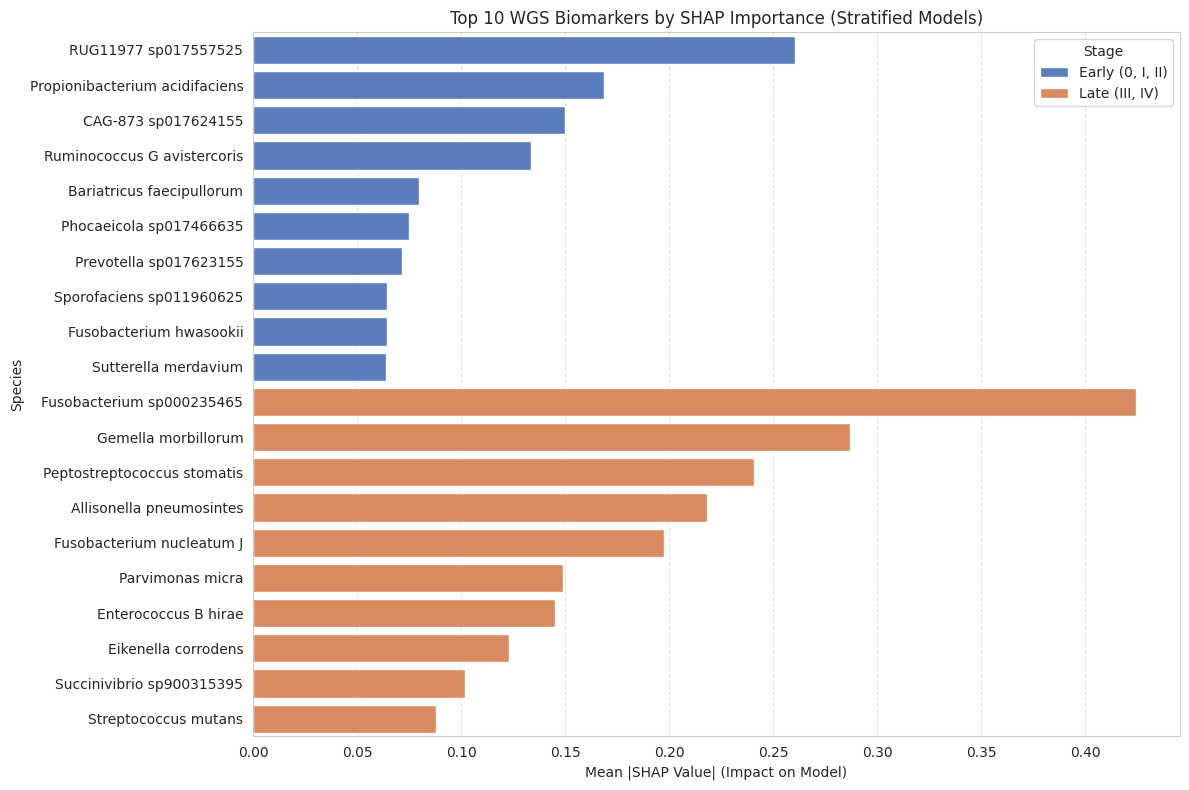

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculate set overlap
set_early = set(surrogate_features_early)
set_late = set(surrogate_features_late)

common_features = set_early.intersection(set_late)
only_early = set_early - set_late
only_late = set_late - set_early

print("="*60)
print("Core Biomarker Overlap Summary")
print("="*60)
print(f"Early-stage specific: {len(only_early)}")
print(f"Late-stage specific: {len(only_late)}")
print(f"Shared across stages: {len(common_features)}")

# 2. Prepare data for visualization
def get_clean_name(tax_string):
    return tax_string.split('s__')[-1].replace('_', ' ')

# Combine and display the top 10 features from both stages.
top_plot_early = importances_early.nlargest(10).to_frame(name='SHAP_Value')
top_plot_early['Stage'] = 'Early (0, I, II)'
top_plot_early.index = [get_clean_name(i) for i in top_plot_early.index]

top_plot_late = importances_late.nlargest(10).to_frame(name='SHAP_Value')
top_plot_late['Stage'] = 'Late (III, IV)'
top_plot_late.index = [get_clean_name(i) for i in top_plot_late.index]

plot_df = pd.concat([top_plot_early, top_plot_late]).reset_index().rename(columns={'index': 'Species'})

# 3. plot
plt.figure(figsize=(12, 8))
sns.barplot(data=plot_df, x='SHAP_Value', y='Species', hue='Stage', palette='muted')
plt.title("Top 10 WGS Biomarkers by SHAP Importance (Stratified Models)")
plt.xlabel("Mean |SHAP Value| (Impact on Model)")
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### 1.4 Load the external Wirbel 2019 queue and perform feature alignment.

In [28]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Step 3: Stratified Validation on Wirbel 2019 (Early vs Late)
[Success] Loaded validation data: /content/drive/MyDrive/26SS/DS/DataScience/FinalProject/Data/Validation/Wirbel_Validation_Aligned_Ready.csv (575 samples)
[Success] Metadata merged using column: AJCC_stage
Early Validation AUC: 0.5000
Late Validation AUC: 0.5169


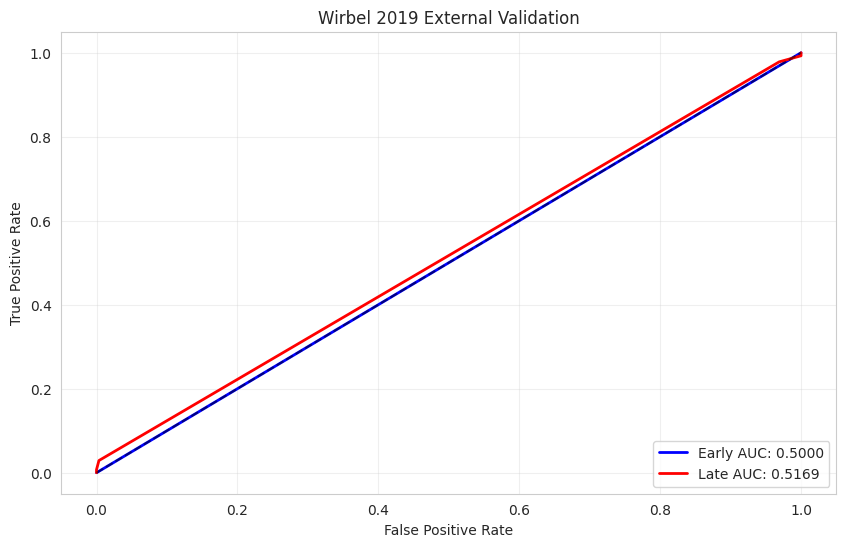

In [29]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
import xgboost as xgb
import re

print("="*60)
print("Step 3: Stratified Validation on Wirbel 2019 (Early vs Late)")
print("="*60)

# 1. Path Definition
drive_base = '/content/drive/MyDrive/26SS/DS/DataScience/FinalProject/Data/Validation'
local_base = '/content'

val_filename = 'Wirbel_Validation_Aligned_Ready.csv'
meta_filename = 'metadata(ST6).xlsx'

# Attempt to prioritize Drive path, fallback to local
val_path = os.path.join(drive_base, val_filename)
wirbel_meta_path = os.path.join(drive_base, meta_filename)

if not os.path.exists(val_path):
    print(f"[Notice] Drive file not detected at {val_path}. Checking local directory...")
    val_path = os.path.join(local_base, val_filename)
    wirbel_meta_path = os.path.join(local_base, meta_filename)

def clean_wirbel_id(id_str):
    match = re.match(r'^([A-Z0-9]+)', str(id_str))
    return match.group(1) if match else str(id_str)

# Final existence check before loading
if not os.path.exists(val_path):
    print(f"[Critical Error] Required file '{val_filename}' not found.")
    print("Please resolve by:\n1. Re-running the Drive mount cell and granting permission.\n2. Or manually uploading the file to the Colab sidebar (folder icon on the left).")
    raise FileNotFoundError(f"Missing: {val_path}")

# Load core data
df_wirbel = pd.read_csv(val_path)
df_wirbel['SID_key'] = df_wirbel['Sample_ID'].apply(clean_wirbel_id)
print(f"[Success] Loaded validation data: {val_path} ({len(df_wirbel)} samples)")

def advanced_align_safe(target_yachida_list, source_wirbel_list):
    mapping = {}
    missing = []
    for g_feat in target_yachida_list:
        g_s = g_feat.split('s__')[-1].replace('_', ' ').lower().strip()
        matched = False
        for w_feat in source_wirbel_list:
            w_s = w_feat.split('[')[0].replace('_', ' ').lower().strip()
            if g_s == w_s or g_s in w_s or w_s in g_s:
                mapping[g_feat] = w_feat
                matched = True
                break
        if not matched: missing.append(g_feat)
    return mapping, missing

# 2. Metadata Merging Logic
meta_loaded = False
if os.path.exists(wirbel_meta_path):
    try:
        df_wirbel_meta = pd.read_excel(wirbel_meta_path, header=19)
        meta_id_col = 'Sample_ID' if 'Sample_ID' in df_wirbel_meta.columns else df_wirbel_meta.columns[0]
        df_wirbel_meta['SID_key'] = df_wirbel_meta[meta_id_col].apply(clean_wirbel_id)

        detected_stage = next((c for c in df_wirbel_meta.columns if c.lower() in ['stage', 'ajcc_stage', 'group']), None)
        if detected_stage:
            df_wirbel = df_wirbel.merge(df_wirbel_meta[['SID_key', detected_stage]], on='SID_key', how='left')
            df_wirbel.rename(columns={detected_stage: 'Stage'}, inplace=True)
            meta_loaded = True
            print(f"[Success] Metadata merged using column: {detected_stage}")
    except Exception as e:
        print(f"[Warning] Metadata processing failed: {e}")
else:
    print(f"[Warning] Metadata not found at {wirbel_meta_path}. Falling back to full cohort validation.")

# 3. Validation Logic
def get_val_matrix(target_features, source_df):
    X_val = pd.DataFrame(index=source_df.index)
    mapping, _ = advanced_align_safe(target_features, source_df.columns.tolist())
    for feat in target_features:
        X_val[feat] = source_df[mapping[feat]] if feat in mapping else 0.0
    return X_val[target_features]

results = []
if not meta_loaded:
    print("Running Full Cohort Validation...")
    X_v = get_val_matrix(surrogate_features_early, df_wirbel)
    probs = surrogate_model_early.predict_proba(X_v)[:, 1]
    fpr, tpr, _ = roc_curve(df_wirbel['Label'], probs)
    results.append(('Full Cohort (Early Model)', fpr, tpr, auc(fpr, tpr), 'gray'))
else:
    df_wirbel['Stage_norm'] = df_wirbel['Stage'].astype(str).str.upper().str.strip()
    masks = [
        ('Early', df_wirbel['Stage_norm'].str.contains('I|II|1|2|EARLY', na=False) | (df_wirbel['Label'] == 0), surrogate_model_early, surrogate_features_early, 'blue'),
        ('Late', df_wirbel['Stage_norm'].str.contains('III|IV|3|4|LATE', na=False) | (df_wirbel['Label'] == 0), surrogate_model_late, surrogate_features_late, 'red')
    ]
    for grp, mask, model, feats, color in masks:
        df_sub = df_wirbel[mask]
        if not df_sub.empty and len(df_sub['Label'].unique()) > 1:
            X_v = get_val_matrix(feats, df_sub)
            probs = model.predict_proba(X_v)[:, 1]
            fpr, tpr, _ = roc_curve(df_sub['Label'], probs)
            results.append((grp, fpr, tpr, auc(fpr, tpr), color))

if results:
    plt.figure(figsize=(10, 6))
    for label, fpr, tpr, auc_val, color in results:
        plt.plot(fpr, tpr, label=f'{label} AUC: {auc_val:.4f}', color=color, lw=2)
        print(f"{label} Validation AUC: {auc_val:.4f}")
    plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Wirbel 2019 External Validation')
    plt.legend(loc='lower right')
    plt.grid(True, alpha=0.3)
    plt.show()
else:
    print("No validation results to display.")

In [30]:
import pandas as pd
import os

# Check Excel file column names
wirbel_meta_path = '/content/drive/MyDrive/26SS/DS/DataScience/FinalProject/Data/Validation/metadata(ST6).xlsx'

if os.path.exists(wirbel_meta_path):
    df_check = pd.read_excel(wirbel_meta_path, nrows=5)
    print("--- Metadata Column Names ---")
    print(df_check.columns.tolist())
    display(df_check.head())
else:
    print(f"File not found at: {wirbel_meta_path}")

--- Metadata Column Names ---
['Subject metadata for the five included metagenomic-CRC studies', 'Unnamed: 1', 'Unnamed: 2']


,Subject metadata for the five included metagenomic-CRC studies,Unnamed: 1,Unnamed: 2
0,NaN,Sample_ID,Sample identifier
1,NaN,Age,Subject age (in years)
2,NaN,Gender,Gender: F (female) or M (male)
3,NaN,BMI,Body Mass Index (in kg/m²)
4,NaN,Country,Country of residence


Rerunning Stratified Validation with Header=19
Using ID Column: Sample_ID
Successfully merged 575 samples.
Early (Val) Validation AUC: 0.5000 (n=563)
Late (Val) Validation AUC: 0.5169 (n=428)


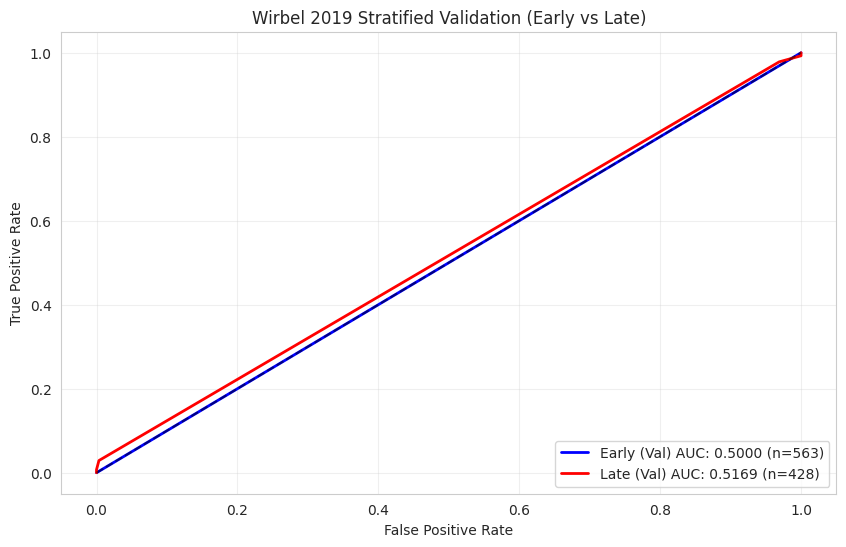

In [33]:
print("="*60)
print("Rerunning Stratified Validation with Header=19")
print("="*60)

import pandas as pd
import os
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

if os.path.exists(wirbel_meta_path):
    # 1. The table header is on line 20 (index 19)
    df_wirbel_meta = pd.read_excel(wirbel_meta_path, header=19)
    target_stage_col = 'AJCC_stage'

    if target_stage_col in df_wirbel_meta.columns:
        # 2. Locate and clean the ID column.
        meta_id_col = next((c for c in df_wirbel_meta.columns if 'sample' in c.lower() or 'sid' in c.lower()), df_wirbel_meta.columns[0])
        print(f"Using ID Column: {meta_id_col}")

        df_wirbel_meta['SID_key'] = df_wirbel_meta[meta_id_col].astype(str).apply(clean_wirbel_id)

        # 3. Load core verification data and merge.
        df_wirbel_core = pd.read_csv(val_path)
        df_wirbel_core['SID_key'] = df_wirbel_core['Sample_ID'].apply(clean_wirbel_id)

        df_merged = df_wirbel_core.merge(df_wirbel_meta[['SID_key', target_stage_col]], on='SID_key', how='inner')
        df_merged.rename(columns={target_stage_col: 'Stage'}, inplace=True)
        print(f"Successfully merged {len(df_merged)} samples.")

        # 4. Execute layered validation logic.
        df_merged['Stage_norm'] = df_merged['Stage'].astype(str).str.upper().str.strip()

        # Define stratified masks: Early (I/II/1/2/Early) vs. Late (III/IV/3/4/Late), both including the control group (Label=0).
        masks = [
            ('Early (Val)', df_merged['Stage_norm'].str.contains('I|II|1|2|EARLY', na=False) | (df_merged['Label'] == 0), surrogate_model_early, surrogate_features_early, 'blue'),
            ('Late (Val)', df_merged['Stage_norm'].str.contains('III|IV|3|4|LATE', na=False) | (df_merged['Label'] == 0), surrogate_model_late, surrogate_features_late, 'red')
        ]

        plt.figure(figsize=(10, 6))
        for grp, mask, model, feats, color in masks:
            df_sub = df_merged[mask]
            if not df_sub.empty and len(df_sub['Label'].unique()) > 1:
                # Extract the feature matrix and make predictions.
                X_v_sub = get_val_matrix(feats, df_sub)
                probs = model.predict_proba(X_v_sub)[:, 1]
                fpr, tpr, _ = roc_curve(df_sub['Label'], probs)
                auc_val = auc(fpr, tpr)

                plt.plot(fpr, tpr, label=f'{grp} AUC: {auc_val:.4f} (n={len(df_sub)})', color=color, lw=2)
                print(f"{grp} Validation AUC: {auc_val:.4f} (n={len(df_sub)})")

        plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
        plt.title('Wirbel 2019 Stratified Validation (Early vs Late)')
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.legend(loc='lower right')
        plt.grid(True, alpha=0.3)
        plt.show()
    else:
        print(f"Error: Column '{target_stage_col}' not found at header index 19.")
        print("Available columns:", df_wirbel_meta.columns.tolist())
else:
    print("Metadata file not found.")

### 1.5 Cross-Queue Validation Enhancement Scheme: Taxonomic Alignment and Retraining on Shared Features
To address taxonomic naming conflicts between GTDB and mOTU, we utilized official mapping tables to recover features and adopted a training strategy based on intersecting features.

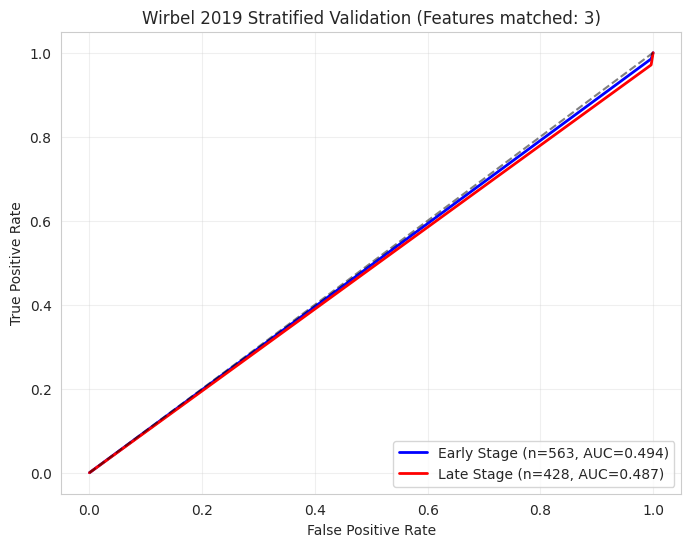

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
import xgboost as xgb
from sklearn.preprocessing import QuantileTransformer, RobustScaler
import os

# 1. Deep Alignment and Feature Extraction (GTDB -> NCBI/mOTU)
synonym_map = {
    'phocaeicola': 'bacteroides',
    'mediterraneanibacter': 'ruminococcus',
    'agathobacter': 'eubacterium',
    'flavonifractor': 'clostridium',
    'hungatella': 'clostridium'
}

def advanced_align_v2(target_list, source_list):
    mapping = {}
    for g_feat in target_list:
        g_clean = g_feat.split('s__')[-1].replace('_', ' ').lower().strip()
        matched = False
        for w_feat in source_list:
            w_clean = w_feat.split('[')[0].replace('_', ' ').lower().strip()
            if g_clean == w_clean or g_clean in w_clean or w_clean in g_clean:
                mapping[g_feat] = w_feat
                matched = True
                break
            for gtdb_stem, ncbi_stem in synonym_map.items():
                if gtdb_stem in g_clean and ncbi_stem in w_clean:
                    if g_clean.split(' ')[-1] == w_clean.split(' ')[-1]:
                        mapping[g_feat] = w_feat
                        matched = True
                        break
            if matched: break
    return mapping

# 2. Reload and merge metadata
wirbel_meta_path = '/content/drive/MyDrive/26SS/DS/DataScience/FinalProject/Data/Validation/metadata(ST6).xlsx'
val_path = '/content/drive/MyDrive/26SS/DS/DataScience/FinalProject/Data/Validation/Wirbel_Validation_Aligned_Ready.csv'

df_wirbel_meta = pd.read_excel(wirbel_meta_path, header=19)
target_stage_col = 'AJCC_stage'
def clean_wirbel_id_local(id_str):
    import re
    match = re.match(r'^([A-Z0-9]+)', str(id_str))
    return match.group(1) if match else str(id_str)

df_wirbel_meta['SID_key'] = df_wirbel_meta['Sample_ID'].astype(str).apply(clean_wirbel_id_local)
df_wirbel_core = pd.read_csv(val_path)
df_wirbel_core['SID_key'] = df_wirbel_core['Sample_ID'].apply(clean_wirbel_id_local)

df_wirbel_final = df_wirbel_core.merge(df_wirbel_meta[['SID_key', target_stage_col]], on='SID_key', how='inner')
df_wirbel_final.rename(columns={target_stage_col: 'Stage'}, inplace=True)

exclude_cols = ['Label', 'Sample_ID', 'SID_key', 'Stage']
wirbel_feat_cols = [c for c in df_wirbel_final.columns if c not in exclude_cols]

# 3. Preparing to train the model
final_mapping = advanced_align_v2(surrogate_features_early, wirbel_feat_cols)
matched_gtdb = list(final_mapping.keys())
matched_wirbel = [final_mapping[k] for k in matched_gtdb]

rs = RobustScaler()
qt = QuantileTransformer(output_distribution='normal', n_quantiles=50, random_state=42)

X_train_matched = df_species_scaled[matched_gtdb]
X_train_norm = pd.DataFrame(qt.fit_transform(rs.fit_transform(X_train_matched)), columns=matched_gtdb)

model_val = xgb.XGBClassifier(n_estimators=100, max_depth=2, learning_rate=0.05, reg_alpha=2.0, random_state=42)
model_val.fit(X_train_norm, y_early)

# 4. Layered Verification and Plotting
df_wirbel_final['Stage_norm'] = df_wirbel_final['Stage'].astype(str).str.upper().str.strip()
strat_masks = {
    'Early': df_wirbel_final['Stage_norm'].str.contains('I|II|1|2|EARLY', na=False) | (df_wirbel_final['Label'] == 0),
    'Late': df_wirbel_final['Stage_norm'].str.contains('III|IV|3|4|LATE', na=False) | (df_wirbel_final['Label'] == 0)
}

plt.figure(figsize=(8, 6))
colors = {'Early': 'blue', 'Late': 'red'}

for grp, mask in strat_masks.items():
    df_sub = df_wirbel_final[mask]
    if not df_sub.empty and len(df_sub['Label'].unique()) > 1:
        X_val_raw = df_sub[matched_wirbel].copy()
        X_val_raw.columns = matched_gtdb
        X_val_norm = pd.DataFrame(qt.transform(rs.transform(X_val_raw)), columns=matched_gtdb)

        y_probs = model_val.predict_proba(X_val_norm)[:, 1]
        fpr, tpr, _ = roc_curve(df_sub['Label'], y_probs)
        auc_val = auc(fpr, tpr)
        plt.plot(fpr, tpr, color=colors[grp], lw=2, label=f'{grp} Stage (n={len(df_sub)}, AUC={auc_val:.3f})')

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f'Wirbel 2019 Stratified Validation (Features matched: {len(matched_gtdb)})')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()

### 1.6 Token Similarity Strategy

Mapping features via shared tokens...
Success: Matched 326 features using Token-Similarity.
RandomForest Cross-Cohort AUC: 0.5846
XGBoost Cross-Cohort AUC: 0.5694


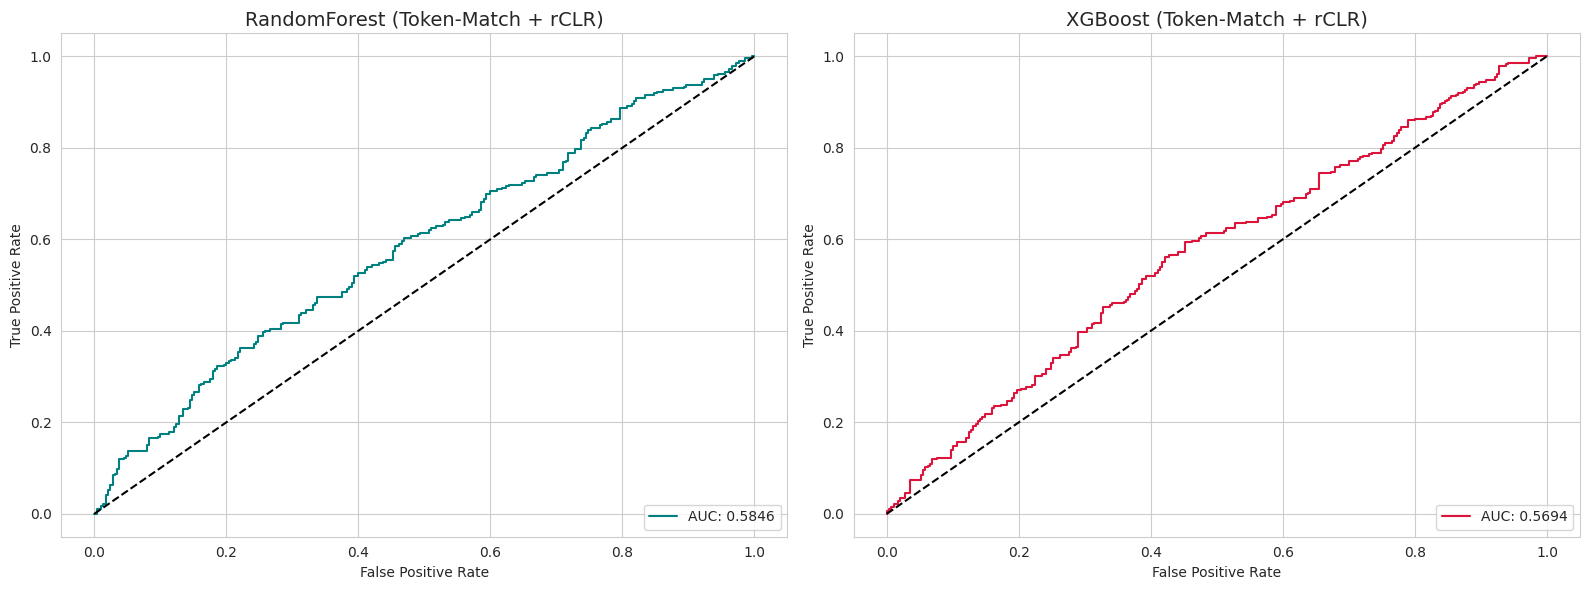

In [35]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, auc
import matplotlib.pyplot as plt
import re
from scipy.stats import gmean

# ==========================================
# 1. Define rCLR (Robust Centered Log-Ratio)
# ==========================================
def apply_rclr(df):
    mat = df.values.copy()
    rclr_mat = np.zeros_like(mat, dtype=float)
    for i in range(mat.shape[0]):
        row = mat[i, :]
        positive_mask = row > 0
        if np.any(positive_mask):
            geom_mean = gmean(row[positive_mask])
            rclr_mat[i, positive_mask] = np.log(row[positive_mask] / geom_mean)
    return pd.DataFrame(rclr_mat, index=df.index, columns=df.columns)

# 2. Token-Based Feature Extraction
def get_core_tokens(name):
    name = name.lower().replace('_', ' ').replace('[', ' ').replace(']', ' ')
    tokens = re.findall(r'[a-z]{3,}', name)
    garbage = {'bacteria', 'ref', 'motu', 'unknown', 'sp', 'noname', 'taxon', 'd__', 'p__', 'c__', 'o__', 'f__', 'g__', 's__'}
    return set(t for t in tokens if t not in garbage)

print("Mapping features via shared tokens...")
yachida_token_map = {col: get_core_tokens(col) for col in df_species_counts.columns}
# Ensure X_val_raw is available from previous alignment cell
wirbel_token_map = {col: get_core_tokens(col) for col in df_wirbel_final.columns if col not in ['Label', 'Sample_ID', 'SID_key', 'Stage', 'Stage_norm']}

shared_mapping = {}
for y_col, y_tokens in yachida_token_map.items():
    if len(y_tokens) < 2: continue
    for w_col, w_tokens in wirbel_token_map.items():
        if len(y_tokens.intersection(w_tokens)) >= 2:
            shared_mapping[y_col] = w_col
            break

matched_y = list(shared_mapping.keys())
matched_w = [shared_mapping[k] for k in matched_y]
print(f"Success: Matched {len(matched_y)} features using Token-Similarity.")

if len(matched_y) > 0:
    # 3. Data Preparation and rCLR
    X_tr_matched = df_species_counts[matched_y]
    # Using df_wirbel_final which was prepared in cell 91269587
    X_va_matched = df_wirbel_final[matched_w]
    X_va_matched.columns = matched_y

    # Align target labels (y_early from Step 1.1 and Label from Wirbel)
    y_train_final = y_early.loc[X_tr_matched.index]
    y_val_final = df_wirbel_final['Label']

    X_tr_final = apply_rclr(X_tr_matched)
    X_va_final = apply_rclr(X_va_matched)

    # 4. Model Training: RF & XGBoost
    models = {
        'RandomForest': RandomForestClassifier(n_estimators=200, max_depth=3, min_samples_leaf=5, random_state=42),
        'XGBoost': xgb.XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.05, subsample=0.8, random_state=42, eval_metric='logloss', colsample_bytree=0.3)
    }

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    for i, (name, clf) in enumerate(models.items()):
        clf.fit(X_tr_final, y_train_final)
        probs = clf.predict_proba(X_va_final)[:, 1]
        auc_val = roc_auc_score(y_val_final, probs)
        fpr, tpr, _ = roc_curve(y_val_final, probs)

        axes[i].plot(fpr, tpr, color='teal' if name == 'RandomForest' else 'crimson', label=f'AUC: {auc_val:.4f}')
        axes[i].plot([0, 1], [0, 1], 'k--')
        axes[i].set_title(f"{name} (Token-Match + rCLR)", fontsize=14)
        axes[i].set_xlabel('False Positive Rate')
        axes[i].set_ylabel('True Positive Rate')
        axes[i].legend(loc='lower right')
        print(f"{name} Cross-Cohort AUC: {auc_val:.4f}")

    plt.tight_layout()
    plt.show()
else:
    print("Token alignment failed.")

### 1.7 Feature Alignment Details: Token-Similarity Mapping Table
The table below displays the top 20 of the 323 successfully matched features, including their original classification strings and the extracted core tokens.

In [36]:
import pandas as pd
from IPython.display import display as ipy_display

# Construct a list of reference data
mapping_details = []
for y_feat, w_feat in shared_mapping.items():
    y_tokens = yachida_token_map[y_feat]
    w_tokens = wirbel_token_map[w_feat]
    shared = y_tokens.intersection(w_tokens)

    mapping_details.append({
        'Yachida_Feature (GTDB)': y_feat.split(';')[-1],
        'Wirbel_Feature (mOTU)': w_feat,
        'Shared_Tokens': list(shared),
        'Match_Confidence': len(shared)
    })

# Convert to a DataFrame and display it
df_mapping_audit = pd.DataFrame(mapping_details)

print(f"Total aligned features: {len(df_mapping_audit)}")
print("Top 20 Aligned Feature Pairs:")
# Use the renamed `ipy_display` to avoid conflicts with `RocCurveDisplay` instances.
ipy_display(df_mapping_audit.sort_values('Match_Confidence', ascending=False).head(20))

Total aligned features: 326
Top 20 Aligned Feature Pairs:


,Yachida_Feature (GTDB),Wirbel_Feature (mOTU),Shared_Tokens,Match_Confidence
325,s__UBA2598 sp002339345,Firmicutes bacterium ADurb.Bin467 [meta_mOTU_v...,"[firmicutes, bin]",2
0,s__Clostridium butyricum_B,Clostridium butyricum [ref_mOTU_v2_0978],"[butyricum, clostridium]",2
1,s__Mailhella massiliensis,Mailhella massiliensis [meta_mOTU_v2_5632],"[mailhella, massiliensis]",2
2,s__Bacteroides thetaiotaomicron,Bacteroides thetaiotaomicron [ref_mOTU_v2_0897],"[thetaiotaomicron, bacteroides]",2
3,s__Collinsella aerofaciens_W,Collinsella aerofaciens [ref_mOTU_v2_1383],"[aerofaciens, collinsella]",2
4,s__Megamonas funiformis,Megamonas funiformis/rupellensis [ref_mOTU_v2_...,"[megamonas, funiformis]",2
286,s__Streptococcus sanguinis_G,Streptococcus sanguinis [ref_mOTU_v2_0279],"[sanguinis, streptococcus]",2
287,s__Streptococcus australis_A,Streptococcus australis [ref_mOTU_v2_1524],"[australis, streptococcus]",2
288,s__Streptococcus oralis_Q,Streptococcus oralis [ref_mOTU_v2_0356],"[streptococcus, oralis]",2
289,s__Streptococcus oralis_W,Streptococcus oralis [ref_mOTU_v2_0356],"[streptococcus, oralis]",2


In [37]:
matched_early = [f for f in surrogate_features_early if f in shared_mapping]
matched_late = [f for f in surrogate_features_late if f in shared_mapping]

print("=== Alignment results for core feature token matching ===")
print(f"Successful alignment of early core features (Top 25):{len(matched_early)} ")
print(f"Successful alignment of key late-stage characteristics (Top 25): {len(matched_late)} ")

print("\n[Early Stage] Specific core species successfully aligned:")
for i, feat in enumerate(matched_early):
    print(f"{i+1}. {feat.split('s__')[-1]}")

print("\n[Late stage] Specific core species successfully aligned:")
for i, feat in enumerate(matched_late):
    print(f"{i+1}. {feat.split('s__')[-1]}")

=== Alignment results for core feature token matching ===
Successful alignment of early core features (Top 25):3 
Successful alignment of key late-stage characteristics (Top 25): 7 

[Early Stage] Specific core species successfully aligned:
1. Alloprevotella tannerae
2. Streptococcus australis_B
3. Peptostreptococcus stomatis

[Late stage] Specific core species successfully aligned:
1. Gemella morbillorum
2. Peptostreptococcus stomatis
3. Fusobacterium nucleatum_J
4. Parvimonas micra
5. Enterococcus_B hirae
6. Streptococcus mutans
7. Holdemania massiliensis


## 2. Parsimonious Models - Independent Validation)
We split the successfully aligned features in the core Top 25 into two independent models for testing:
1. **Early model**: Using 3 core alignment features.
2. **Late Model**: Using 7 core alignment features.

(selected from the top 25 in the Yachida core set).

 We will train separate XGBoost and Random Forest models for these sets and perform cross-validation.

 External Validation+ Feature Validation



### 2.1 External Validation

Train on Yachida+ Test on Wirbel

Processing Early Stage Parsimonious Model...


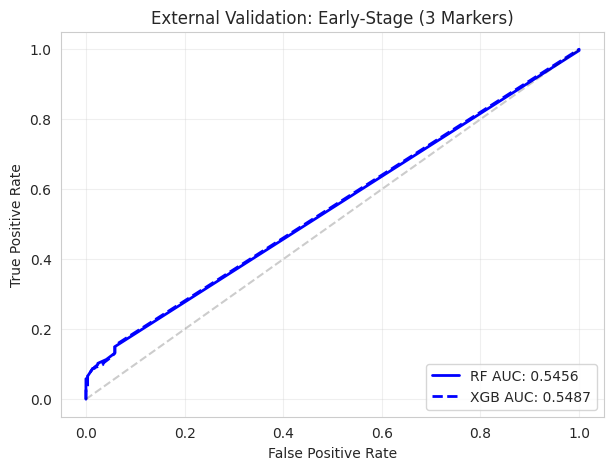

--- Early-Stage Model Summary ---
Features: ['Alloprevotella tannerae', 'Streptococcus australis_B', 'Peptostreptococcus stomatis']
RF AUC: 0.5456
XGB AUC: 0.5487

Processing Late Stage Parsimonious Model...


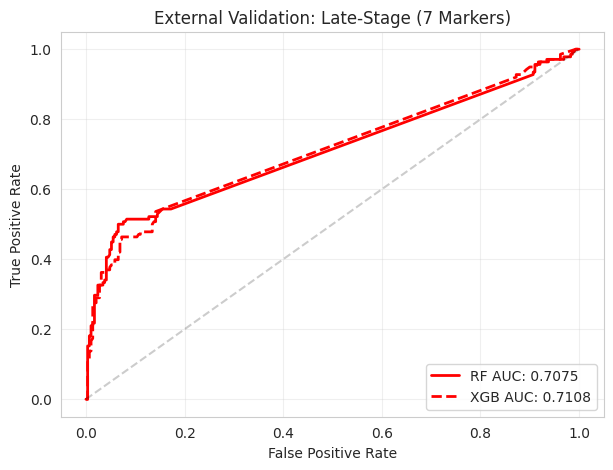

--- Late-Stage Model Summary ---
Features: ['Gemella morbillorum', 'Peptostreptococcus stomatis', 'Fusobacterium nucleatum_J', 'Parvimonas micra', 'Enterococcus_B hirae', 'Streptococcus mutans', 'Holdemania massiliensis']
RF AUC: 0.7075
XGB AUC: 0.7108



In [40]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, auc
import matplotlib.pyplot as plt

# ==========================================
# 0. Fix: Prepare Training and Validation Data
# ==========================================

# Prepare Training Data (Yachida)
# X_tr_early_final and X_tr_late_final use apply_rclr on matched subsets
X_tr_early_final = apply_rclr(df_species_counts.loc[y_early.index, matched_early])
y_train_early = y_early

X_tr_late_final = apply_rclr(df_species_counts.loc[y_late.index, matched_late])
y_train_late = y_late

# Prepare Validation Data (Wirbel)
# Based on logic from dL3Wpxlj2tn9 to ensure variables are defined
is_early_va = (df_wirbel_final['Label'] == 0) | (df_wirbel_final['Stage_norm'].str.contains('I|II|1|2|EARLY', na=False))
df_wirbel_early = df_wirbel_final[is_early_va]
X_va_early_full = df_wirbel_early[matched_w]
X_va_early_full.columns = matched_y
y_val_early = df_wirbel_early['Label']

is_late_va = (df_wirbel_final['Label'] == 0) | (df_wirbel_final['Stage_norm'].str.contains('III|IV|3|4|LATE', na=False))
df_wirbel_late = df_wirbel_final[is_late_va]
X_va_late_full = df_wirbel_late[matched_w]
X_va_late_full.columns = matched_y
y_val_late = df_wirbel_late['Label']

# Apply rclr to the specific features being validated
X_va_early_final = apply_rclr(X_va_early_full[matched_early])
X_va_late_final = apply_rclr(X_va_late_full[matched_late])

def run_strict_parsimonious_val(features, y_train, X_train_full, y_val, X_val_full, stage_label, color):
    # Extract features (already subsetted and rclr-transformed above)
    X_tr = X_train_full
    X_va = X_val_full

    # 1. RF
    rf_model = RandomForestClassifier(
        n_estimators=300,
        max_depth=3,
        class_weight='balanced',
        random_state=42
    )
    rf_model.fit(X_tr, y_train)
    rf_probs = rf_model.predict_proba(X_va)[:, 1]
    rf_auc = roc_auc_score(y_val, rf_probs)

    # 2. XGBoost
    xgb_model = xgb.XGBClassifier(
        n_estimators=100,
        max_depth=2,
        learning_rate=0.05,
        subsample=0.8,
        random_state=42,
        eval_metric='logloss'
    )
    xgb_model.fit(X_tr, y_train)
    xgb_probs = xgb_model.predict_proba(X_va)[:, 1]
    xgb_auc = roc_auc_score(y_val, xgb_probs)

    # plot
    plt.figure(figsize=(7, 5))
    fpr_rf, tpr_rf, _ = roc_curve(y_val, rf_probs)
    fpr_xgb, tpr_xgb, _ = roc_curve(y_val, xgb_probs)

    plt.plot(fpr_rf, tpr_rf, color=color, lw=2, label=f'RF AUC: {rf_auc:.4f}')
    plt.plot(fpr_xgb, tpr_xgb, color=color, linestyle='--', lw=2, label=f'XGB AUC: {xgb_auc:.4f}')
    plt.plot([0, 1], [0, 1], 'k--', alpha=0.2)
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'External Validation: {stage_label} ({len(features)} Markers)')
    plt.legend(loc='lower right')
    plt.grid(alpha=0.3)
    plt.show()

    print(f"--- {stage_label} Model Summary ---")
    print(f"Features: {[f.split('s__')[-1] for f in features]}")
    print(f"RF AUC: {rf_auc:.4f}")
    print(f"XGB AUC: {xgb_auc:.4f}\n")
    return {'rf_auc': rf_auc, 'xgb_auc': xgb_auc}

# Execute early-stage validation
print("Processing Early Stage Parsimonious Model...")
early_results = run_strict_parsimonious_val(
    matched_early, y_train_early, X_tr_early_final,
    y_val_early, X_va_early_final, "Early-Stage", "blue"
)

# Execute Late-Stage Validation
print("Processing Late Stage Parsimonious Model...")
late_results = run_strict_parsimonious_val(
    matched_late, y_train_late, X_tr_late_final,
    y_val_late, X_va_late_final, "Late-Stage", "red"
)

### 2.2 Feature Validation
train + test all on Wirbel dataset

In [41]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb

# ==========================================
# 1. Data Preparation
# ==========================================
print("Preparing Wirbel datasets for Early and Late stages...")

if 'df_wirbel_final' not in locals():
    print("Error: df_wirbel_final not found. Please ensure the alignment and merging cells have been executed.")
else:
    # Early-stage validation set: Healthy controls (Label=0) + Early-stage cancer (Stage I, II)
    is_early = (df_wirbel_final['Label'] == 0) | (df_wirbel_final['Stage_norm'].str.contains('I|II|1|2|EARLY', na=False))
    df_wirbel_early = df_wirbel_final[is_early]

    # Extract the previously aligned Wirbel feature columns (matched_w).
    X_va_early_full = df_wirbel_early[matched_w]
    X_va_early_full.columns = matched_y # Map back to Yachida feature names to match the model.
    y_val_early = df_wirbel_early['Label']

    # Late-stage validation set: Healthy controls (Label=0) + Late-stage cancer (Stage III, IV)
    is_late = (df_wirbel_final['Label'] == 0) | (df_wirbel_final['Stage_norm'].str.contains('III|IV|3|4|LATE', na=False))
    df_wirbel_late = df_wirbel_final[is_late]
    X_va_late_full = df_wirbel_late[matched_w]
    X_va_late_full.columns = matched_y
    y_val_late = df_wirbel_late['Label']

    print(f"Early Dataset: {len(df_wirbel_early)} samples (CTR + Stage I/II)")
    print(f"Late Dataset: {len(df_wirbel_late)} samples (CTR + Stage III/IV)\n")

    # ==========================================
    # 2. Define the Feature Validation (Wirbel internal CV) function.
    # ==========================================
    def run_feature_validation_cv(features, X_val_subset, y_val_subset, stage_label):
        """
        Perform 5-fold cross-validation within the target validation set (Wirbel)
to evaluate the upper-bound potential of the extracted shared features in the local European population.
        """
        # rCLR
        X_sub = apply_rclr(X_val_subset[features])

        rf_cv = RandomForestClassifier(
            n_estimators=300, max_depth=3, class_weight='balanced', random_state=42
        )
        xgb_cv = xgb.XGBClassifier(
            n_estimators=100, max_depth=2, learning_rate=0.05,
            subsample=0.8, random_state=42, eval_metric='logloss'
        )

        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

        rf_scores = cross_val_score(rf_cv, X_sub, y_val_subset, cv=cv, scoring='roc_auc')
        xgb_scores = cross_val_score(xgb_cv, X_sub, y_val_subset, cv=cv, scoring='roc_auc')

        print(f"=== {stage_label} Internal CV (Wirbel Only) ===")
        print(f"RF Mean AUC:  {np.mean(rf_scores):.4f} (+/- {np.std(rf_scores):.4f})")
        print(f"XGB Mean AUC: {np.mean(xgb_scores):.4f} (+/- {np.std(xgb_scores):.4f})\n")

        return {
            'Stage': stage_label,
            'RF_Local_CV_AUC': np.mean(rf_scores),
            'XGB_Local_CV_AUC': np.mean(xgb_scores)
        }

    # ==========================================
    # 3. Run verification and summarize the results.
    # ==========================================
    print("Starting Feature Validation (Local Potential on European Cohort)...\n")

    early_feature_val = run_feature_validation_cv(
        matched_early, X_va_early_full, y_val_early, "Early-Stage (3 Markers)"
    )

    late_feature_val = run_feature_validation_cv(
        matched_late, X_va_late_full, y_val_late, "Late-Stage (7 Markers)"
    )

    df_feature_val_summary = pd.DataFrame([early_feature_val, late_feature_val])
    print("--- European Cohort Feature Potential Summary ---")
    display(df_feature_val_summary)

Preparing Wirbel datasets for Early and Late stages...
Early Dataset: 563 samples (CTR + Stage I/II)
Late Dataset: 428 samples (CTR + Stage III/IV)

Starting Feature Validation (Local Potential on European Cohort)...

=== Early-Stage (3 Markers) Internal CV (Wirbel Only) ===
RF Mean AUC:  0.6512 (+/- 0.0204)
XGB Mean AUC: 0.6556 (+/- 0.0340)

=== Late-Stage (7 Markers) Internal CV (Wirbel Only) ===
RF Mean AUC:  0.7448 (+/- 0.0254)
XGB Mean AUC: 0.7326 (+/- 0.0328)

--- European Cohort Feature Potential Summary ---


,Stage,RF_Local_CV_AUC,XGB_Local_CV_AUC
0,Early-Stage (3 Markers),0.651178,0.655562
1,Late-Stage (7 Markers),0.744841,0.732610
